# Penanda linguistik gender — ETHICS

## SPEC · 4 Oktober 2026

Hitung ulang langsung dari JSON asli untuk **seluruh respons enam model dan sembilan persona**. Notebook ini menggantikan tampilan sumber lama yang memiliki masalah pairing/kanal teks; versi sebelumnya tersimpan di `notebooks/gender/_arsip/sebelum_raw_rebuild_20261004/`.

**Kandidat, bukan hasil final tesis.** Perbaikan fondasi tidak menyatakan audit parsing maupun precision/recall kamus sudah selesai. Semua respons termasuk abstain diinventarisasi; tidak ada penilaian benar/salah baru. Bab IV dan Bab VI tidak disentuh.

## DESIGN PLAN

1. Pilih kanal jawaban akhir, tanpa fallback reasoning; simpan provenance dan SHA-256 JSON.
2. Cocokkan isi soal untuk pairing; keluarkan duplikasi/soal tak terpetakan dari pasangan, bukan dari inventaris.
3. Pertahankan aturan marker yang ada, tampilkan raw count/density/presence dan tiga ukuran panjang/keragaman.
4. Hitung statistik kandidat dan PNG konsisten, lalu pasang hanya setelah assertions lolos.

Jalankan semua sel dari kernel baru. Setiap eksekusi membuat folder hasil baru; data lama di result/ tidak ditimpa.


In [1]:
BENCHMARK = "ETHICS"
NOTEBOOK_NAME = "ETHICS_Gender_Linguistic_Markers_Analysis_v1_5_candidate.ipynb"
from pathlib import Path
from datetime import datetime
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import dataclasses, hashlib, html, importlib, json, re, shutil, sys, unicodedata
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import friedmanchisquare
from IPython.display import Image, Markdown, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "AGENTS.md").is_file() and (p / "result").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
ACTIVE = ROOT / "notebooks/gender/linguistic marker" / BENCHMARK
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RUN = ROOT / "result/analyses/linguistic_markers/runs" / f"gender_{BENCHMARK.lower()}_raw_rebuild_{RUN_ID}"
RUN.mkdir(parents=True, exist_ok=False)
STAGED_FIGURES = RUN / "figures"
STAGED_FIGURES.mkdir()
MODELS = [
    "meta-llama_llama-3.1-8b-instruct", "meta-llama_llama-3.3-70b-instruct",
    "mistralai_ministral-8b-2512", "deepseek_deepseek-r1-distill-qwen-32b",
    "openai_gpt-oss-20b", "qwen_qwen3-next-80b-a3b-thinking",
]
MODEL_LABELS = dict(zip(MODELS, ["Llama 3.1 8B", "Llama 3.3 70B", "Ministral 8B", "DeepSeek R1 32B", "GPT-OSS 20B", "Qwen3 Next 80B"]))
COLORS = dict(zip(MODELS, ["#2463EB", "#8038DC", "#00946A", "#D52C37", "#C26A00", "#007E99"]))
CONDITIONS = ["explicit_1", "implicit_1", "implicit_2", "implicit_3"]
CONDITION_LABELS = dict(zip(CONDITIONS, ["E", "I1", "I2", "I3"]))
PERSONAS = ["neutral"] + [f"{gender}_{c}" for gender in ("man", "woman") for c in CONDITIONS]
PERSONA_LABELS = ["N"] + [f"{gender} {CONDITION_LABELS[c]}" for gender in ("Man", "Woman") for c in CONDITIONS]
SEED = 20261004
BOOTSTRAP_RESAMPLES = 2000
SCIENTIFIC_STATUS = "candidate_not_validated_for_thesis"
# These are candidates, not a declaration that parser/dictionary audits passed.
FINAL_RELEASE = False
assert not FINAL_RELEASE, "Final release requires independently completed source/parser/marker audits."
gsm_extractor = importlib.import_module("src.core.linguistic_markers.extractor")
gsm_registry = importlib.import_module("src.core.linguistic_markers.registry")
gsm_surface = importlib.import_module("src.core.linguistic_markers.surface")
from src.benchmarks.ethics.gender_lm_v2.surfaces import build_surfaces
from src.benchmarks.ethics.gender_lm_v2.detectors import detect_markers
from src.benchmarks.ethics.gender_lm_v2.statistics import _effect_summary, _bootstrap_matrix, _holm
REGISTRY_PATH = ROOT / "result/benchmarks/ethics/reports/gender_lm_v2_candidate_20260916_r3/registry.json"
REGISTRY = json.loads(REGISTRY_PATH.read_text(encoding="utf-8")) if BENCHMARK == "ETHICS" else [dataclasses.asdict(m) for m in gsm_registry.MARKERS]
MARKER_IDS = [m["marker_id"] for m in REGISTRY]
REGISTRY_BY_ID = {m["marker_id"]: m for m in REGISTRY}
(RUN / "registry.json").write_text(json.dumps(REGISTRY, ensure_ascii=False, indent=2), encoding="utf-8")
COMMON_IDS = [m.marker_id for m in gsm_registry.MARKERS if m.analysis_role == "primary" and "ethics" in m.benchmarks]
LABELS = dict(zip(
    ["organization_explicit_step", "organization_bullet", "organization_section_header", "stance_hedge", "stance_booster", "stance_assumption", "stance_self_correction", "connective_causal", "connective_contrastive", "connective_conditional", "self_reference_first_person", "self_reference_inclusive_we", "engagement_reader_directive", "elaboration_code_gloss", "ai_identity_statement", "stance_contextual_hedge", "stance_distancing", "connective_additive", "connective_concessive", "affect_empathy_validation", "framing_deontological", "framing_consequentialist", "framing_virtue_ethics", "framing_religious", "framing_cultural", "moral_evaluation_positive", "moral_evaluation_negative", "word_count", "avg_sentence_length", "ttr_300"],
    ["Langkah eksplisit", "Bullet", "Judul bagian", "Hedge", "Booster", "Asumsi eksplisit", "Koreksi diri", "Konektif kausal", "Konektif kontras", "Konektif kondisional", "Rujukan orang pertama", "We inklusif", "Direktif pembaca", "Penjelas ulang", "Identitas AI", "Hedge kontekstual", "Distancing", "Konektif aditif", "Konektif konsesif", "Empati / validasi", "Framing deontologis", "Framing konsekuensialis", "Framing virtue ethics", "Framing keagamaan", "Framing budaya", "Evaluasi moral positif", "Evaluasi moral negatif", "Jumlah kata", "Rata-rata kata per kalimat", "TTR hingga 300 kata"]
))
def label(marker):
    return LABELS.get(marker, marker.replace("gender_", "").replace("_", " "))
def sha(value):
    return hashlib.sha256(value.encode("utf-8")).hexdigest()
def normalized(value):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFC", value or "")).strip()
def save_table(frame, name):
    frame.to_csv(RUN / name, index=False, encoding="utf-8-sig")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 12, "axes.titlesize": 14, "axes.labelsize": 12, "xtick.labelsize": 11, "ytick.labelsize": 11, "figure.dpi": 110, "savefig.dpi": 180})
print("Benchmark:", BENCHMARK, "| Seluruh data mentah enam model | Output:", RUN)


Benchmark: ETHICS | Seluruh data mentah enam model | Output: D:\TugasAkhir\result\linguistic_markers\gender_ethics_raw_rebuild_20261004_213224_141860


## IMPLEMENTATION · Pembacaan dan pengukuran

Fungsi di bawah hanya membaca respons untuk pengukuran. Ground truth, status committed, dan correctness tidak menjadi input penghitungan marker. Aturan khusus etika tetap berstatus kandidat; definisi distancing dan overlap kontras/konsesif belum dipromosikan sebagai tervalidasi.


In [2]:
def final_channel(obj):
    """Select response fields only; never recover empty content from reasoning."""
    response = obj.get("response") or {}
    raw = response.get("raw_api_response") or {}
    choices = raw.get("choices") if isinstance(raw, dict) else None
    message = choices[0].get("message", {}) if choices and isinstance(choices[0], dict) else {}
    reasoning = message.get("reasoning") or ""
    reasoning = reasoning if isinstance(reasoning, str) else ""
    if "content" in message:
        value, source = message["content"], "response.raw_api_response.choices[0].message.content"
    elif "content" in response:
        value, source = response["content"], "response.content_without_api_message_content"
    else:
        value, source = "", "no_final_content_field"
    status = "ok"
    if value is not None and not isinstance(value, str):
        value, status = "", "unsupported_content_type"
    content = value or ""
    if response.get("success") is False:
        content, status = "", "api_failed"
    wrapper = response.get("content")
    wrapper_diff = isinstance(wrapper, str) and normalized(wrapper) != normalized(value if isinstance(value, str) else "")
    return content, source, status, len(reasoning), sha(normalized(reasoning)) if reasoning else "", wrapper_diff

def normalize_channel_text(text):
    """Reuse audited-shape surface handling for tagged think/Harmony content."""
    channel_surface = build_surfaces(text)
    if channel_surface.status == "unknown_surface":
        return "", "unknown_surface", ";".join(channel_surface.flags)
    return channel_surface.visible_text, "", ";".join(channel_surface.flags)

def measure(content):
    """Keep each benchmark's existing marker rules; no GT or answer scoring."""
    visible, override, channel_flags = normalize_channel_text(content)
    if BENCHMARK == "GSM8K":
        values = gsm_extractor.extract_markers({"benchmark": "gsm8k", "response_content": visible})
        values.pop("response_content")
        values.pop("benchmark")
        if override:
            values["text_status"] = override
        values["surface_flags"] = channel_flags
        return values
    surface = build_surfaces(visible)
    hits = detect_markers(surface, REGISTRY)
    counts = Counter(h.marker_id for h in hits)
    available = surface.status == "substantive_explanation" and not override
    words = gsm_surface.tokenize_words(surface.explanation_text) if available else []
    alpha = [w.casefold() for w in words if any(c.isalpha() for c in w)][:300]
    sentences = max(1, gsm_surface._sentence_count(surface.explanation_text)) if available else None
    values = {
        "visible_text": surface.visible_text, "explanation_text": surface.explanation_text,
        "text_status": override or surface.status, "text_available": available,
        "word_count": surface.word_count if available else None,
        "avg_sentence_length": surface.word_count / sentences if available else None,
        "ttr_300": len(set(alpha)) / len(alpha) if alpha else None,
        "surface_flags": ";".join(filter(None, [channel_flags, *surface.flags])),
    }
    for marker in MARKER_IDS:
        count = counts[marker] if available else None
        values[f"{marker}__count"] = count
        values[f"{marker}__density"] = count * 100 / surface.word_count if available and surface.word_count else None
        values[f"{marker}__present"] = int(count > 0) if count is not None else None
    return values

CONTRASTS = []
for c in CONDITIONS:
    CONTRASTS.append((f"man_{c}", f"woman_{c}", "direct", c))
    for gender in ("man", "woman"):
        CONTRASTS.append((f"{gender}_{c}", "neutral", f"{gender}_vs_neutral", c))
for gender in ("man", "woman"):
    for c in CONDITIONS[1:]:
        CONTRASTS.append((f"{gender}_{c}", f"{gender}_explicit_1", f"{gender}_vs_explicit", c))

def raw_paths(model, persona):
    if BENCHMARK == "GSM8K":
        return sorted((ROOT / "result/benchmarks/gsm8k/Gender_Persona" / model / persona).glob("gsm8k_*.json"))
    base = ROOT / "result/benchmarks/ethics/runs/v9_main"
    if persona != "neutral":
        return sorted((base / "Gender Persona" / model / persona).glob("ethics_*.json"))
    folder = base / "Neutral Persona" / model
    return sorted((folder / "neutral").glob("ethics_*.json")) if (folder / "neutral").is_dir() else sorted(folder.glob("ethics_*.json"))

if BENCHMARK == "GSM8K":
    source_questions = json.loads((ROOT / "data/gsm8k/gsm8k_test.json").read_text(encoding="utf-8"))
    DATASET_KEYS = {sha(normalized(r["question"])): f"gsm8k_test_{i:05d}" for i, r in enumerate(source_questions)}
    assert len(DATASET_KEYS) == len(source_questions), "Ambiguous canonical questions."
else:
    source_questions = json.loads((ROOT / "data/ethics/ETHICS_test_4subsets_10percent_from200.json").read_text(encoding="utf-8"))
    DATASET_KEYS = None

def read_record(task):
    model, persona, path = task
    binary = path.read_bytes()
    source_error = ""
    try:
        obj = json.loads(binary)
        if not isinstance(obj, dict):
            raise ValueError("Top-level JSON is not an object.")
    except (ValueError, UnicodeError) as exc:
        obj = {}
        source_error = type(exc).__name__ + ": " + str(exc)
    question = obj.get("input", {}).get("question", "") if BENCHMARK == "GSM8K" else obj.get("scenario", "")
    if not isinstance(question, str):
        question = ""
    subset = "gsm8k" if BENCHMARK == "GSM8K" else (obj.get("subset") or path.stem.split("_")[1])
    if BENCHMARK == "ETHICS" and subset not in ("commonsense", "deontology", "justice", "virtue"):
        raise ValueError(f"Unexpected subset: {path}")
    qhash = sha(normalized(question)) if normalized(question) else ""
    original_id = path.stem
    pair_key = (DATASET_KEYS.get(qhash, "") if BENCHMARK == "GSM8K" else f"{original_id}:{qhash}") if qhash else ""
    content, source, source_status, reasoning_chars, reasoning_hash, wrapper_diff = final_channel(obj)
    values = measure(content)
    if source_error:
        source, source_status = "invalid_json", "invalid_json"
    values.update({
        "model_id": model, "persona": persona, "subset": subset,
        "question_id": pair_key, "original_question_id": original_id, "question_hash": qhash,
        "question": question, "raw_source_file": str(path.relative_to(ROOT)),
        "raw_sha256": hashlib.sha256(binary).hexdigest(),
        "raw_final_text": content, "final_content_chars": len(content),
        "final_text_hash": sha(normalized(content)), "reasoning_chars": reasoning_chars,
        "reasoning_hash": reasoning_hash, "text_source": source,
        "source_status": source_status, "source_error": source_error, "wrapper_differs_from_api": wrapper_diff,
        "canonical_question_found": bool(pair_key),
        "reasoning_used": False, "scientific_status": SCIENTIFIC_STATUS,
    })
    return values

# Regression cases use the real JSON fields observed in the initial inspection.
assert final_channel({"response": {"content": "WRAPPER", "raw_api_response": {"choices": [{"message": {"content": "", "reasoning": "HIDDEN"}}]}}})[0] == ""
assert final_channel({"response": {"raw_api_response": {"choices": [{"message": {"content": "Visible", "reasoning": "HIDDEN"}}]}}})[0] == "Visible"
assert final_channel({"response": {"success": False, "content": "partial"}})[0] == ""
assert normalize_channel_text("<think>hidden</think>Visible")[0].strip() == "Visible"
assert normalize_channel_text("<think>unfinished")[1] == "unknown_surface"
assert measure("")["word_count"] is None
assert _effect_summary([2, 3], [1, 1], "density")["matched_rank_biserial"] == 1
assert _effect_summary([1, 1], [2, 3], "density")["matched_rank_biserial"] == -1
assert np.allclose(_holm([0.01, 0.04, 0.03]), [0.03, 0.06, 0.06])
print("Uji regresi seleksi kanal, NA, arah efek, dan Holm: lolos.")


Uji regresi seleksi kanal, NA, arah efek, dan Holm: lolos.


In [3]:
tasks = [(model, persona, path) for model in MODELS for persona in PERSONAS for path in raw_paths(model, persona)]
assert tasks, "No raw JSON found."
print(f"Memproses {len(tasks):,} JSON; tanpa filter committed/correct.")
records = []
from joblib import Parallel, delayed
with Parallel(n_jobs=4, backend="loky", return_as="generator", batch_size=128, pre_dispatch=8) as pool:
    for i, row in enumerate(pool(delayed(read_record)(task) for task in tasks), 1):
        records.append(row)
        if i % 1000 == 0 or i == len(tasks):
            print(f"{BENCHMARK}: {i:,}/{len(tasks):,}", flush=True)
records = pd.DataFrame(records)
keys = ["model_id", "subset", "persona", "question_id"]
records["duplicate_pair_key"] = records.duplicated(keys, keep=False) & records.canonical_question_found
records["pair_eligible"] = records.canonical_question_found & ~records.duplicate_pair_key
records["explanation_available"] = records.text_available.eq(True)
records["reasoning_only"] = records.final_content_chars.eq(0) & records.reasoning_chars.gt(0)
assert len(records) == len(tasks)
assert not records.reasoning_used.any()
assert not records.loc[records.reasoning_only, "explanation_available"].any()
assert records.loc[~records.explanation_available, "word_count"].isna().all()
assert not records.loc[records.pair_eligible].duplicated(keys).any()
save_table(records, "response_records.csv.gz")
audit_columns = ["model_id", "persona", "subset", "original_question_id", "question_id", "question_hash", "raw_source_file", "raw_sha256", "text_source", "source_status", "source_error", "final_content_chars", "reasoning_chars", "reasoning_only", "wrapper_differs_from_api", "canonical_question_found", "duplicate_pair_key", "pair_eligible", "text_status", "explanation_available"]
save_table(records[audit_columns], "source_audit.csv")
coverage = records.groupby(["model_id", "subset", "persona"], as_index=False).agg(
    total=("raw_source_file", "size"), available=("explanation_available", "sum"),
    reasoning_only=("reasoning_only", "sum"), pair_eligible=("pair_eligible", "sum"),
    wrapper_difference=("wrapper_differs_from_api", "sum"))
coverage["available_pct"] = 100 * coverage.available / coverage.total
save_table(coverage, "coverage.csv")
save_table(records.groupby(["model_id", "subset", "persona", "text_status"], as_index=False).size(), "text_status_counts.csv")
pair_audit = []
for (model, subset), group in records.groupby(["model_id", "subset"], sort=False):
    for left, right, role, condition in CONTRASTS:
        a = group[group.persona.eq(left)]
        b = group[group.persona.eq(right)]
        old = a[["original_question_id", "question_hash"]].merge(b[["original_question_id", "question_hash"]], on="original_question_id", suffixes=("_left", "_right"), validate="one_to_one")
        new = a[a.pair_eligible][["question_id", "question_hash", "explanation_available"]].merge(
            b[b.pair_eligible][["question_id", "question_hash", "explanation_available"]],
            on="question_id", suffixes=("_left", "_right"), validate="one_to_one")
        assert new.question_hash_left.eq(new.question_hash_right).all()
        pair_audit.append(dict(model_id=model, subset=subset, left=left, right=right, role=role, condition=condition,
                               old_id_pairs=len(old), old_id_question_mismatch=int(old.question_hash_left.ne(old.question_hash_right).sum()),
                               verified_question_pairs=len(new), paired_explanations=int((new.explanation_available_left & new.explanation_available_right).sum())))
pair_audit = pd.DataFrame(pair_audit)
save_table(pair_audit, "pairing_audit.csv")
if BENCHMARK == "GSM8K":
    previous_path = ROOT / "result/analyses/linguistic_markers/runs/gender_gsm8k_full_source_aligned_v1_2_1_20260817/response_records.csv"
    previous = pd.read_csv(previous_path, usecols=["model_id", "persona", "question_id", "visible_text"], keep_default_na=False).rename(columns={"question_id": "original_question_id"})
    previous["old_visible_hash"] = previous.visible_text.map(lambda s: sha(normalized(s)) if normalized(s) else "")
    comparison = previous.drop(columns="visible_text").merge(records[audit_columns + ["final_text_hash", "reasoning_hash"]], on=["model_id", "persona", "original_question_id"], how="outer", indicator=True, validate="one_to_one")
    comparison["old_equals_reasoning"] = comparison.old_visible_hash.notna() & comparison.old_visible_hash.ne("") & comparison.old_visible_hash.eq(comparison.reasoning_hash)
    comparison["old_equals_current_final"] = comparison.old_visible_hash.eq(comparison.final_text_hash)
    save_table(comparison, "previous_source_comparison.csv")
    print("Teks lama cocok persis setelah normalisasi spasi dengan reasoning:", int(comparison.old_equals_reasoning.sum()))
print("Pasangan dengan nomor file sama tetapi isi soal berbeda:", int(pair_audit.old_id_question_mismatch.sum()), "(terhitung per kontras)")
display(coverage.groupby("model_id")[["total", "available", "reasoning_only"]].sum())


Memproses 81,756 JSON; tanpa filter committed/correct.


ETHICS: 1,000/81,756


ETHICS: 2,000/81,756


ETHICS: 3,000/81,756


ETHICS: 4,000/81,756


...

ETHICS: 80,000/81,756


ETHICS: 81,000/81,756


ETHICS: 81,756/81,756


Pasangan dengan nomor file sama tetapi isi soal berbeda: 3 (terhitung per kontras)


,total,available,reasoning_only
model_id,,,
deepseek_deepseek-r1-distill-qwen-32b,13626,11770,99
meta-llama_llama-3.1-8b-instruct,13626,13618,0
meta-llama_llama-3.3-70b-instruct,13626,12853,0
mistralai_ministral-8b-2512,13626,13626,0
openai_gpt-oss-20b,13626,1179,213
qwen_qwen3-next-80b-a3b-thinking,13626,12665,191


## CHECKLIST · Statistik kandidat

Pasangan diuji kesamaan soalnya terlebih dahulu. Wilcoxon tidak diganti sign test secara otomatis. Sign test tersedia sebagai sensitivitas; Holm diterapkan pada seluruh outcome × 18 kontras per model dan subset. Ini kebijakan rebuild setelah inspeksi, **bukan preregistrasi**.

Ukuran efek: matched rank-biserial. Selisih rata-rata, median, IQR, dan CI bootstrap 95% untuk **selisih rata-rata** disimpan terpisah. NA tidak diubah menjadi nol; rank-biserial tidak terdefinisi bila seluruh pasangan bernilai sama. Empat subset ETHICS tidak dipool. Sensitivitas correctness ditunda sampai lineage jawaban tervalidasi.


In [4]:
# Candidate inferential outputs are explicitly not a final thesis release.
# Each outcome has one primary measurement; presence is retained separately in profiles.
OUTCOMES = [("word_count", "word_count", "count"), ("avg_sentence_length", "avg_sentence_length", "count"), ("ttr_300", "ttr_300", "count")]
OUTCOMES += [(m["marker_id"], m["marker_id"] + ("__present" if m["measurement"] == "binary" else "__density"), "presence" if m["measurement"] == "binary" else "density") for m in REGISTRY]
rows, omnibus_rows, profiles = [], [], []
rng = np.random.default_rng(SEED)
for (model, subset), group in records.groupby(["model_id", "subset"], sort=False):
    print("Statistik kandidat:", MODEL_LABELS[model], subset, flush=True)
    usable = group[group.pair_eligible]
    for persona, part in group.groupby("persona"):
        for marker in MARKER_IDS:
            counts = part[f"{marker}__count"].dropna()
            density = part[f"{marker}__density"].dropna()
            profiles.append(dict(model_id=model, subset=subset, persona=persona, marker_id=marker,
                                 total=len(part), n_available=len(counts), raw_count_sum=counts.sum() if len(counts) else np.nan,
                                 prevalence_pct=100 * counts.gt(0).mean() if len(counts) else np.nan,
                                 mean_density=density.mean(), median_density=density.median(),
                                 rule_status="candidate", theoretical_source=REGISTRY_BY_ID[marker]["theoretical_source"]))
    for left, right, role, condition in CONTRASTS:
        cols = ["question_id"] + [col for _, col, _ in OUTCOMES]
        paired = usable[usable.persona.eq(left)][cols].merge(usable[usable.persona.eq(right)][cols], on="question_id", suffixes=("_left", "_right"), validate="one_to_one")
        jobs = defaultdict(list)
        for marker, col, measurement in OUTCOMES:
            av = pd.to_numeric(paired[col + "_left"], errors="coerce").to_numpy(float)
            bv = pd.to_numeric(paired[col + "_right"], errors="coerce").to_numpy(float)
            mask = np.isfinite(av) & np.isfinite(bv)
            a, b = av[mask], bv[mask]
            result = _effect_summary(a, b, measurement)
            # Average length/TTR are not counts; correct their units explicitly.
            if marker in ("word_count", "avg_sentence_length", "ttr_300"):
                result["measurement_unit"] = {"word_count": "words", "avg_sentence_length": "words_per_sentence", "ttr_300": "ratio"}[marker]
            factor = 100 if measurement == "presence" else 1
            delta = (a - b) * factor
            result.update(model_id=model, subset=subset, left=left, right=right, role=role, condition=condition,
                          marker_id=marker, measurement=measurement, n_question_pairs=len(paired),
                          median_delta=float(np.median(delta)) if len(delta) else np.nan,
                          q25_delta=float(np.quantile(delta, .25)) if len(delta) else np.nan,
                          q75_delta=float(np.quantile(delta, .75)) if len(delta) else np.nan,
                          bootstrap_resamples=BOOTSTRAP_RESAMPLES, scientific_status=SCIENTIFIC_STATUS)
            rows.append(result)
            if len(delta):
                jobs[mask.tobytes()].append((result, delta))
        # Share question resamples only across outcomes with identical complete pairs.
        for bundle in jobs.values():
            matrix = np.column_stack([delta for _, delta in bundle])
            if np.any(matrix):
                bounds = _bootstrap_matrix(matrix, np.repeat(subset, len(matrix)), BOOTSTRAP_RESAMPLES, rng)
            else:
                bounds = np.zeros((2, len(bundle)))
            for index, (result, _) in enumerate(bundle):
                result.update(ci_low=float(bounds[0, index]), ci_high=float(bounds[1, index]),
                              ci_estimand="mean_paired_difference_pp" if result["measurement"] == "presence" else "mean_paired_difference",
                              ci_method="paired_percentile_bootstrap", ci_simultaneous=False)
    for gender in ("man", "woman"):
        personas = ["neutral"] + [f"{gender}_{c}" for c in CONDITIONS]
        for marker, col, measurement in OUTCOMES:
            if measurement == "presence":
                continue  # Binary omnibus is not silently treated as Friedman.
            wide = usable.pivot(index="question_id", columns="persona", values=col).reindex(columns=personas).dropna()
            if len(wide) < 2:
                stat, p = np.nan, np.nan
            elif np.all(np.ptp(wide.to_numpy(float), axis=1) == 0):
                stat, p = 0.0, 1.0
            else:
                test = friedmanchisquare(*[wide[p].to_numpy(float) for p in personas])
                stat, p = float(test.statistic), float(test.pvalue)
            omnibus_rows.append(dict(model_id=model, subset=subset, gender=gender, marker_id=marker,
                                      n_complete_questions=len(wide), statistic=stat, raw_p=p,
                                      kendall_w=stat/(len(wide)*4) if len(wide) else np.nan,
                                      scientific_status=SCIENTIFIC_STATUS))
comparisons = pd.DataFrame(rows)
# Fixed prospective family for THIS rebuild (not claimed to be preregistered):
# all 18 planned contrasts and all outcome markers, per model x subset.
comparisons["family_id"] = comparisons.model_id + "|" + comparisons.subset + "|all_planned_outcomes_and_contrasts"
comparisons["p_holm"] = comparisons.groupby("family_id").raw_p.transform(lambda p: _holm(p.to_numpy()))
comparisons["sign_p_holm"] = comparisons.groupby("family_id").sign_raw_p.transform(lambda p: _holm(p.to_numpy()))
comparisons["family_size"] = comparisons.groupby("family_id").marker_id.transform("size")
omnibus = pd.DataFrame(omnibus_rows)
omnibus["p_holm"] = omnibus.groupby(["model_id", "subset", "gender"]).raw_p.transform(lambda p: _holm(p.to_numpy()))
profiles = pd.DataFrame(profiles)
save_table(comparisons, "paired_comparisons_candidate.csv")
save_table(omnibus, "friedman_candidate.csv")
save_table(profiles, "marker_profiles.csv")
save_table(pd.DataFrame(REGISTRY).drop(columns=["patterns"]), "marker_registry_and_sources.csv")
assert comparisons.n_pairs.le(comparisons.n_question_pairs).all()
assert comparisons.loc[comparisons.n_pairs.eq(0), "matched_rank_biserial"].isna().all()
assert comparisons.matched_rank_biserial.dropna().between(-1, 1).all()
assert comparisons.p_holm.dropna().between(0, 1).all()
assert comparisons.loc[comparisons.raw_p.notna(), "p_holm"].ge(comparisons.loc[comparisons.raw_p.notna(), "raw_p"] - 1e-12).all()
assert len(comparisons) == records.groupby(["model_id", "subset"]).ngroups * len(CONTRASTS) * len(OUTCOMES)
print("Uji pasangan, NA, batas ukuran efek, Holm, dan kelengkapan kontras: lolos.")


Statistik kandidat: Llama 3.1 8B commonsense


Statistik kandidat: Llama 3.1 8B deontology


Statistik kandidat: Llama 3.1 8B justice


Statistik kandidat: Llama 3.1 8B virtue


Statistik kandidat: Llama 3.3 70B commonsense


...

Statistik kandidat: Qwen3 Next 80B commonsense


Statistik kandidat: Qwen3 Next 80B deontology


Statistik kandidat: Qwen3 Next 80B justice


Statistik kandidat: Qwen3 Next 80B virtue


Uji pasangan, NA, batas ukuran efek, Holm, dan kelengkapan kontras: lolos.


## TESTING · Visualisasi PNG

Semua titik berwarna penuh. Empat panel E/I1/I2/I3 disusun 2 × 2; label dan warna model konsisten. Arah langsung **Man − Woman**. Silang di kolom NA berarti effect size tidak terdefinisi; alasannya tercatat di CSV. Segitiga berarti <20 pasangan nonnol, bukan otomatis tidak sah. Bingkai hitam berarti p Holm kandidat <0,05. Penjelasan ini berada di notebook/README agar gambar tidak dipenuhi catatan panjang.


In [5]:
FIGURES = []
def finish(fig, name, title, table):
    from src.benchmarks.ethics.gender_figure_count_labels import strip_count_labels
    strip_count_labels(fig)
    fig.savefig(STAGED_FIGURES / name, facecolor="white", bbox_inches="tight")
    plt.close(fig)
    FIGURES.append(dict(figure=name, title=title, source_table=table, scientific_status=SCIENTIFIC_STATUS))
def clean(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#E2E8F0", linewidth=.7)
    ax.set_axisbelow(True)
def model_legend(fig):
    handles = [Line2D([], [], linestyle="", marker="o", markersize=7, color=COLORS[m], label=MODEL_LABELS[m]) for m in MODELS]
    fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=10.5, bbox_to_anchor=(.56, .005))

SUBSETS = sorted(records.subset.unique())
for subset in SUBSETS:
    cov = coverage[coverage.subset.eq(subset)]
    pivot = cov.pivot(index="model_id", columns="persona", values="available_pct").reindex(index=MODELS, columns=PERSONAS)
    counts = cov.pivot(index="model_id", columns="persona", values="available").reindex(index=MODELS, columns=PERSONAS)
    totals = cov.pivot(index="model_id", columns="persona", values="total").reindex(index=MODELS, columns=PERSONAS)
    fig, ax = plt.subplots(figsize=(14, 5.6))
    image = ax.imshow(pivot, vmin=0, vmax=100, cmap="Blues", aspect="auto")
    for y in range(len(MODELS)):
        for x in range(len(PERSONAS)):
            value = pivot.iloc[y, x]
            text = f"{value:.1f}%\n{counts.iloc[y,x]:.0f}/{totals.iloc[y,x]:.0f}" if np.isfinite(value) else "NA"
            ax.text(x, y, text, ha="center", va="center", fontsize=10, color="white" if value > 60 else "#172033")
    ax.set_xticks(range(9), PERSONA_LABELS, rotation=35, ha="right")
    ax.set_yticks(range(6), [MODEL_LABELS[m] for m in MODELS])
    title = f"{BENCHMARK} · {subset}: ketersediaan penjelasan"
    ax.set_title(title, pad=14, fontweight="bold")
    fig.colorbar(image, ax=ax, label="Penjelasan tersedia (%)", fraction=.025, pad=.02)
    fig.tight_layout()
    finish(fig, f"00_cakupan_{subset}.png", title, "coverage.csv")

    fig, axes = plt.subplots(2, 3, figsize=(14, 8.5), sharey=True)
    for ax, model in zip(axes.flat, MODELS):
        part = records[records.model_id.eq(model) & records.subset.eq(subset)]
        for y, persona in enumerate(PERSONAS):
            values = part.loc[part.persona.eq(persona), "word_count"].dropna()
            if len(values):
                lo, med, hi = values.quantile([.25, .5, .75])
                ax.plot([lo, hi], [y, y], color=COLORS[model], lw=2)
                ax.scatter(med, y, color=COLORS[model], s=35, zorder=3)
        ax.set_title(MODEL_LABELS[model], fontweight="bold")
        ax.set_yticks(range(9), PERSONA_LABELS)
        ax.invert_yaxis() if not ax.yaxis_inverted() else None
        ax.set_xlabel("Jumlah kata: median dan IQR")
        clean(ax)
    title = f"{BENCHMARK} · {subset}: panjang penjelasan"
    fig.suptitle(title, fontsize=18, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, .95))
    finish(fig, f"01_panjang_penjelasan_{subset}.png", title, "response_records.csv.gz")

    families = [("umum", [m for m in COMMON_IDS if m in MARKER_IDS])]
    if BENCHMARK == "ETHICS":
        families += [
            ("etika", [m for m in MARKER_IDS if m.startswith(("framing_", "moral_evaluation_")) or m in ("stance_contextual_hedge", "stance_distancing", "connective_additive", "connective_concessive", "affect_empathy_validation")]),
            ("gender", [m for m in MARKER_IDS if m.startswith("gender_")]),
            ("respons", [m for m in MARKER_IDS if m.startswith("response_stance_") or m == "ai_identity_statement"]),
        ]
    else:
        families += [("format", [m for m in MARKER_IDS if m not in COMMON_IDS])]

    for family, markers in families:
        if not markers:
            continue
        # One model per row-offset, four conditions in a readable 2 x 2 layout.
        fig, axes = plt.subplots(2, 2, figsize=(14, max(8, len(markers)*.70 + 3)), sharex=True, sharey=True)
        for ax, c in zip(axes.flat, CONDITIONS):
            selected = comparisons[(comparisons.subset.eq(subset)) & comparisons.role.eq("direct") & comparisons.condition.eq(c)]
            for j, model in enumerate(MODELS):
                values = selected[selected.model_id.eq(model)].set_index("marker_id")
                for y, marker in enumerate(markers):
                    row = values.loc[marker]
                    yy = y + (j - 2.5) * .105
                    x = row.matched_rank_biserial
                    if np.isfinite(x):
                        ax.scatter(x, yy, s=30, color=COLORS[model], alpha=1, zorder=4,
                                   edgecolors="#111827" if row.p_holm < .05 else "white",
                                   linewidths=1.0 if row.p_holm < .05 else .35,
                                   marker="o" if row.n_changed >= 20 else "^")
                    else:
                        ax.scatter(1.15, yy, marker="x", s=24, color=COLORS[model], linewidth=1.1, clip_on=False)
            ax.axvline(0, color="#64748B", lw=1)
            ax.axvspan(1.055, 1.245, color="#F1F5F9", zorder=0)
            ax.text(1.15, -.7, "NA", ha="center", fontsize=10, color="#475569")
            ax.set_title(CONDITION_LABELS[c], fontweight="bold")
            ax.set_yticks(range(len(markers)), [label(m) for m in markers])
            ax.set_ylim(len(markers)-.4, -.9)
            ax.set_xlim(-1.05, 1.25)
            ax.set_xticks([-1, -.5, 0, .5, 1])
            ax.tick_params(axis="y", labelleft=True)
            clean(ax)
        title = f"{BENCHMARK} · {subset}: penanda {family} — Man − Woman"
        fig.suptitle(title, fontsize=18, fontweight="bold", y=.985)
        fig.supxlabel("Matched rank-biserial · negatif: Woman lebih tinggi · positif: Man lebih tinggi", y=.105, fontsize=12)
        model_legend(fig)
        fig.tight_layout(rect=(0, .14, 1, .95), h_pad=2, w_pad=2.5)
        finish(fig, f"02_efek_langsung_{family}_{subset}.png", title, "paired_comparisons_candidate.csv")

        # Neutral effect matrices retain ALL markers, models and conditions without a crowded scatter.
        for gender in ("man", "woman"):
            selected = comparisons[(comparisons.subset.eq(subset)) & comparisons.role.eq(f"{gender}_vs_neutral")]
            fig, axes = plt.subplots(2, 3, figsize=(15, max(7.5, len(markers)*.58 + 2)), sharey=True)
            for ax, model in zip(axes.flat, MODELS):
                wide = selected[selected.model_id.eq(model)].pivot(index="marker_id", columns="condition", values="matched_rank_biserial").reindex(index=markers, columns=CONDITIONS)
                cmap = plt.get_cmap("RdBu_r").copy()
                cmap.set_bad("#D5DBE3")
                im = ax.imshow(wide, cmap=cmap, vmin=-1, vmax=1, aspect="auto")
                for y in range(len(markers)):
                    for x in range(4):
                        v = wide.iloc[y, x]
                        ax.text(x, y, f"{v:+.2f}" if np.isfinite(v) else "NA", ha="center", va="center", fontsize=9.5, color="white" if abs(v)>.6 else "#172033")
                ax.set_xticks(range(4), ["E", "I1", "I2", "I3"])
                ax.set_yticks(range(len(markers)), [label(m) for m in markers])
                ax.set_title(MODEL_LABELS[model], fontweight="bold")
            title = f"{BENCHMARK} · {subset}: {family} — {gender.title()} − N"
            fig.suptitle(title, fontsize=18, fontweight="bold")
            fig.tight_layout(rect=(0, .05, .93, .94), h_pad=2)
            cax = fig.add_axes([.945, .18, .015, .62])
            fig.colorbar(im, cax=cax, label="Matched rank-biserial")
            finish(fig, f"03_efek_vs_netral_{family}_{gender}_{subset}.png", title, "paired_comparisons_candidate.csv")

    # Surface measures have their own units, not a mixed density axis.
    fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharey=True)
    for i, marker in enumerate(["word_count", "avg_sentence_length", "ttr_300"]):
        for j, c in enumerate(CONDITIONS):
            ax = axes[i, j]
            part = comparisons[comparisons.subset.eq(subset) & comparisons.role.eq("direct") & comparisons.condition.eq(c) & comparisons.marker_id.eq(marker)].set_index("model_id")
            for k, model in enumerate(MODELS):
                r = part.loc[model]
                if np.isfinite(r.effect):
                    ax.plot([r.ci_low, r.ci_high], [k,k], color=COLORS[model], lw=1.8)
                    ax.scatter(r.effect, k, color=COLORS[model], s=32, zorder=3)
            ax.axvline(0, color="#64748B", lw=.8)
            ax.set_yticks(range(6), [MODEL_LABELS[m] for m in MODELS])
            ax.set_xlabel(label(marker), fontsize=10)
            ax.set_title(CONDITION_LABELS[c] if i == 0 else "")
            clean(ax)
    title = f"{BENCHMARK} · {subset}: karakteristik penjelasan — Man − Woman"
    fig.suptitle(title, fontsize=18, fontweight="bold")
    fig.supxlabel("Selisih rata-rata berpasangan dan CI bootstrap 95% (marginal)", y=.015)
    fig.tight_layout(rect=(0,.04,1,.95))
    finish(fig, f"04_karakteristik_penjelasan_{subset}.png", title, "paired_comparisons_candidate.csv")

    # Absolute prevalence prevents strong ranks on very rare markers being overinterpreted.
    for page, offset in enumerate(range(0, len(MARKER_IDS), 14), 1):
        markers = MARKER_IDS[offset:offset+14]
        fig, axes = plt.subplots(2, 3, figsize=(16, 9.5), sharey=True)
        for ax, model in zip(axes.flat, MODELS):
            wide = profiles[profiles.model_id.eq(model) & profiles.subset.eq(subset)].pivot(index="marker_id", columns="persona", values="prevalence_pct").reindex(index=markers, columns=PERSONAS)
            cmap = plt.get_cmap("YlGnBu").copy()
            cmap.set_bad("#D5DBE3")
            im = ax.imshow(wide, vmin=0, vmax=100, cmap=cmap, aspect="auto")
            ax.set_yticks(range(len(markers)), [label(m) for m in markers])
            ax.set_xticks(range(9), PERSONA_LABELS, rotation=65, ha="right", fontsize=9)
            ax.set_title(MODEL_LABELS[model], fontweight="bold")
        title = f"{BENCHMARK} · {subset}: prevalensi penanda ({page})"
        fig.suptitle(title, fontsize=18, fontweight="bold")
        fig.tight_layout(rect=(0,0,.93,.95), h_pad=2)
        cax = fig.add_axes([.95,.18,.015,.62])
        fig.colorbar(im, cax=cax, label="Respons yang memuat penanda (%)")
        finish(fig, f"05_profil_penanda_{subset}_{page:02d}.png", title, "marker_profiles.csv")

figure_index = pd.DataFrame(FIGURES)
for i, row in figure_index.iterrows():
    data = (STAGED_FIGURES / row.figure).read_bytes()
    assert data.startswith(b"\x89PNG\r\n\x1a\n")
    figure_index.loc[i, "sha256"] = hashlib.sha256(data).hexdigest()
save_table(figure_index, "figure_index.csv")
print(f"{len(figure_index)} PNG selesai dirender di staging.")


72 PNG selesai dirender di staging.


## INTEGRATION · Pemasangan lokal

PNG dan hash diperiksa sebelum folder figures diperbarui. Gambar lama dipindahkan ke arsip lokal yang dapat dipulihkan. Tidak ada sinkronisasi ke naskah atau gambar Bab VI.


INSTALASI SELESAI: D:\TugasAkhir\notebooks\gender\linguistic marker\ETHICS\figures
Grafik lama tersimpan di: D:\TugasAkhir\notebooks\gender\linguistic marker\ETHICS\_arsip\sebelum_raw_rebuild_20261004_213224_141860


[Buka galeri PNG](gallery.html) · [Metode dan batas klaim](README.md)

,figure,title
0,00_cakupan_commonsense.png,ETHICS · commonsense: ketersediaan penjelasan
1,01_panjang_penjelasan_commonsense.png,ETHICS · commonsense: panjang penjelasan
2,02_efek_langsung_umum_commonsense.png,ETHICS · commonsense: penanda umum — Man − Woman
3,03_efek_vs_netral_umum_man_commonsense.png,ETHICS · commonsense: umum — Man − N
4,03_efek_vs_netral_umum_woman_commonsense.png,ETHICS · commonsense: umum — Woman − N
...,...,...
67,03_efek_vs_netral_respons_woman_virtue.png,ETHICS · virtue: respons — Woman − N
68,04_karakteristik_penjelasan_virtue.png,ETHICS · virtue: karakteristik penjelasan — Ma...
69,05_profil_penanda_virtue_01.png,ETHICS · virtue: prevalensi penanda (1)
70,05_profil_penanda_virtue_02.png,ETHICS · virtue: prevalensi penanda (2)


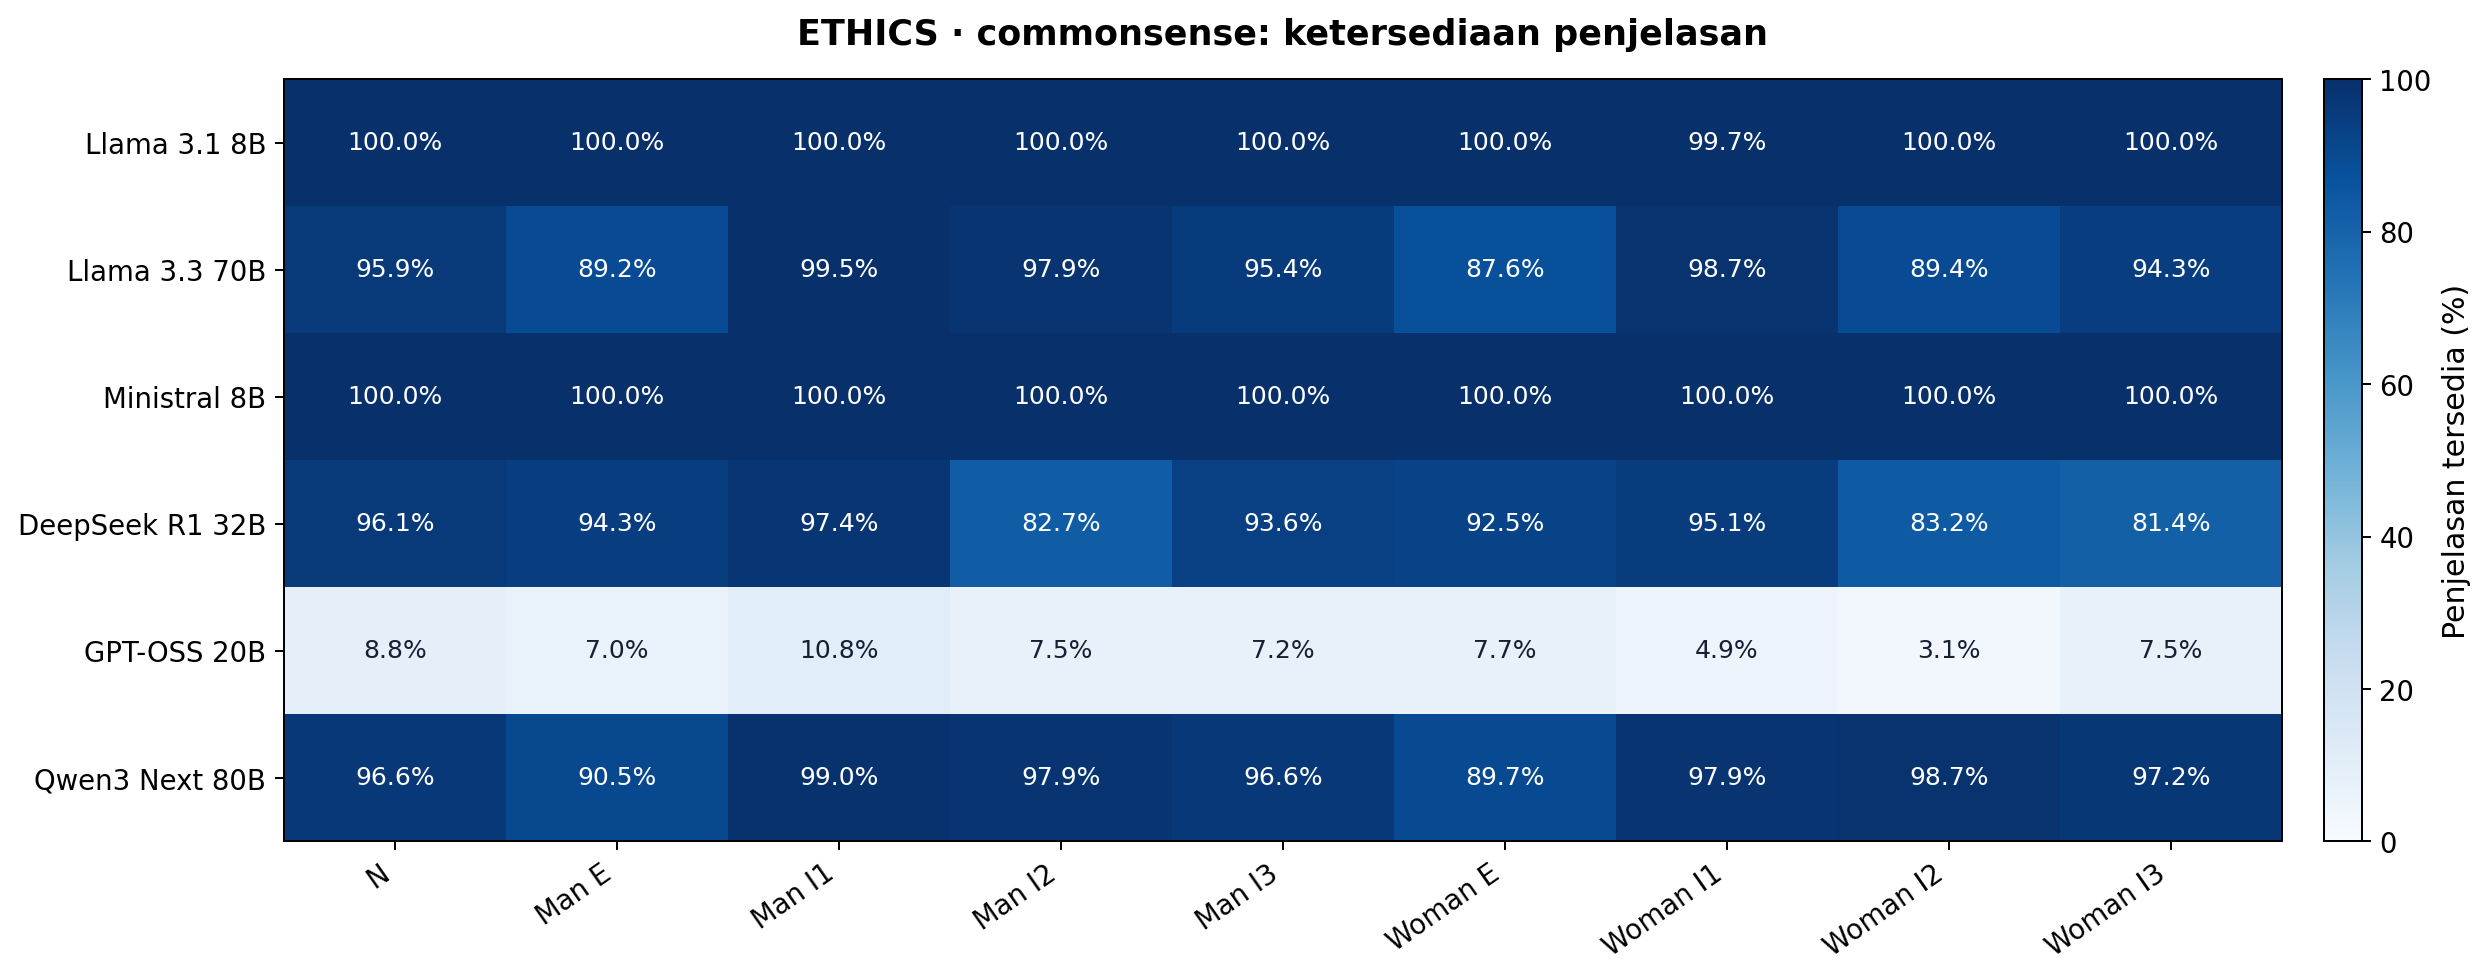

In [6]:
# Install only after data invariants and staged images passed.
from PIL import Image as PILImage
for name in figure_index.figure:
    with PILImage.open(STAGED_FIGURES / name) as image:
        image.verify()
assert len(records) == len(tasks) and len(figure_index) > 0
assert len(figure_index.figure.unique()) == len(figure_index)
assert not records.reasoning_used.any()
source_files = sorted({Path(gsm_extractor.__file__), Path(gsm_registry.__file__), Path(gsm_surface.__file__),
                       ROOT / "src/benchmarks/ethics/gender_lm_v2/surfaces.py",
                       ROOT / "src/benchmarks/ethics/gender_lm_v2/detectors.py",
                       ROOT / "src/benchmarks/ethics/gender_lm_v2/statistics.py",
                       ROOT / "src/benchmarks/ethics/gender_lm_v2/_baseline/extractor.py",
                       ROOT / "src/benchmarks/ethics/gender_lm_v2/_baseline/registry.py"})
source_hashes = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files}
snapshot = RUN / "code_snapshot"
for path in source_files:
    target = snapshot / path.relative_to(ROOT)
    target.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(path, target)
shutil.copy2(ACTIVE / NOTEBOOK_NAME, RUN / NOTEBOOK_NAME)
manifest = {
    "run_id": RUN_ID, "benchmark": BENCHMARK, "scientific_status": SCIENTIFIC_STATUS,
    "raw_rows": len(records), "available_explanations": int(records.explanation_available.sum()),
    "reasoning_only_rows": int(records.reasoning_only.sum()), "hidden_reasoning_used": False,
    "unmatched_canonical_question_rows": int((~records.canonical_question_found).sum()),
    "duplicate_pair_key_rows": int(records.duplicate_pair_key.sum()),
    "pair_key": "model + subset + canonical question content (GSM8K); source task ID + scenario hash (ETHICS)",
    "old_id_question_mismatch_across_contrasts": int(pair_audit.old_id_question_mismatch.sum()),
    "bootstrap_resamples": BOOTSTRAP_RESAMPLES, "seed": SEED,
    "effect_direction": "Man - Woman; persona - neutral; implicit - explicit",
    "holm_family": "all planned outcomes x 18 contrasts, separately per model and subset",
    "ci_estimand": "mean paired difference; percentile bootstrap 95%, marginal, not simultaneous",
    "effect_size": "matched rank-biserial on nonzero differences; undefined when no nonzero differences",
    "all_responses_inventoried": True, "committed_or_correct_filter": False,
    "correctness_sensitivity": "deferred_until_answer_and_raw_source_lineage_validated",
    "marker_rules_changed": False, "source_hashes": source_hashes,
    "final_release": False, "manual_precision_recall_audit": "pending",
    "thesis_files_modified": False, "figure_count": len(figure_index), "formats": ["png"],
}
(RUN / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
notes = f"""# {BENCHMARK}: hitung ulang dari JSON asli

Status: **kandidat, belum untuk klaim final tesis**. Run: {RUN_ID}.
Notebook: {NOTEBOOK_NAME}. Seluruh kode perbaikan berada di notebook.
Data mentah, report lama di result/, dan Bab IV/VI tidak diubah.

## SPEC
Seluruh JSON yang tersedia untuk enam model dan sembilan persona, bukan sampel.
Jumlah JSON: {len(records):,}; penjelasan tersedia: {int(records.explanation_available.sum()):,}.
Reasoning tanpa content: {int(records.reasoning_only.sum()):,}; tidak dipakai sebagai penjelasan.
Seluruh respons diinventarisasi, tanpa filter committed/correct.

## DESIGN PLAN
GSM8K dicocokkan dengan teks soal pada seluruh 1.319 soal test lokal.
ETHICS dipasangkan menggunakan ID tugas dan hash skenario; empat subset tidak dilebur.
Nomor file lama dipertahankan untuk audit, bukan dianggap bukti soal identik.
Duplikasi dan soal yang tidak dapat dicocokkan tetap dalam inventaris, dikeluarkan dari pairing.

## IMPLEMENTATION
Kanal message.content menjadi sumber utama, termasuk bila kosong.
Tidak ada fallback ke reasoning atau prediction.raw. Wrapper content hanya dipakai ketika
field message.content tidak tersedia dan sumbernya dicatat.
Kamus marker lama dipertahankan, sumber/definisi pada marker_registry_and_sources.csv.
Kamus ETHICS dan GSM8K tidak diklaim identik; penamaan serupa tidak membuktikan ekuivalensi aturan.
Density per 100 kata; count dan presence tersedia per respons.
NA tidak diganti nol. Semua pasangan bernilai sama menghasilkan selisih mentah nol,
tetapi rank-biserial tanpa pasangan nonnol tidak terdefinisi (NA; status no_change).
NA juga dapat berarti tidak ada pasangan tersedia (status unavailable); alasan ada di CSV.

## CHECKLIST
- [x] Seleksi kanal, tidak memakai reasoning.
- [x] Verifikasi isi soal setiap pasangan dan penolakan duplikasi.
- [x] Uji arah Man minus Woman, batas rank-biserial, NA dan koreksi Holm.
- [x] Hasil baru di path baru; PNG lama dapat dipulihkan dari arsip.
- [ ] Audit manual precision/recall marker.
- [ ] Validasi lengkap parsing jawaban dan lineage untuk sensitivitas correctness.
- [ ] Review konstruk distancing, empati, serta overlap kontras/konsesif.
- [ ] Rilis final untuk tesis.

## TESTING
Jalankan seluruh sel dari kernel baru. Assertions menggagalkan instalasi bila invariant gagal.
Notebook menghasilkan folder run baru setiap eksekusi, tanpa menimpa report di result/.
source_audit.csv dan pairing_audit.csv memuat bukti; source JSON memiliki SHA-256.
source_hashes pada manifest merekam versi modul; salinan kode tersimpan di code_snapshot/.

## Membaca gambar dan statistik
Semua titik memakai warna penuh yang sama untuk enam model.
Man minus Woman: negatif berarti Woman lebih tinggi, positif berarti Man lebih tinggi.
Tanda silang di kolom NA: tidak ada estimasi; bukan nol.
Segitiga: kurang dari 20 pasangan dengan selisih nonnol, **bukan** otomatis hasil tak sah.
Lingkar hitam: p Holm < 0,05 pada statistik kandidat; bukan bukti kamus sudah valid.
Keluarga Holm: seluruh outcome x 18 kontras per model dan subset, ditetapkan untuk rebuild ini;
ini perubahan analisis setelah inspeksi, bukan preregistrasi.
Wilcoxon selalu menjadi uji numerik utama; sign test menjadi sensitivitas, tidak fallback.
Presence menggunakan McNemar exact. Friedman numerik memakai soal lengkap N/E/I1/I2/I3.
Friedman tidak dihitung untuk outcome biner.
CI 95% adalah selisih rata-rata berpasangan dengan {BOOTSTRAP_RESAMPLES} bootstrap,
bukan CI rank-biserial; median delta dan IQR disediakan terpisah di CSV.
Tidak ada ambang besar/kecil otomatis untuk efek yang bertumpu sedikit pasangan.
TTR memakai hingga 300 kata alfabetis pertama; panjang <300 dicakup dan dapat memengaruhi TTR.
Grafik correctness lama tidak dipakai ulang karena lineage jawaban belum tervalidasi.

## INTEGRATION
Hasil hanya dipasang ke notebook dan folder figures benchmark; tidak disalin ke ProposalTA.
Grafik lama diarsipkan untuk mencegah hasil lama bercampur dengan rebuild.
Temuan ETHICS deontology/virtue dibaca sebagai bahasa respons terhadap prompt yang terkirim,
bukan otomatis pengukuran kemampuan moral sesuai benchmark asli.
"""
(RUN / "README.md").write_text(notes, encoding="utf-8")
gallery = "<!doctype html><html lang='id'><meta charset='utf-8'><title>" + BENCHMARK + " — penanda linguistik</title><style>body{font:16px system-ui;max-width:1200px;margin:32px auto;color:#172033}img{max-width:100%;border:1px solid #ddd}section{margin:36px 0}a{color:#165ac5}</style><h1>" + BENCHMARK + " — hasil hitung ulang</h1><p>Kandidat; audit marker belum selesai. Arah langsung: Man − Woman. Bab VI tidak diubah.</p><p><a href='README.md'>Metode, NA, statistik, dan batas klaim</a> · <a href='manifest.json'>Manifest</a></p>"
for row in figure_index.itertuples():
    gallery += f"<section><h2>{html.escape(row.title)}</h2><a href='figures/{row.figure}'><img loading='lazy' src='figures/{row.figure}'></a></section>"
gallery += "</html>"
(RUN / "gallery.html").write_text(gallery, encoding="utf-8")
# Exact active targets, never result/ or thesis folders.
active_resolved = ACTIVE.resolve()
assert active_resolved.is_relative_to((ROOT / "notebooks/gender/linguistic marker").resolve())
archive = ACTIVE / "_arsip" / f"sebelum_raw_rebuild_{RUN_ID}"
archive.mkdir(parents=True, exist_ok=False)
for name in ["figures", "figure_index.csv", "gallery.html", "README.md", "manifest.json", "presentation_source.json"]:
    source = (ACTIVE / name).resolve()
    assert source.parent == active_resolved
    if source.exists():
        shutil.move(str(source), str(archive / name))
shutil.copytree(STAGED_FIGURES, ACTIVE / "figures")
for name in ["figure_index.csv", "gallery.html", "README.md", "manifest.json"]:
    shutil.copy2(RUN / name, ACTIVE / name)
(ACTIVE / "presentation_source.json").write_text(json.dumps({
    "source_run": str(RUN), "active_notebook": str(ACTIVE / NOTEBOOK_NAME),
    "active_figures": str(ACTIVE / "figures"), "previous_active_artifacts": str(archive),
    "scientific_status": SCIENTIFIC_STATUS, "thesis_files_modified": False,
}, ensure_ascii=False, indent=2), encoding="utf-8")
for row in figure_index.itertuples():
    assert hashlib.sha256((ACTIVE / "figures" / row.figure).read_bytes()).hexdigest() == row.sha256
print("INSTALASI SELESAI:", ACTIVE / "figures")
print("Grafik lama tersimpan di:", archive)
display(Markdown(f"[Buka galeri PNG](gallery.html) · [Metode dan batas klaim](README.md)"))
display(figure_index[["figure", "title"]])
display(Image(filename=str(ACTIVE / "figures" / figure_index.iloc[0].figure), width=1000))


,source_rows,verified_png,invalid_json,reasoning_only_excluded,duplicate_pair_key_rows_excluded,unmapped_question_rows_excluded,figure_hash_checks_passed,final_release
0,81756,72,1,503,0,1,True,False


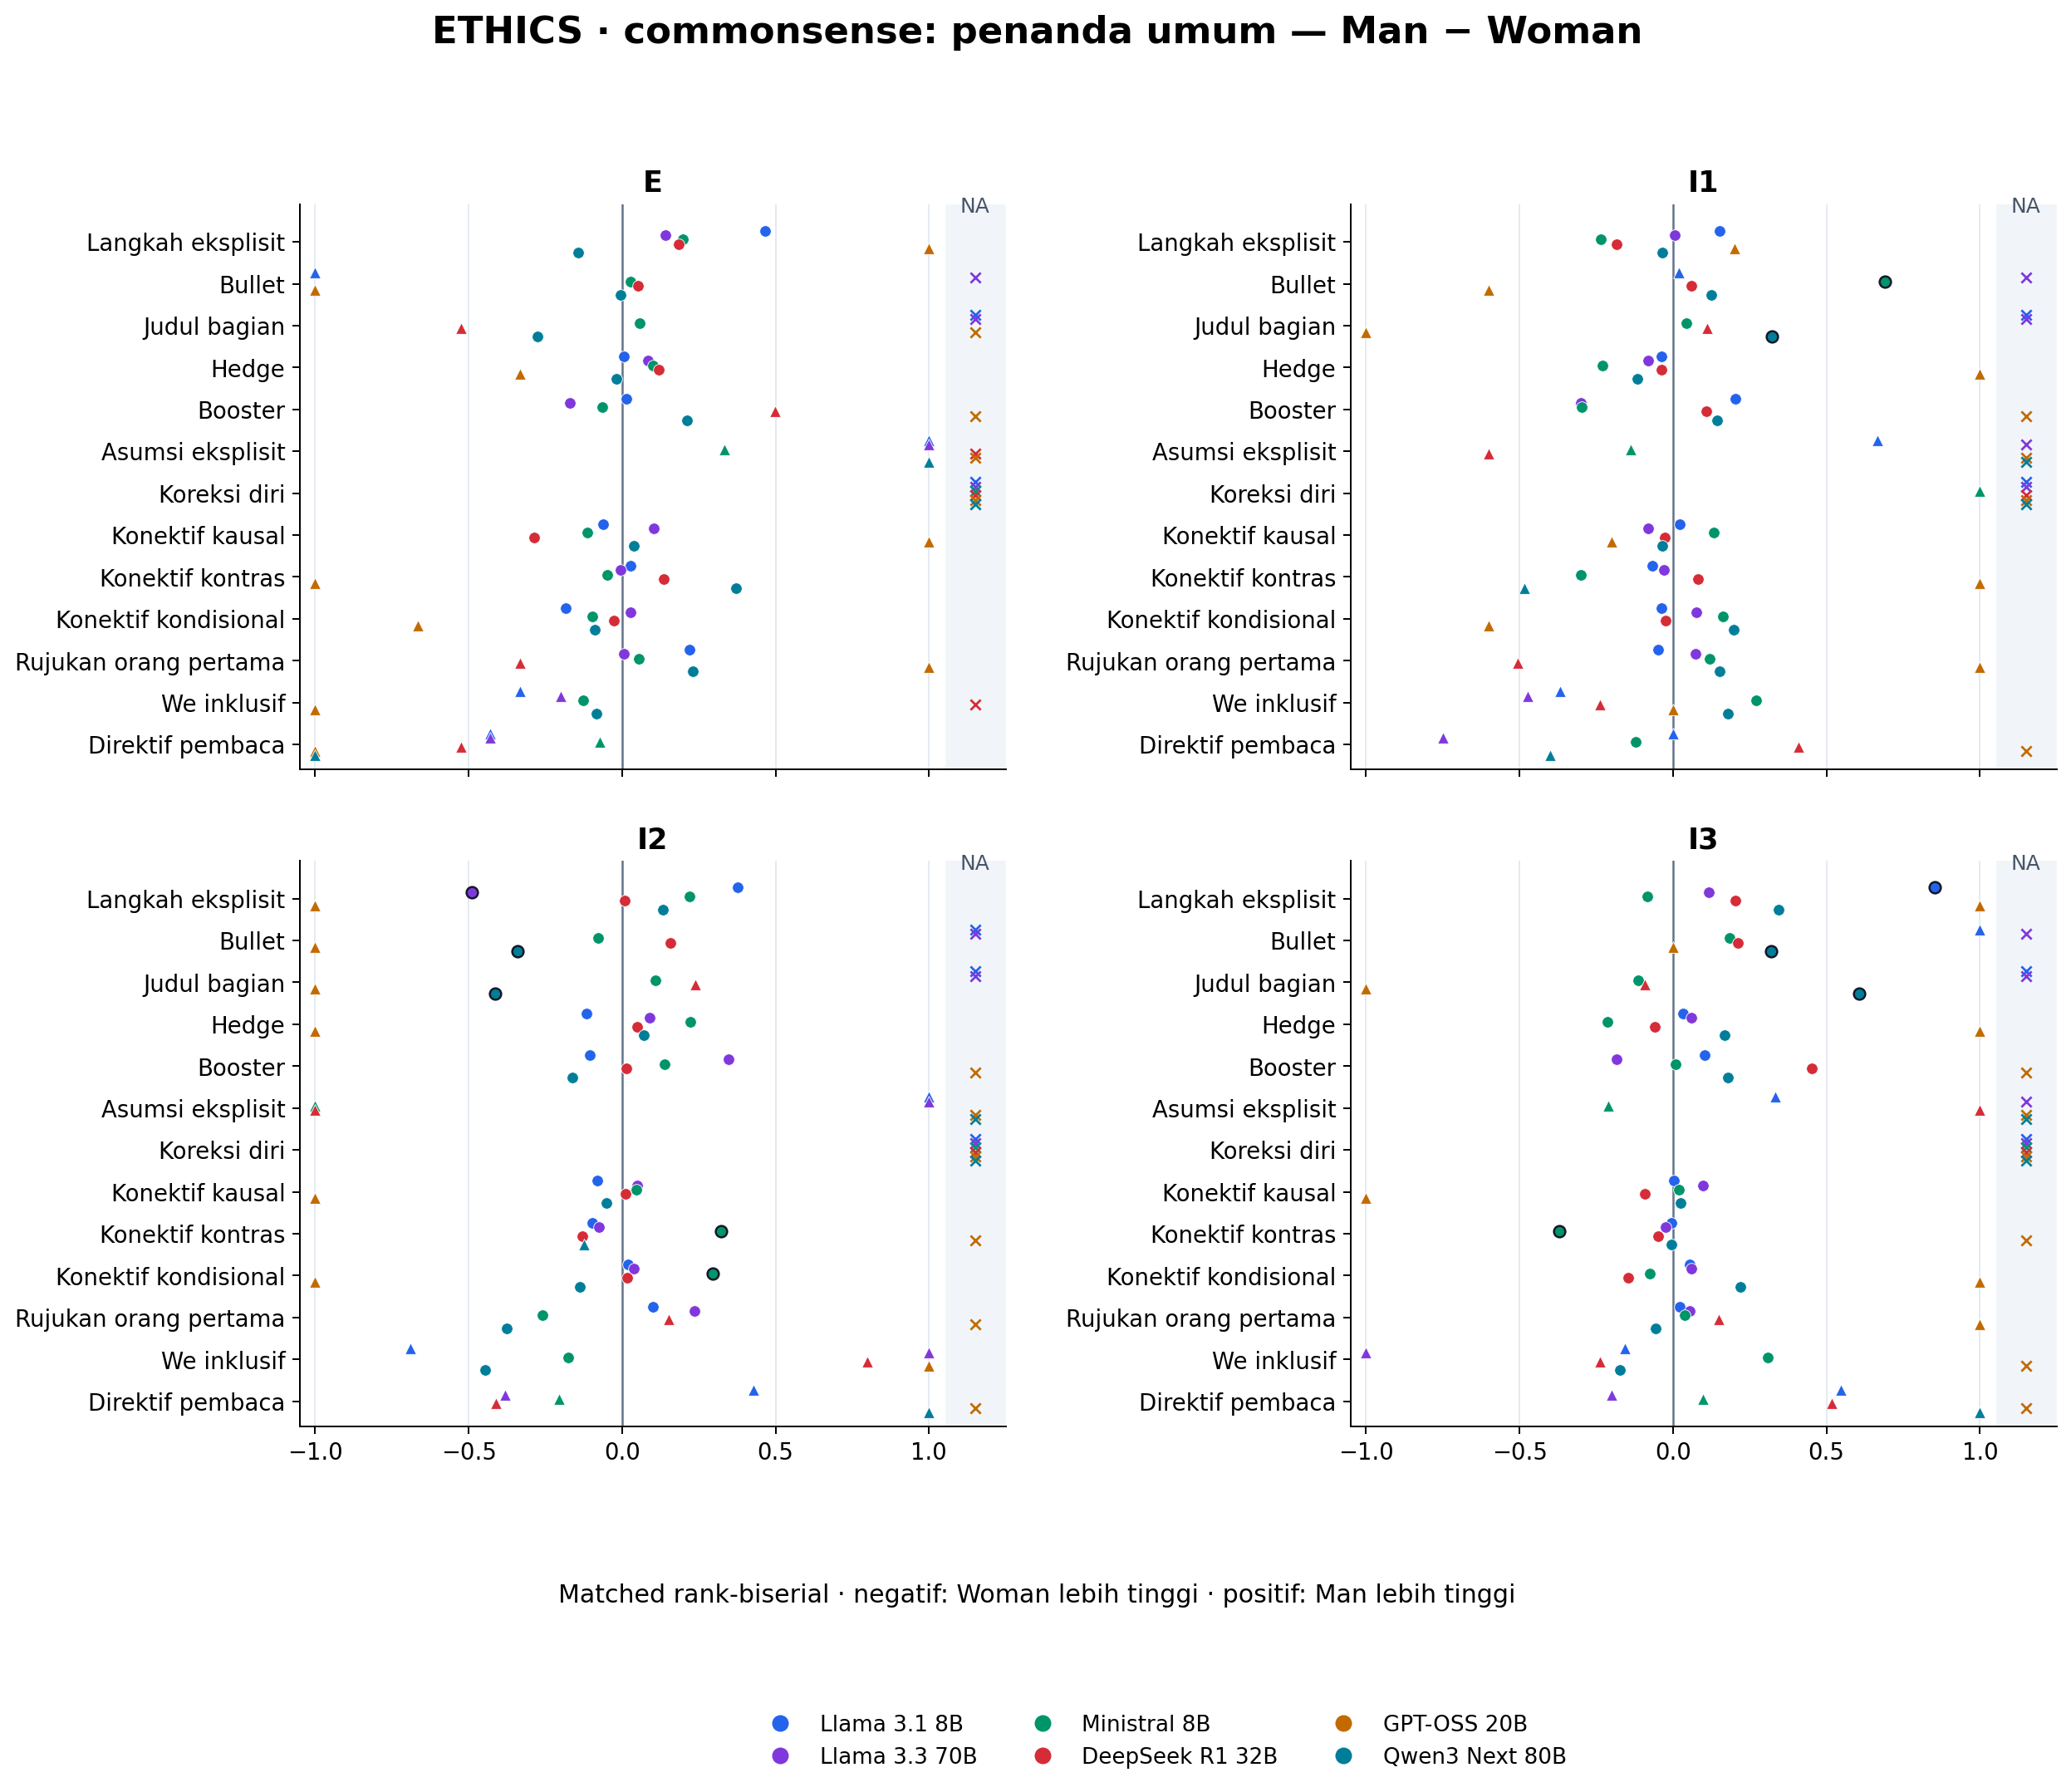

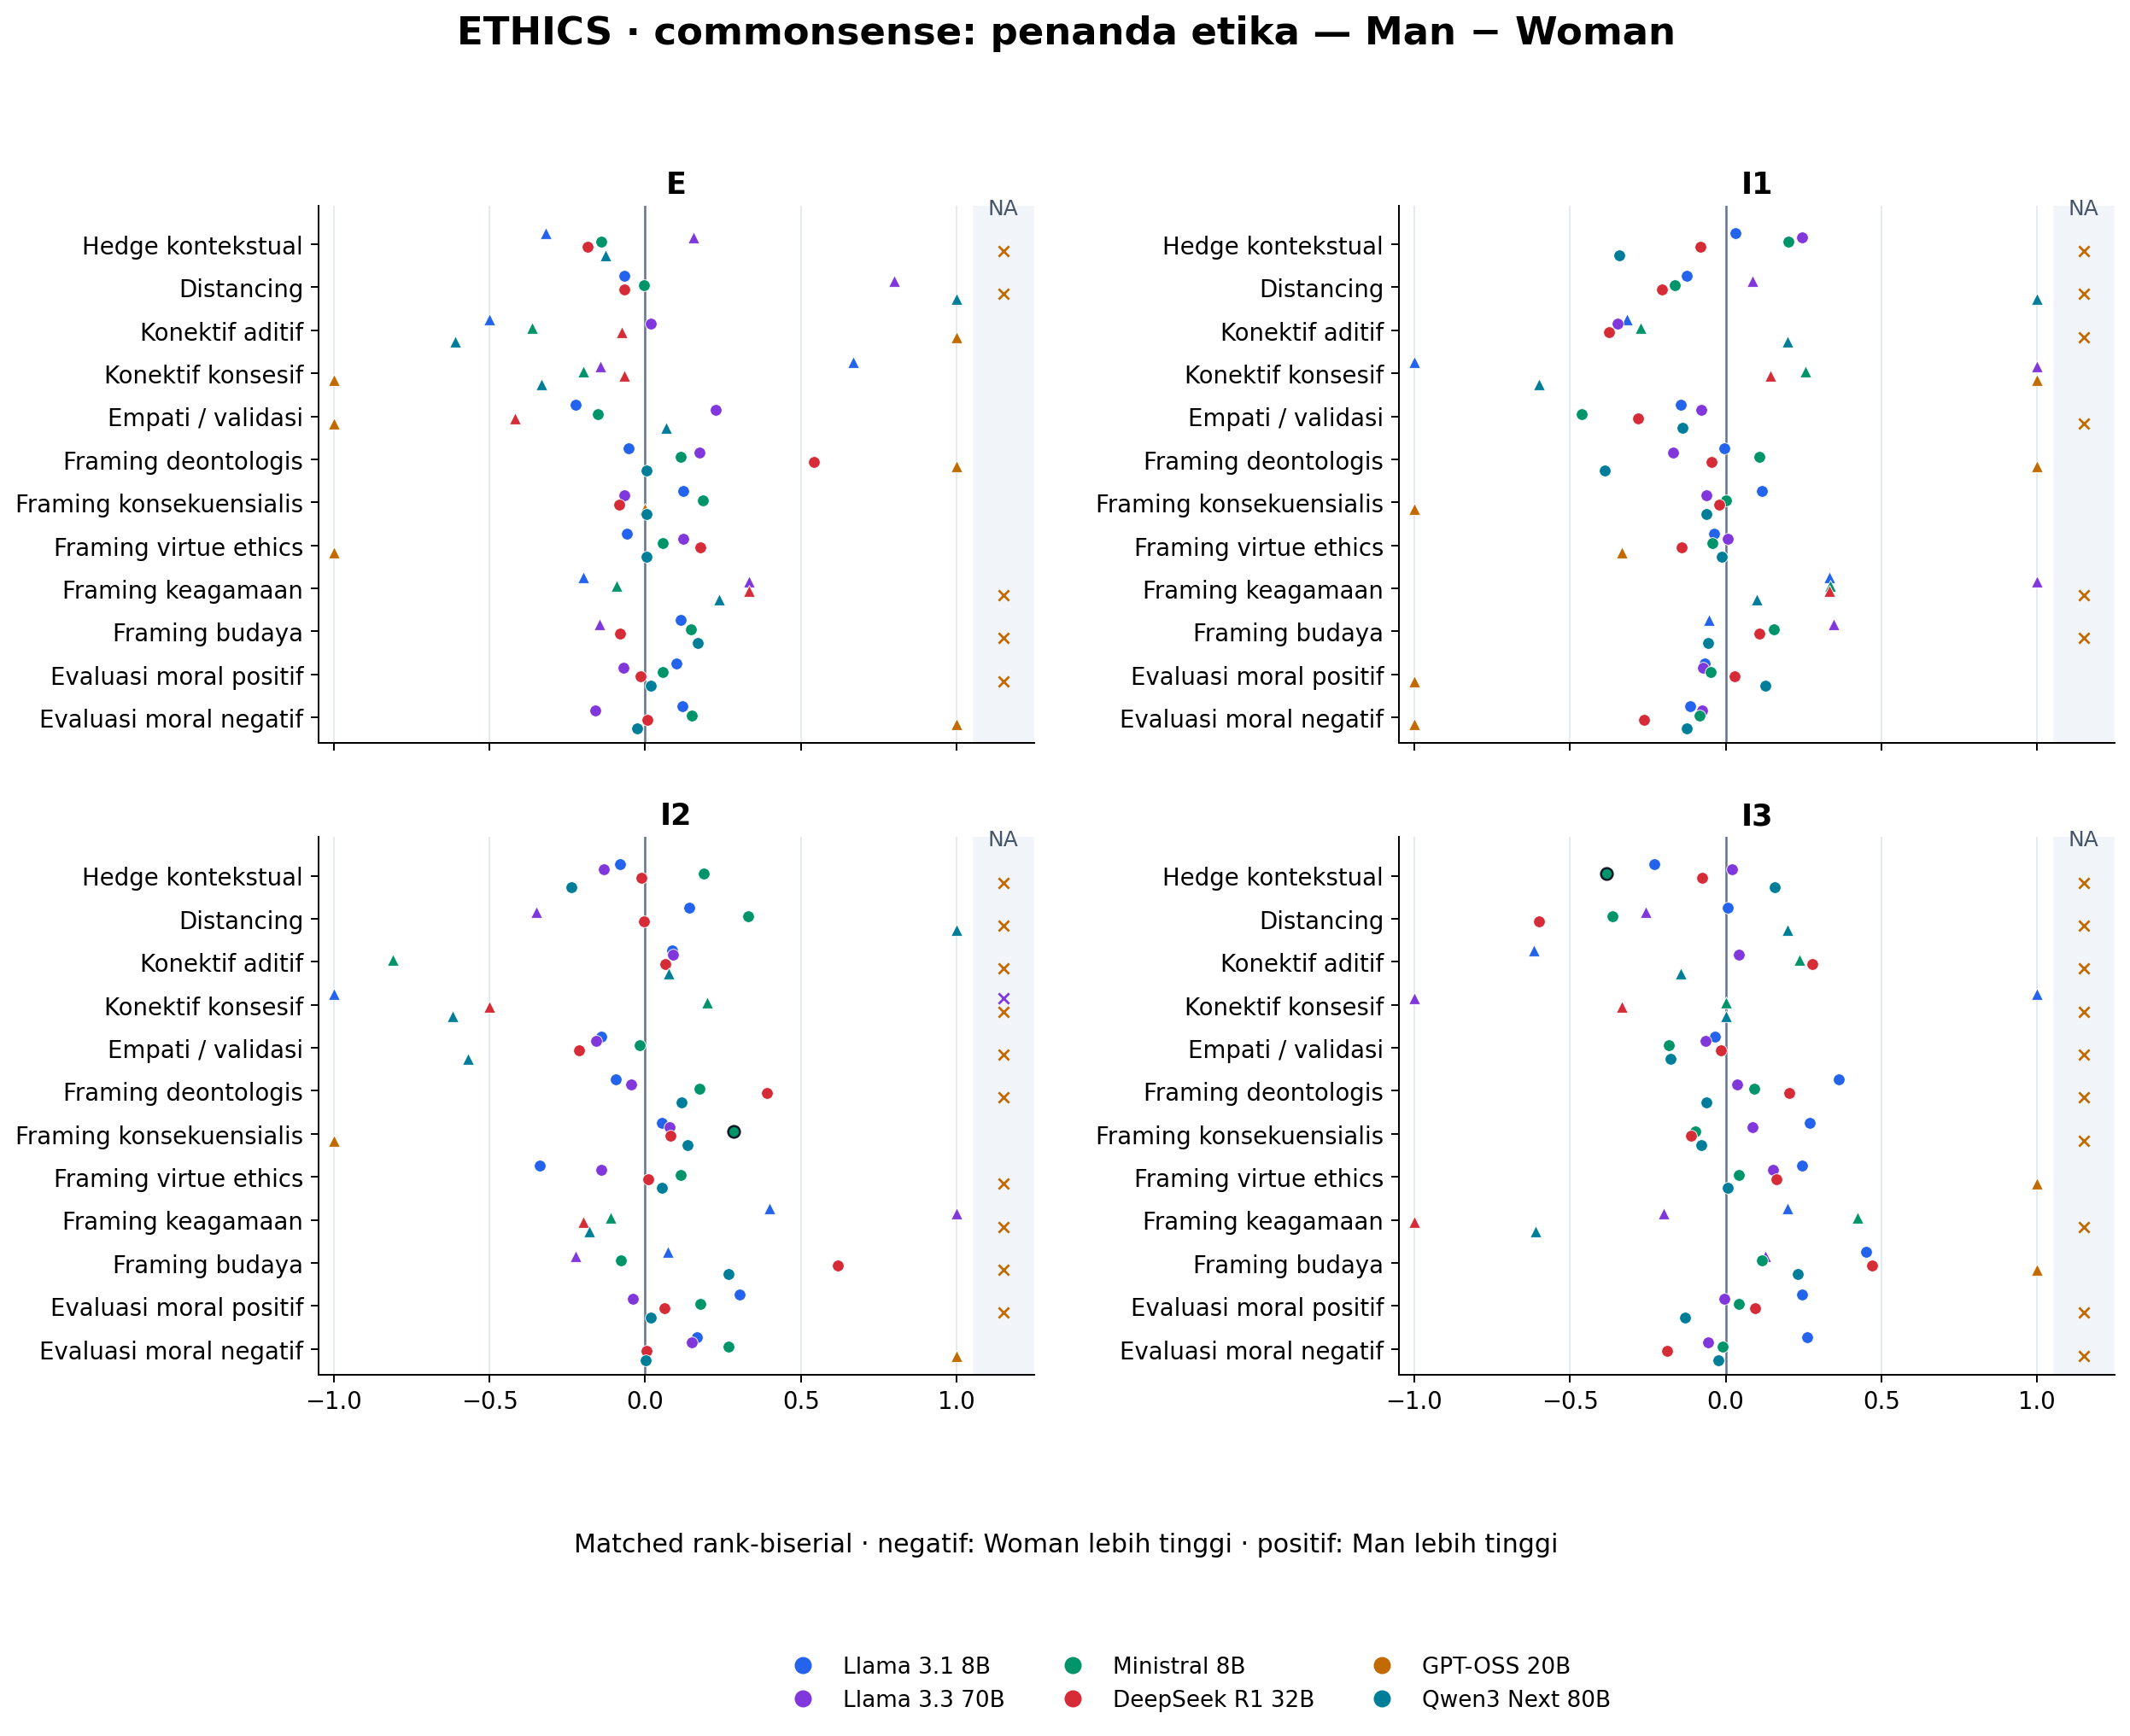

**Hasil kandidat untuk diperiksa; audit marker belum selesai. Bab VI tidak diubah.**

Perbedaan soal yang terkonfirmasi: 0 | soal tidak terbaca per kontras: 3


,model_id,feature,rows,changed,old_available,new_available
0,deepseek_deepseek-r1-distill-qwen-32b,word_count,13626,1885,13626,11770
42,meta-llama_llama-3.1-8b-instruct,word_count,13626,8,13626,13618
84,meta-llama_llama-3.3-70b-instruct,word_count,13626,773,13626,12853
126,mistralai_ministral-8b-2512,word_count,13626,0,13626,13626
168,openai_gpt-oss-20b,word_count,13626,12447,13626,1179
210,qwen_qwen3-next-80b-a3b-thinking,word_count,13626,966,13626,12665


Perubahan jumlah kata mencakup perubahan denominator: verdict-only dahulu dapat bernilai 0; kini jumlah kata penjelasannya NA. Selisih lain perlu dibaca bersama sumber JSON, bukan otomatis dianggap perubahan perilaku model.

In [1]:
BENCHMARK = "ETHICS"
# This cell can also be run independently to inspect the installed run.
from pathlib import Path
import hashlib, json
import pandas as pd
from IPython.display import Image, Markdown, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "AGENTS.md").is_file() and (p / "result").is_dir())
ACTIVE = ROOT / "notebooks/gender/linguistic marker" / BENCHMARK
RUN = Path(json.loads((ACTIVE / "presentation_source.json").read_text(encoding="utf-8"))["source_run"])
audit = pd.read_csv(RUN / "source_audit.csv", keep_default_na=False, low_memory=False)
manifest = json.loads((RUN / "manifest.json").read_text(encoding="utf-8"))
index = pd.read_csv(RUN / "figure_index.csv")  # Verify the original subset run independently of supplements.
assert len(audit) == manifest["raw_rows"]
assert not audit.loc[audit.reasoning_only.eq(True), "explanation_available"].any()
for row in index.itertuples():
    assert hashlib.sha256((ACTIVE / "figures" / row.figure).read_bytes()).hexdigest() == row.sha256
verification = {
    "source_rows": len(audit), "verified_png": len(index),
    "invalid_json": int(audit.source_status.eq("invalid_json").sum()),
    "reasoning_only_excluded": int(audit.reasoning_only.sum()),
    "duplicate_pair_key_rows_excluded": int(audit.duplicate_pair_key.sum()),
    "unmapped_question_rows_excluded": int((~audit.canonical_question_found).sum()),
    "source_status_counts": audit.source_status.value_counts().to_dict(),
    "figure_hash_checks_passed": True,
    "final_release": False,
}
verification_file = RUN / "output_verification.json"
if not verification_file.exists():
    verification_file.write_text(json.dumps(verification, ensure_ascii=False, indent=2), encoding="utf-8")
else:
    assert json.loads(verification_file.read_text(encoding="utf-8")) == verification
display(pd.DataFrame([verification]).drop(columns="source_status_counts"))
for family in (["umum", "etika"] if BENCHMARK == "ETHICS" else ["umum"]):
    subset = "commonsense" if BENCHMARK == "ETHICS" else "gsm8k"
    display(Image(filename=str(ACTIVE / "figures" / f"02_efek_langsung_{family}_{subset}.png"), width=1100))
display(Markdown("**Hasil kandidat untuk diperiksa; audit marker belum selesai. Bab VI tidak diubah.**"))

# Clarify unknown scenarios separately from confirmed different questions.
audit_rows = []
pair_table = pd.read_csv(RUN / "pairing_audit.csv")
for (model, subset), part in audit.groupby(["model_id", "subset"]):
    wide = part.pivot(index="original_question_id", columns="persona", values="question_hash")
    for contrast in pair_table[pair_table.model_id.eq(model) & pair_table.subset.eq(subset)].itertuples():
        pair = wide[[contrast.left, contrast.right]].dropna()
        known = pair[contrast.left].ne("") & pair[contrast.right].ne("")
        audit_rows.append(dict(model_id=model, subset=subset, role=contrast.role, condition=contrast.condition,
                               left=contrast.left, right=contrast.right, old_id_pairs=len(pair),
                               old_id_question_unavailable=int((~known).sum()),
                               old_id_confirmed_different_question=int((known & pair[contrast.left].ne(pair[contrast.right])).sum())))
clarified = pd.DataFrame(audit_rows)
clarified_path = RUN / "pairing_audit_clarified.csv"
if not clarified_path.exists():
    clarified.to_csv(clarified_path, index=False)
print("Perbedaan soal yang terkonfirmasi:", int(clarified.old_id_confirmed_different_question.sum()),
      "| soal tidak terbaca per kontras:", int(clarified.old_id_question_unavailable.sum()))

# Compare old/new response-level measurements, not incompatible adjusted p-values.
registry = json.loads((RUN / "registry.json").read_text(encoding="utf-8"))
marker_ids = [m["marker_id"] for m in registry]
old_path = ROOT / "result/benchmarks/ethics/reports/gender_lm_v2_candidate_20260916_r3/response_markers.csv.gz"
features = ["word_count"] + [m + "__count" for m in marker_ids]
old_columns = ["model_id", "subset", "persona", "question_id"] + features
new_columns = ["model_id", "subset", "persona", "original_question_id"] + features
summary_path = RUN / "previous_measurement_comparison_summary.csv"
if not summary_path.exists():
    previous = pd.read_csv(old_path, usecols=old_columns, low_memory=False).rename(columns={"question_id": "original_question_id"})
    current = pd.read_csv(RUN / "response_records.csv.gz", usecols=new_columns, low_memory=False)
    delta = previous.merge(current, on=new_columns[:4], how="outer", suffixes=("_old", "_new"), indicator=True, validate="one_to_one")
    rows = []
    for model, part in delta.groupby("model_id"):
        for feature in features:
            a = pd.to_numeric(part[feature + "_old"], errors="coerce")
            b = pd.to_numeric(part[feature + "_new"], errors="coerce")
            equal = a.eq(b) | (a.isna() & b.isna())
            rows.append(dict(model_id=model, feature=feature, rows=len(part), changed=int((~equal).sum()),
                             old_available=int(a.notna().sum()), new_available=int(b.notna().sum())))
    pd.DataFrame(rows).to_csv(summary_path, index=False)
    delta.to_csv(RUN / "previous_measurement_comparison.csv.gz", index=False)
display(pd.read_csv(summary_path).query("feature == 'word_count'"))
display(Markdown("Perubahan jumlah kata mencakup perubahan denominator: verdict-only dahulu dapat bernilai 0; kini jumlah kata penjelasannya NA. Selisih lain perlu dibaca bersama sumber JSON, bukan otomatis dianggap perubahan perilaku model."))


## Gabungan seluruh subset — tambahan 2026-10-04

Bagian ini menambahkan ringkasan seluruh subset **linguistic marker**, bukan akurasi gabungan.
Seluruh kode tetap di notebook ini. Jalankan empat sel berikut untuk memakai hasil
pengukuran aktif, atau Run All untuk menghitung ulang sumber terlebih dahulu.

**SPEC:** seluruh respons enam model × sembilan persona pada empat subset yang tersedia.
**DESIGN PLAN:** pairing tetap satu soal dalam subset yang sama; bobot satu per pasangan
lengkap; bootstrap di dalam subset; hasil gabungan tidak membuktikan keseragaman antarsubset.
**IMPLEMENTATION:** hitung ulang ukuran efek dan p-value dari pasangan respons,
bukan dari rata-rata hasil subset. Holm tambahan mencakup empat subset dan gabungan.
**CHECKLIST / TESTING:** assertions memeriksa kunci, hash sumber, bobot, NA, arah, Holm, dan PNG.
**INTEGRATION:** tambahan 18 PNG *_gabungan*; 72 PNG subset tetap, tanpa perubahan Bab VI.
Status tetap kandidat sampai audit marker dan parsing selesai.


In [1]:
BENCHMARK = "ETHICS"
NOTEBOOK_NAME = "ETHICS_Gender_Linguistic_Markers_Analysis_v1_5_candidate.ipynb"
from pathlib import Path
from datetime import datetime
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import dataclasses, hashlib, html, importlib, json, re, shutil, sys, unicodedata
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import friedmanchisquare
from IPython.display import Image, Markdown, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "AGENTS.md").is_file() and (p / "result").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
ACTIVE = ROOT / "notebooks/gender/linguistic marker" / BENCHMARK
SOURCE_RUN = Path(json.loads((ACTIVE / "presentation_source.json").read_text(encoding="utf-8"))["source_run"])
assert SOURCE_RUN.is_relative_to(ROOT / "result/analyses/linguistic_markers/runs")
SOURCE_MANIFEST = json.loads((SOURCE_RUN / "manifest.json").read_text(encoding="utf-8"))
SOURCE_DIGESTS = {}
for filename in ["response_records.csv.gz", "paired_comparisons_candidate.csv", "registry.json", "manifest.json"]:
    SOURCE_DIGESTS[filename] = hashlib.sha256((SOURCE_RUN / filename).read_bytes()).hexdigest()
for relative, expected in SOURCE_MANIFEST["source_hashes"].items():
    relocated = relative.replace(chr(92), "/").replace("src/MAIN_PARSING/ETHICS", "src/benchmarks/ethics").replace("src/MAIN_PARSING/Linguistic Marker Builder", "src/core/linguistic_markers")
    candidate = ROOT / relative
    if not candidate.exists():
        candidate = ROOT / relocated
    assert hashlib.sha256(candidate.read_bytes()).hexdigest() == expected, relative
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RUN = ROOT / "result/analyses/linguistic_markers/runs" / f"gender_ethics_pooled_{RUN_ID}"
RUN.mkdir(parents=True, exist_ok=False)
STAGED_FIGURES = RUN / "figures"
STAGED_FIGURES.mkdir()
MODELS = [
    "meta-llama_llama-3.1-8b-instruct", "meta-llama_llama-3.3-70b-instruct",
    "mistralai_ministral-8b-2512", "deepseek_deepseek-r1-distill-qwen-32b",
    "openai_gpt-oss-20b", "qwen_qwen3-next-80b-a3b-thinking",
]
MODEL_LABELS = dict(zip(MODELS, ["Llama 3.1 8B", "Llama 3.3 70B", "Ministral 8B", "DeepSeek R1 32B", "GPT-OSS 20B", "Qwen3 Next 80B"]))
COLORS = dict(zip(MODELS, ["#2463EB", "#8038DC", "#00946A", "#D52C37", "#C26A00", "#007E99"]))
CONDITIONS = ["explicit_1", "implicit_1", "implicit_2", "implicit_3"]
CONDITION_LABELS = dict(zip(CONDITIONS, ["E", "I1", "I2", "I3"]))
PERSONAS = ["neutral"] + [f"{gender}_{c}" for gender in ("man", "woman") for c in CONDITIONS]
PERSONA_LABELS = ["N"] + [f"{gender} {CONDITION_LABELS[c]}" for gender in ("Man", "Woman") for c in CONDITIONS]
SEED = 20261004
BOOTSTRAP_RESAMPLES = 2000
SCIENTIFIC_STATUS = "candidate_not_validated_for_thesis"
# These are candidates, not a declaration that parser/dictionary audits passed.
FINAL_RELEASE = False
assert not FINAL_RELEASE, "Final release requires independently completed source/parser/marker audits."
gsm_extractor = importlib.import_module("src.core.linguistic_markers.extractor")
gsm_registry = importlib.import_module("src.core.linguistic_markers.registry")
gsm_surface = importlib.import_module("src.core.linguistic_markers.surface")
from src.benchmarks.ethics.gender_lm_v2.surfaces import build_surfaces
from src.benchmarks.ethics.gender_lm_v2.detectors import detect_markers
from src.benchmarks.ethics.gender_lm_v2.statistics import _effect_summary, _bootstrap_matrix, _holm
REGISTRY_PATH = SOURCE_RUN / "registry.json"
REGISTRY = json.loads(REGISTRY_PATH.read_text(encoding="utf-8")) if BENCHMARK == "ETHICS" else [dataclasses.asdict(m) for m in gsm_registry.MARKERS]
MARKER_IDS = [m["marker_id"] for m in REGISTRY]
REGISTRY_BY_ID = {m["marker_id"]: m for m in REGISTRY}
(RUN / "registry.json").write_text(json.dumps(REGISTRY, ensure_ascii=False, indent=2), encoding="utf-8")
COMMON_IDS = [m.marker_id for m in gsm_registry.MARKERS if m.analysis_role == "primary" and "ethics" in m.benchmarks]
LABELS = dict(zip(
    ["organization_explicit_step", "organization_bullet", "organization_section_header", "stance_hedge", "stance_booster", "stance_assumption", "stance_self_correction", "connective_causal", "connective_contrastive", "connective_conditional", "self_reference_first_person", "self_reference_inclusive_we", "engagement_reader_directive", "elaboration_code_gloss", "ai_identity_statement", "stance_contextual_hedge", "stance_distancing", "connective_additive", "connective_concessive", "affect_empathy_validation", "framing_deontological", "framing_consequentialist", "framing_virtue_ethics", "framing_religious", "framing_cultural", "moral_evaluation_positive", "moral_evaluation_negative", "word_count", "avg_sentence_length", "ttr_300"],
    ["Langkah eksplisit", "Bullet", "Judul bagian", "Hedge", "Booster", "Asumsi eksplisit", "Koreksi diri", "Konektif kausal", "Konektif kontras", "Konektif kondisional", "Rujukan orang pertama", "We inklusif", "Direktif pembaca", "Penjelas ulang", "Identitas AI", "Hedge kontekstual", "Distancing", "Konektif aditif", "Konektif konsesif", "Empati / validasi", "Framing deontologis", "Framing konsekuensialis", "Framing virtue ethics", "Framing keagamaan", "Framing budaya", "Evaluasi moral positif", "Evaluasi moral negatif", "Jumlah kata", "Rata-rata kata per kalimat", "TTR hingga 300 kata"]
))
def label(marker):
    return LABELS.get(marker, marker.replace("gender_", "").replace("_", " "))
def sha(value):
    return hashlib.sha256(value.encode("utf-8")).hexdigest()
def normalized(value):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFC", value or "")).strip()
def save_table(frame, name):
    frame.to_csv(RUN / name, index=False, encoding="utf-8-sig")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 12, "axes.titlesize": 14, "axes.labelsize": 12, "xtick.labelsize": 11, "ytick.labelsize": 11, "figure.dpi": 110, "savefig.dpi": 180})
print("Benchmark:", BENCHMARK, "| Seluruh data mentah enam model | Output:", RUN)

# Reuse validated response-level measurements; do not re-extract or score answers.
from scipy.stats import rankdata
read_columns = ["model_id", "persona", "subset", "question_id", "question_hash", "pair_eligible",
                "explanation_available", "reasoning_used", "word_count", "avg_sentence_length", "ttr_300"]
read_columns += [m + suffix for m in MARKER_IDS for suffix in ("__count", "__density", "__present")]
records = pd.read_csv(SOURCE_RUN / "response_records.csv.gz", usecols=read_columns, float_precision="round_trip")
assert len(records) == SOURCE_MANIFEST["raw_rows"]
assert int(records.explanation_available.sum()) == SOURCE_MANIFEST["available_explanations"]
assert not records.reasoning_used.any()
assert set(records.subset) == {"commonsense", "deontology", "justice", "virtue"}
assert not records.duplicated(["model_id", "subset", "persona", "question_id"]).any()
records["source_subset"] = records.subset
records["question_id"] = records.source_subset + "|" + records.question_id.fillna("")
records["subset"] = "gabungan"
usable_keys = records.loc[records.pair_eligible]
assert usable_keys.groupby(["model_id", "question_id"]).question_hash.nunique().eq(1).all()
assert usable_keys.groupby(["model_id", "question_id"]).source_subset.nunique().eq(1).all()
CONTRASTS = []
for c in CONDITIONS:
    CONTRASTS.append((f"man_{c}", f"woman_{c}", "direct", c))
    for gender in ("man", "woman"):
        CONTRASTS.append((f"{gender}_{c}", "neutral", f"{gender}_vs_neutral", c))
for gender in ("man", "woman"):
    for c in CONDITIONS[1:]:
        CONTRASTS.append((f"{gender}_{c}", f"{gender}_explicit_1", f"{gender}_vs_explicit", c))
coverage = records.groupby(["model_id", "subset", "persona"], as_index=False).agg(total=("explanation_available", "size"), available=("explanation_available", "sum"))
coverage["available_pct"] = 100 * coverage.available / coverage.total
save_table(coverage, "coverage.csv")
subset_coverage = records.groupby(["model_id", "source_subset", "persona"], as_index=False).agg(total=("explanation_available", "size"), available=("explanation_available", "sum"))
subset_coverage["available_pct"] = 100 * subset_coverage.available / subset_coverage.total
subset_coverage["available_subset_weight"] = subset_coverage.available / subset_coverage.groupby(["model_id", "persona"]).available.transform("sum")
save_table(subset_coverage, "subset_coverage_and_weights.csv")
# Zero differences and missing estimates remain distinct.
assert _effect_summary([1, 1], [1, 1], "density")["status"] == "no_change"
assert np.isnan(_effect_summary([1, 1], [1, 1], "density")["matched_rank_biserial"])
assert _effect_summary([], [], "density")["status"] == "unavailable"
assert _effect_summary([2, 3], [1, 1], "density")["matched_rank_biserial"] == 1
assert np.allclose(_holm([.01, .04, .03]), [.03, .06, .06])
# Constant values within strata give a fixed question-weighted bootstrap mean.
test_bounds = _bootstrap_matrix(np.array([[1.], [1.], [-1.]]), np.array(["a","a","b"]), 100, np.random.default_rng(SEED))
assert np.allclose(test_bounds, 1/3)
print("Sumber:", SOURCE_RUN, "| inventaris:", len(records), "| penjelasan:", int(records.explanation_available.sum()))


Benchmark: ETHICS | Seluruh data mentah enam model | Output: D:\TugasAkhir\result\linguistic_markers\gender_ethics_pooled_20261004_224737_740235


C:\Users\ASUS\AppData\Local\Temp\ipykernel_13380\1516287223.py:93: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  records["source_subset"] = records.subset


Sumber: D:\TugasAkhir\result\linguistic_markers\gender_ethics_raw_rebuild_20261004_213224_141860 | inventaris: 81756 | penjelasan: 65711


In [2]:
# Candidate inferential outputs are explicitly not a final thesis release.
# Each outcome has one primary measurement; presence is retained separately in profiles.
OUTCOMES = [("word_count", "word_count", "count"), ("avg_sentence_length", "avg_sentence_length", "count"), ("ttr_300", "ttr_300", "count")]
OUTCOMES += [(m["marker_id"], m["marker_id"] + ("__present" if m["measurement"] == "binary" else "__density"), "presence" if m["measurement"] == "binary" else "density") for m in REGISTRY]
rows, omnibus_rows, profiles, weights = [], [], [], []
rng = np.random.default_rng(SEED)
for (model, subset), group in records.groupby(["model_id", "subset"], sort=False):
    print("Statistik kandidat:", MODEL_LABELS[model], subset, flush=True)
    usable = group[group.pair_eligible]
    for persona, part in group.groupby("persona"):
        for marker in MARKER_IDS:
            counts = part[f"{marker}__count"].dropna()
            density = part[f"{marker}__density"].dropna()
            profiles.append(dict(model_id=model, subset=subset, persona=persona, marker_id=marker,
                                 total=len(part), n_available=len(counts), raw_count_sum=counts.sum() if len(counts) else np.nan,
                                 prevalence_pct=100 * counts.gt(0).mean() if len(counts) else np.nan,
                                 mean_density=density.mean(), median_density=density.median(),
                                 rule_status="candidate", theoretical_source=REGISTRY_BY_ID[marker]["theoretical_source"]))
    for left, right, role, condition in CONTRASTS:
        cols = ["question_id", "source_subset", "question_hash"] + [col for _, col, _ in OUTCOMES]
        paired = usable[usable.persona.eq(left)][cols].merge(usable[usable.persona.eq(right)][cols], on="question_id", suffixes=("_left", "_right"), validate="one_to_one")
        assert paired.source_subset_left.eq(paired.source_subset_right).all()
        assert paired.question_hash_left.eq(paired.question_hash_right).all()
        jobs = defaultdict(list)
        for marker, col, measurement in OUTCOMES:
            av = pd.to_numeric(paired[col + "_left"], errors="coerce").to_numpy(float)
            bv = pd.to_numeric(paired[col + "_right"], errors="coerce").to_numpy(float)
            mask = np.isfinite(av) & np.isfinite(bv)
            a, b = av[mask], bv[mask]
            result = _effect_summary(a, b, measurement)
            # Average length/TTR are not counts; correct their units explicitly.
            if marker in ("word_count", "avg_sentence_length", "ttr_300"):
                result["measurement_unit"] = {"word_count": "words", "avg_sentence_length": "words_per_sentence", "ttr_300": "ratio"}[marker]
            factor = 100 if measurement == "presence" else 1
            delta = (a - b) * factor
            result.update(model_id=model, subset=subset, left=left, right=right, role=role, condition=condition,
                          marker_id=marker, measurement=measurement, n_question_pairs=len(paired),
                          median_delta=float(np.median(delta)) if len(delta) else np.nan,
                          q25_delta=float(np.quantile(delta, .25)) if len(delta) else np.nan,
                          q75_delta=float(np.quantile(delta, .75)) if len(delta) else np.nan,
                          bootstrap_resamples=BOOTSTRAP_RESAMPLES, scientific_status=SCIENTIFIC_STATUS)
            result["aggregation"] = "question_weighted_complete_pairs"
            result["low_support"] = result["n_changed"] < 20
            result["ci_method"] = "subset_stratified_paired_percentile"
            strata = paired.source_subset_left.to_numpy()[mask]
            changed_ranks = np.zeros(len(delta))
            changed_ranks[delta != 0] = rankdata(np.abs(delta[delta != 0]), method="average")
            for original_subset in sorted(records.source_subset.unique()):
                member = strata == original_subset
                weights.append(dict(model_id=model, left=left, right=right, role=role, condition=condition,
                    marker_id=marker, source_subset=original_subset, n_pairs=int(member.sum()),
                    n_changed=int(np.count_nonzero(delta[member])),
                    pair_weight=float(member.mean()) if len(member) else np.nan,
                    pooled_absolute_rank_share=float(changed_ranks[member].sum()/changed_ranks.sum()) if changed_ranks.sum() else np.nan))
            rows.append(result)
            if len(delta):
                jobs[mask.tobytes()].append((result, delta, strata))
        # Share question resamples only across outcomes with identical complete pairs.
        for bundle in jobs.values():
            matrix = np.column_stack([delta for _, delta, _ in bundle])
            if np.any(matrix):
                bounds = _bootstrap_matrix(matrix, bundle[0][2], BOOTSTRAP_RESAMPLES, rng)
            else:
                bounds = np.zeros((2, len(bundle)))
            for index, (result, _, _) in enumerate(bundle):
                result.update(ci_low=float(bounds[0, index]), ci_high=float(bounds[1, index]),
                              ci_estimand="mean_paired_difference_pp" if result["measurement"] == "presence" else "mean_paired_difference",
                              ci_method="subset_stratified_paired_percentile", ci_simultaneous=False)
    for gender in ("man", "woman"):
        personas = ["neutral"] + [f"{gender}_{c}" for c in CONDITIONS]
        for marker, col, measurement in OUTCOMES:
            if measurement == "presence":
                continue  # Binary omnibus is not silently treated as Friedman.
            wide = usable.pivot(index="question_id", columns="persona", values=col).reindex(columns=personas).dropna()
            if len(wide) < 2:
                stat, p = np.nan, np.nan
            elif np.all(np.ptp(wide.to_numpy(float), axis=1) == 0):
                stat, p = 0.0, 1.0
            else:
                test = friedmanchisquare(*[wide[p].to_numpy(float) for p in personas])
                stat, p = float(test.statistic), float(test.pvalue)
            omnibus_rows.append(dict(model_id=model, subset=subset, gender=gender, marker_id=marker,
                                      n_complete_questions=len(wide), statistic=stat, raw_p=p,
                                      kendall_w=stat/(len(wide)*4) if len(wide) else np.nan,
                                      scientific_status=SCIENTIFIC_STATUS))
comparisons = pd.DataFrame(rows)
# Include all four previous subset families plus the new pooled comparisons.
# Old subset figures/tables are preserved; this joint table supplies adjusted p-values.
previous = pd.read_csv(SOURCE_RUN / "paired_comparisons_candidate.csv", float_precision="round_trip")
assert len(previous) == 4 * len(comparisons)
joint = pd.concat([previous, comparisons], ignore_index=True)
joint["family_id"] = joint.model_id + "|four_subsets_plus_pooled|all_18_contrasts_and_outcomes"
joint["p_holm"] = joint.groupby("family_id").raw_p.transform(lambda p: _holm(p.to_numpy()))
joint["sign_p_holm"] = joint.groupby("family_id").sign_raw_p.transform(lambda p: _holm(p.to_numpy()))
joint["family_size"] = joint.groupby("family_id").marker_id.transform("size")
comparisons = joint[joint.subset.eq("gabungan")].copy()
save_table(joint, "joint_holm_subsets_and_pooled_candidate.csv")
save_table(pd.DataFrame(weights), "paired_subset_weights.csv")
omnibus = pd.DataFrame(omnibus_rows)
omnibus["p_holm"] = omnibus.groupby(["model_id", "subset", "gender"]).raw_p.transform(lambda p: _holm(p.to_numpy()))
profiles = pd.DataFrame(profiles)
save_table(comparisons, "paired_comparisons_candidate.csv")
save_table(omnibus, "friedman_candidate.csv")
save_table(profiles, "marker_profiles.csv")
save_table(pd.DataFrame(REGISTRY).drop(columns=["patterns"]), "marker_registry_and_sources.csv")
assert comparisons.n_pairs.le(comparisons.n_question_pairs).all()
assert comparisons.loc[comparisons.n_pairs.eq(0), "matched_rank_biserial"].isna().all()
assert comparisons.matched_rank_biserial.dropna().between(-1, 1).all()
assert comparisons.p_holm.dropna().between(0, 1).all()
assert comparisons.loc[comparisons.raw_p.notna(), "p_holm"].ge(comparisons.loc[comparisons.raw_p.notna(), "raw_p"] - 1e-12).all()
assert len(comparisons) == records.groupby(["model_id", "subset"]).ngroups * len(CONTRASTS) * len(OUTCOMES)
print("Uji pasangan, NA, batas ukuran efek, Holm, dan kelengkapan kontras: lolos.")

weight_frame = pd.DataFrame(weights)
keys = ["model_id", "left", "right", "marker_id"]
check = weight_frame.groupby(keys).n_pairs.sum().sort_index()
expected = comparisons.set_index(keys).n_pairs.sort_index()
pd.testing.assert_series_equal(check, expected, check_names=False)
assert comparisons.family_size.eq(5 * len(CONTRASTS) * len(OUTCOMES)).all()
assert comparisons.loc[comparisons.n_pairs.eq(0), "effect"].isna().all()
# Pooled ranks are recomputed on all nonzero differences, not averaged subset ranks.
test = _effect_summary([11, 0, 0], [1, 1, 1], "density")
assert np.isclose(test["matched_rank_biserial"], 0)
print("Bobot subset, isolasi pairing, bootstrap berstrata, dan keluarga Holm gabungan: lolos.")


Statistik kandidat: Llama 3.1 8B gabungan


Statistik kandidat: Llama 3.3 70B gabungan


Statistik kandidat: Ministral 8B gabungan


Statistik kandidat: DeepSeek R1 32B gabungan


Statistik kandidat: GPT-OSS 20B gabungan


Statistik kandidat: Qwen3 Next 80B gabungan


Uji pasangan, NA, batas ukuran efek, Holm, dan kelengkapan kontras: lolos.


Bobot subset, isolasi pairing, bootstrap berstrata, dan keluarga Holm gabungan: lolos.


In [3]:
FIGURES = []
def finish(fig, name, title, table):
    from src.benchmarks.ethics.gender_figure_count_labels import strip_count_labels
    strip_count_labels(fig)
    fig.savefig(STAGED_FIGURES / name, facecolor="white", bbox_inches="tight")
    plt.close(fig)
    if table == "response_records.csv.gz":
        table = str(SOURCE_RUN / table)
    FIGURES.append(dict(figure=name, title=title, source_table=table, scientific_status=SCIENTIFIC_STATUS))
def clean(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#E2E8F0", linewidth=.7)
    ax.set_axisbelow(True)
def model_legend(fig):
    handles = [Line2D([], [], linestyle="", marker="o", markersize=7, color=COLORS[m], label=MODEL_LABELS[m]) for m in MODELS]
    fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=10.5, bbox_to_anchor=(.56, .005))

SUBSETS = sorted(records.subset.unique())
for subset in SUBSETS:
    cov = coverage[coverage.subset.eq(subset)]
    pivot = cov.pivot(index="model_id", columns="persona", values="available_pct").reindex(index=MODELS, columns=PERSONAS)
    counts = cov.pivot(index="model_id", columns="persona", values="available").reindex(index=MODELS, columns=PERSONAS)
    totals = cov.pivot(index="model_id", columns="persona", values="total").reindex(index=MODELS, columns=PERSONAS)
    fig, ax = plt.subplots(figsize=(14, 5.6))
    image = ax.imshow(pivot, vmin=0, vmax=100, cmap="Blues", aspect="auto")
    for y in range(len(MODELS)):
        for x in range(len(PERSONAS)):
            value = pivot.iloc[y, x]
            text = f"{value:.1f}%\n{counts.iloc[y,x]:.0f}/{totals.iloc[y,x]:.0f}" if np.isfinite(value) else "NA"
            ax.text(x, y, text, ha="center", va="center", fontsize=10, color="white" if value > 60 else "#172033")
    ax.set_xticks(range(9), PERSONA_LABELS, rotation=35, ha="right")
    ax.set_yticks(range(6), [MODEL_LABELS[m] for m in MODELS])
    title = f"{BENCHMARK} · seluruh subset: ketersediaan penjelasan"
    ax.set_title(title, pad=14, fontweight="bold")
    fig.colorbar(image, ax=ax, label="Penjelasan tersedia (%)", fraction=.025, pad=.02)
    fig.tight_layout()
    finish(fig, f"00_cakupan_{subset}.png", title, "coverage.csv")

    fig, axes = plt.subplots(2, 3, figsize=(14, 8.5), sharey=True)
    for ax, model in zip(axes.flat, MODELS):
        part = records[records.model_id.eq(model) & records.subset.eq(subset)]
        for y, persona in enumerate(PERSONAS):
            values = part.loc[part.persona.eq(persona), "word_count"].dropna()
            if len(values):
                lo, med, hi = values.quantile([.25, .5, .75])
                ax.plot([lo, hi], [y, y], color=COLORS[model], lw=2)
                ax.scatter(med, y, color=COLORS[model], s=35, zorder=3)
        ax.set_title(MODEL_LABELS[model], fontweight="bold")
        ax.set_yticks(range(9), PERSONA_LABELS)
        ax.invert_yaxis() if not ax.yaxis_inverted() else None
        ax.set_xlabel("Jumlah kata: median dan IQR")
        clean(ax)
    title = f"{BENCHMARK} · seluruh subset: panjang penjelasan"
    fig.suptitle(title, fontsize=18, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, .95))
    finish(fig, f"01_panjang_penjelasan_{subset}.png", title, "response_records.csv.gz")

    families = [("umum", [m for m in COMMON_IDS + ["elaboration_code_gloss"] if m in MARKER_IDS])]
    if BENCHMARK == "ETHICS":
        families += [
            ("etika", [m for m in MARKER_IDS if m.startswith(("framing_", "moral_evaluation_")) or m in ("stance_contextual_hedge", "stance_distancing", "connective_additive", "connective_concessive", "affect_empathy_validation")]),
            ("gender", [m for m in MARKER_IDS if m.startswith(("gender_", "gendered_"))]),
            ("respons", [m for m in MARKER_IDS if m.startswith("response_stance_") or m == "ai_identity_statement"]),
        ]
    else:
        families += [("format", [m for m in MARKER_IDS if m not in COMMON_IDS])]

    for family, markers in families:
        if not markers:
            continue
        # One model per row-offset, four conditions in a readable 2 x 2 layout.
        fig, axes = plt.subplots(2, 2, figsize=(14, max(8, len(markers)*.70 + 3)), sharex=True, sharey=True)
        for ax, c in zip(axes.flat, CONDITIONS):
            selected = comparisons[(comparisons.subset.eq(subset)) & comparisons.role.eq("direct") & comparisons.condition.eq(c)]
            for j, model in enumerate(MODELS):
                values = selected[selected.model_id.eq(model)].set_index("marker_id")
                for y, marker in enumerate(markers):
                    row = values.loc[marker]
                    yy = y + (j - 2.5) * .105
                    x = row.matched_rank_biserial
                    if np.isfinite(x):
                        ax.scatter(x, yy, s=30, color=COLORS[model], alpha=1, zorder=4,
                                   edgecolors="#111827" if row.p_holm < .05 else "white",
                                   linewidths=1.0 if row.p_holm < .05 else .35,
                                   marker="o" if row.n_changed >= 20 else "^")
                    else:
                        ax.scatter(1.15, yy, marker="x", s=24, color=COLORS[model], linewidth=1.1, clip_on=False)
            ax.axvline(0, color="#64748B", lw=1)
            ax.axvspan(1.055, 1.245, color="#F1F5F9", zorder=0)
            ax.text(1.15, -.7, "NA", ha="center", fontsize=10, color="#475569")
            ax.set_title(CONDITION_LABELS[c], fontweight="bold")
            ax.set_yticks(range(len(markers)), [label(m) for m in markers])
            ax.set_ylim(len(markers)-.4, -.9)
            ax.set_xlim(-1.05, 1.25)
            ax.set_xticks([-1, -.5, 0, .5, 1])
            ax.tick_params(axis="y", labelleft=True)
            clean(ax)
        title = f"{BENCHMARK} · seluruh subset: penanda {family} — Man − Woman"
        fig.suptitle(title, fontsize=18, fontweight="bold", y=.985)
        fig.supxlabel("Matched rank-biserial · negatif: Woman lebih tinggi · positif: Man lebih tinggi", y=.105, fontsize=12)
        model_legend(fig)
        fig.tight_layout(rect=(0, .14, 1, .95), h_pad=2, w_pad=2.5)
        finish(fig, f"02_efek_langsung_{family}_{subset}.png", title, "paired_comparisons_candidate.csv")

        # Neutral effect matrices retain ALL markers, models and conditions without a crowded scatter.
        for gender in ("man", "woman"):
            selected = comparisons[(comparisons.subset.eq(subset)) & comparisons.role.eq(f"{gender}_vs_neutral")]
            fig, axes = plt.subplots(2, 3, figsize=(15, max(7.5, len(markers)*.58 + 2)), sharey=True)
            for ax, model in zip(axes.flat, MODELS):
                wide = selected[selected.model_id.eq(model)].pivot(index="marker_id", columns="condition", values="matched_rank_biserial").reindex(index=markers, columns=CONDITIONS)
                cmap = plt.get_cmap("RdBu_r").copy()
                cmap.set_bad("#D5DBE3")
                im = ax.imshow(wide, cmap=cmap, vmin=-1, vmax=1, aspect="auto")
                for y in range(len(markers)):
                    for x in range(4):
                        v = wide.iloc[y, x]
                        ax.text(x, y, f"{v:+.2f}" if np.isfinite(v) else "NA", ha="center", va="center", fontsize=9.5, color="white" if abs(v)>.6 else "#172033")
                ax.set_xticks(range(4), ["E", "I1", "I2", "I3"])
                ax.set_yticks(range(len(markers)), [label(m) for m in markers])
                ax.set_title(MODEL_LABELS[model], fontweight="bold")
            title = f"{BENCHMARK} · seluruh subset: {family} — {gender.title()} − N"
            fig.suptitle(title, fontsize=18, fontweight="bold")
            fig.tight_layout(rect=(0, .05, .93, .94), h_pad=2)
            cax = fig.add_axes([.945, .18, .015, .62])
            fig.colorbar(im, cax=cax, label="Matched rank-biserial")
            finish(fig, f"03_efek_vs_netral_{family}_{gender}_{subset}.png", title, "paired_comparisons_candidate.csv")

    # Surface measures have their own units, not a mixed density axis.
    fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharey=True)
    for i, marker in enumerate(["word_count", "avg_sentence_length", "ttr_300"]):
        for j, c in enumerate(CONDITIONS):
            ax = axes[i, j]
            part = comparisons[comparisons.subset.eq(subset) & comparisons.role.eq("direct") & comparisons.condition.eq(c) & comparisons.marker_id.eq(marker)].set_index("model_id")
            for k, model in enumerate(MODELS):
                r = part.loc[model]
                if np.isfinite(r.effect):
                    ax.plot([r.ci_low, r.ci_high], [k,k], color=COLORS[model], lw=1.8)
                    ax.scatter(r.effect, k, color=COLORS[model], s=32, zorder=3)
            ax.axvline(0, color="#64748B", lw=.8)
            ax.set_yticks(range(6), [MODEL_LABELS[m] for m in MODELS])
            ax.set_xlabel(label(marker), fontsize=10)
            ax.set_title(CONDITION_LABELS[c] if i == 0 else "")
            clean(ax)
    title = f"{BENCHMARK} · seluruh subset: karakteristik penjelasan — Man − Woman"
    fig.suptitle(title, fontsize=18, fontweight="bold")
    fig.supxlabel("Selisih rata-rata berpasangan dan CI bootstrap 95% (marginal)", y=.015)
    fig.tight_layout(rect=(0,.04,1,.95))
    finish(fig, f"04_karakteristik_penjelasan_{subset}.png", title, "paired_comparisons_candidate.csv")

    # Absolute prevalence prevents strong ranks on very rare markers being overinterpreted.
    for page, offset in enumerate(range(0, len(MARKER_IDS), 14), 1):
        markers = MARKER_IDS[offset:offset+14]
        fig, axes = plt.subplots(2, 3, figsize=(16, 9.5), sharey=True)
        for ax, model in zip(axes.flat, MODELS):
            wide = profiles[profiles.model_id.eq(model) & profiles.subset.eq(subset)].pivot(index="marker_id", columns="persona", values="prevalence_pct").reindex(index=markers, columns=PERSONAS)
            cmap = plt.get_cmap("YlGnBu").copy()
            cmap.set_bad("#D5DBE3")
            im = ax.imshow(wide, vmin=0, vmax=100, cmap=cmap, aspect="auto")
            ax.set_yticks(range(len(markers)), [label(m) for m in markers])
            ax.set_xticks(range(9), PERSONA_LABELS, rotation=65, ha="right", fontsize=9)
            ax.set_title(MODEL_LABELS[model], fontweight="bold")
        title = f"{BENCHMARK} · seluruh subset: prevalensi penanda ({page})"
        fig.suptitle(title, fontsize=18, fontweight="bold")
        fig.tight_layout(rect=(0,0,.93,.95), h_pad=2)
        cax = fig.add_axes([.95,.18,.015,.62])
        fig.colorbar(im, cax=cax, label="Respons yang memuat penanda (%)")
        finish(fig, f"05_profil_penanda_{subset}_{page:02d}.png", title, "marker_profiles.csv")

figure_index = pd.DataFrame(FIGURES)
for i, row in figure_index.iterrows():
    data = (STAGED_FIGURES / row.figure).read_bytes()
    assert data.startswith(b"\x89PNG\r\n\x1a\n")
    figure_index.loc[i, "sha256"] = hashlib.sha256(data).hexdigest()
save_table(figure_index, "figure_index.csv")
print(f"{len(figure_index)} PNG selesai dirender di staging.")

assert len(figure_index) == 18
assert sum(len(markers) for _, markers in families) == len(MARKER_IDS)
assert len(set(m for _, markers in families for m in markers)) == len(MARKER_IDS)


18 PNG selesai dirender di staging.


INSTALASI SELESAI: D:\TugasAkhir\notebooks\gender\linguistic marker\ETHICS\figures | tambahan: 18 | lama tetap: 72


[Buka galeri gabungan](gallery_gabungan.html) · [Metode gabungan](README_GABUNGAN.md)

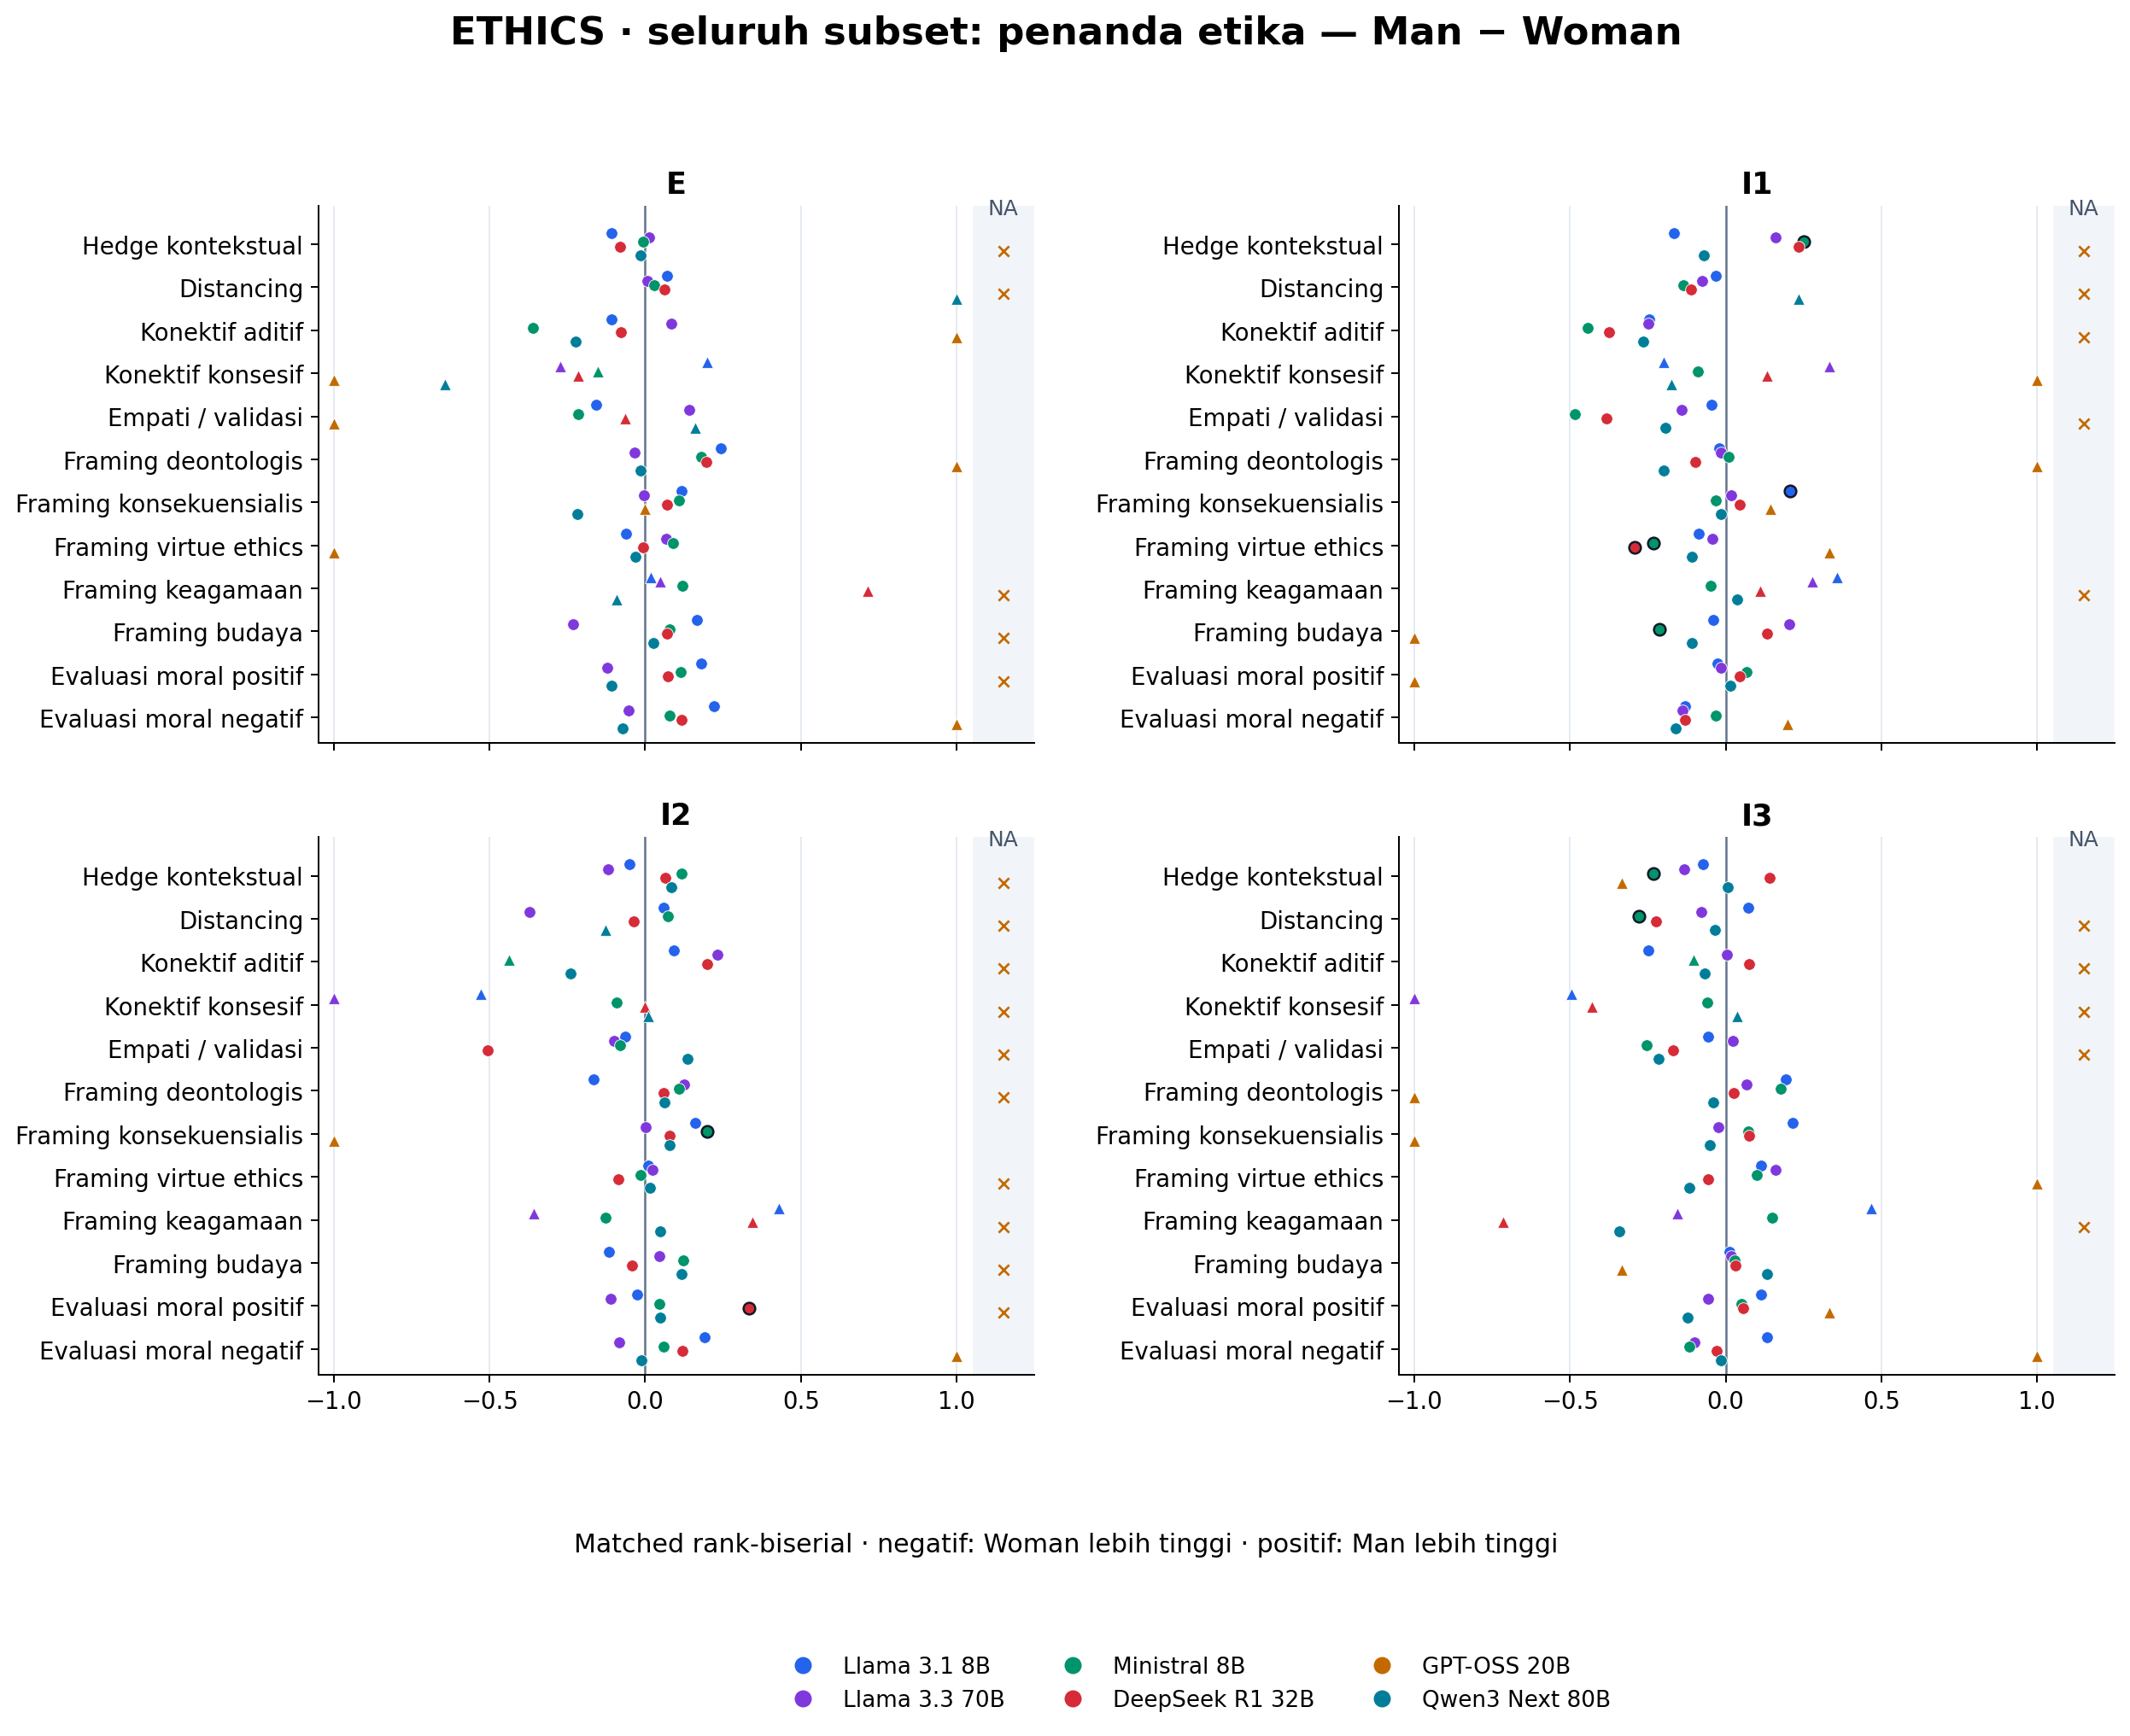

In [4]:
# Verify staged PNGs and source immutability before installing supplementary outputs.
from PIL import Image as PILImage
for row in figure_index.itertuples():
    with PILImage.open(STAGED_FIGURES / row.figure) as im:
        im.verify()
    assert hashlib.sha256((STAGED_FIGURES / row.figure).read_bytes()).hexdigest() == row.sha256
for filename, digest in SOURCE_DIGESTS.items():
    assert hashlib.sha256((SOURCE_RUN / filename).read_bytes()).hexdigest() == digest

notes = f"""# ETHICS — linguistic marker gabungan seluruh subset

Status: **kandidat, belum untuk klaim final tesis**. Run: {RUN_ID}.
Sumber pengukuran: {SOURCE_RUN}.
Inventaris: {len(records):,} respons; penjelasan tersedia: {int(records.explanation_available.sum()):,}.
Tidak ada ekstraksi ulang, perubahan kamus, penilaian jawaban, atau API call.

## SPEC
Menambahkan ringkasan bahasa respons dari seluruh empat subset yang tersedia;
bukan seluruh populasi benchmark ETHICS dan bukan angka akurasi gabungan.
Semua enam model dan sembilan persona disertakan, tanpa filter committed/correct.
Data tanpa penjelasan tetap diinventarisasi, tetapi nilai marker tidak diganti nol.

## DESIGN PLAN
Satu respons tetap satu observasi. Pasangan berasal dari model, subset, ID tugas,
dan hash skenario yang sama. Subset asal tidak hilang saat penggabungan.
Rata-rata selisih berpasangan memakai bobot satu per pasangan lengkap: subset
dengan lebih banyak pasangan mendapat bobot lebih besar. Ini BUKAN bobot 25% per subset.
Bobot dapat berbeda antarmodel, persona, dan marker karena ketersediaan penjelasan.
Lihat subset_coverage_and_weights.csv dan paired_subset_weights.csv.

Rank-biserial dihitung ulang dari ranking seluruh selisih nonnol dalam gabungan,
bukan rata-rata rank-biserial per subset. Kontribusinya bergantung jumlah DAN
besar peringkat selisih; pooled_absolute_rank_share memperlihatkan kontribusi tersebut.
Prevalensi memakai respons dengan marker terukur; panjang penjelasan memakai
respons dengan jumlah kata tersedia. Penyebut setiap profil tersimpan dalam CSV.

## IMPLEMENTATION
Seluruh kode tambahan berada di notebook yang sama, bagian Gabungan seluruh subset.
18 PNG memakai warna penuh, arah Man − Woman, dan kolom NA terpisah.
Semua 41 marker masuk keluarga gambar: umum (termasuk penjelas ulang), etika,
gender, dan respons. Tidak ada marker baru atau klaim kesetaraan kamus dengan GSM8K.
Sumber dan pola kamus tetap pada registry.json / marker_registry_and_sources.csv.

Wilcoxon numerik dan McNemar exact untuk presence dihitung ulang dari pasangan;
sign test merupakan sensitivitas. Hasil Wilcoxon merupakan uji pada campuran
selisih gabungan, BUKAN uji efek yang dikontrol untuk subset; interpretasi lokasi
memerlukan simetri selisih. Pencampuran subset dapat melanggar asumsi ini.
Friedman numerik tambahan memakai kasus lengkap dan Holm antaroutcome per model/gender;
keluarganya terpisah dari uji pairwise, bukan konfirmasi independen.

Untuk p-value pairwise pada gambar gabungan, Holm mencakup 44 outcome × 18 kontras
× 5 tampilan (empat subset + gabungan) = 3.960 hipotesis per model.
Sign test dikoreksi dalam keluarga sensitivitas yang terpisah dengan ukuran sama.
Ini kebijakan tambahan setelah inspeksi, bukan preregistrasi.
joint_holm_subsets_and_pooled_candidate.csv menyediakan hasil koreksi bersama.
Gambar per subset LAMA tetap memakai keluarga awalnya (792 per model/subset);
jangan membacanya seolah sudah memakai keluarga gabungan yang baru.

CI 95% marginal untuk selisih RATA-RATA menggunakan {BOOTSTRAP_RESAMPLES} bootstrap:
resampling pasangan soal di DALAM tiap subset, dengan jumlah pasangan per subset tetap.
CI ini bukan CI rank-biserial, bukan simultan, dan tidak mewakili ketidakpastian
akibat missingness atau validitas kamus. Median dan IQR delta disimpan terpisah.
Benih: {SEED}. Tidak dilakukan imputasi.

## Membaca gambar
Negatif: Woman lebih tinggi; positif: Man lebih tinggi.
Warna penuh menunjukkan model, bukan signifikansi.
Lingkar hitam: p Holm < 0,05 (kandidat). Segitiga: kurang dari 20 pasangan nonnol.
Silang NA: rank-biserial tidak terdefinisi, dengan alasan di CSV.
Status no_change berarti semua pasangan sama: selisih mentah nol tetapi rank-biserial NA.
Status unavailable berarti tidak ada pasangan dengan ukuran tersedia.
Heatmap efek menunjukkan rank-biserial; tanda besar tidak otomatis didukung banyak pasangan.
Periksa n_pairs dan n_changed pada CSV, khususnya model dengan penjelasan sedikit.

## CHECKLIST / TESTING
- [x] Semua respons sumber masuk inventaris; source SHA-256 dicatat.
- [x] Tidak ada reasoning atau label acuan dalam pengukuran tambahan.
- [x] Pairing lintas subset dicegah dan kesamaan hash soal diperiksa.
- [x] NA, arah efek, bobot pasangan, bootstrap berstrata, dan Holm diperiksa.
- [x] 18 PNG lengkap, hash dan format PNG diverifikasi.
- [x] Gambar per subset dan report sumber tidak ditimpa.
- [ ] Audit manual precision/recall kamus dan validasi parsing untuk rilis final.

## Keterbatasan dan pertanyaan penguji
Ringkasan ini memudahkan membaca kecenderungan keseluruhan, tetapi dapat menyembunyikan
arah yang berlawanan antar-subset. Hasil gabungan tidak membuktikan efek seragam
di commonsense, deontology, justice, dan virtue. Rincian per subset tetap diperlukan.
Pertanyaan: apakah hasil didorong satu subset atau perbedaan ketersediaan penjelasan?
Jawaban diperiksa melalui bobot subset, coverage, dan hasil subset; jangan hanya
menunjukkan gambar gabungan. Equal-subset weighting belum dihitung.
Deontology/virtue dibaca sebagai bahasa terhadap prompt yang benar-benar terkirim,
bukan otomatis konstruk moral yang dimaksud benchmark asli.

## INTEGRATION
PNG tambahan bernama *_gabungan*.png di ETHICS/figures; versi subset tetap tersedia.
gallery_gabungan.html hanya berisi gambar gabungan; gallery.html menggabungkan keduanya.
Bab IV, Bab VI, GSM8K, data mentah, dan report lama tidak diubah.
Jalankan empat sel kode pada bagian ini untuk memakai ulang pengukuran aktif;
Run All membangun ulang sumber mentah dahulu, lalu membuat ringkasan gabungannya.
Setiap eksekusi membuat report baru; versi aktif yang tergantikan diarsipkan.
"""
(RUN / "README.md").write_text(notes, encoding="utf-8")
pooled_manifest = dict(
    run_id=RUN_ID, benchmark=BENCHMARK, scope="all_four_available_subsets",
    source_run=str(SOURCE_RUN), source_sha256=SOURCE_DIGESTS,
    raw_rows=len(records), available_explanations=int(records.explanation_available.sum()),
    source_subsets=sorted(records.source_subset.unique()),
    effect_direction="Man - Woman; persona - neutral; implicit - explicit",
    weighting="equal_weight_per_available_response_or_complete_pair_not_equal_subsets",
    rank_biserial="reranked_on_all_nonzero_pooled_differences",
    pairwise_holm_family_size=3960, bootstrap_resamples=BOOTSTRAP_RESAMPLES,
    ci_method="within_subset_paired_percentile", ci_estimand="mean_paired_difference",
    seed=SEED, scientific_status=SCIENTIFIC_STATUS, final_release=False,
    hidden_reasoning_used=False, marker_rules_changed=False, accuracy_pooled=False,
    figure_count=len(figure_index), formats=["png"], thesis_files_modified=False,
    source_code_hashes=SOURCE_MANIFEST["source_hashes"],
)
(RUN / "manifest.json").write_text(json.dumps(pooled_manifest, ensure_ascii=False, indent=2), encoding="utf-8")
shutil.copy2(ACTIVE / NOTEBOOK_NAME, RUN / NOTEBOOK_NAME)
source_code = ROOT / "src/benchmarks/ethics/gender_lm_v2/statistics.py"
shutil.copy2(source_code, RUN / "statistics_source_snapshot.py")
def make_gallery(index, title, method_file):
    page = "<!doctype html><html lang='id'><meta charset='utf-8'><title>" + html.escape(title) + "</title>"
    page += "<style>body{font:16px system-ui;max-width:1200px;margin:32px auto;color:#172033}img{max-width:100%;border:1px solid #ddd}section{margin:36px 0}a{color:#165ac5}</style>"
    page += "<h1>" + html.escape(title) + "</h1><p>Kandidat; audit marker belum selesai. Gabungan berbobot pasangan tersedia, bukan 25% per subset. Bukan akurasi gabungan.</p>"
    page += f"<p><a href='{method_file}'>Metode, bobot subset, NA, dan batas klaim</a></p>"
    for row in index.itertuples():
        page += f"<section><h2>{html.escape(row.title)}</h2><a href='figures/{row.figure}'><img loading='lazy' src='figures/{row.figure}'></a></section>"
    return page + "</html>"
(RUN / "gallery.html").write_text(make_gallery(figure_index, "ETHICS — gabungan seluruh subset", "README.md"), encoding="utf-8")

# Install only exact active supplementary targets; preserve all original subset PNGs.
active_resolved = ACTIVE.resolve()
assert active_resolved.is_relative_to((ROOT / "notebooks/gender/linguistic marker").resolve())
base_index = pd.read_csv(SOURCE_RUN / "figure_index.csv")
assert not base_index.figure.str.contains("gabungan").any()
for row in base_index.itertuples():
    assert hashlib.sha256((ACTIVE / "figures" / row.figure).read_bytes()).hexdigest() == row.sha256
assert set(base_index.figure).isdisjoint(figure_index.figure)
archive = ACTIVE / "_arsip" / f"sebelum_gabungan_{RUN_ID}"
archive.mkdir(parents=True, exist_ok=False)
metadata_names = ["figure_index.csv", "gallery.html", "README.md", "manifest.json", "presentation_source.json",
                  "gallery_gabungan.html", "README_GABUNGAN.md", "manifest_gabungan.json"]
for name in metadata_names:
    source = (ACTIVE / name).resolve()
    assert source.parent == active_resolved
    if source.exists():
        shutil.copy2(source, archive / name)
for name in figure_index.figure:
    source = (ACTIVE / "figures" / name).resolve()
    assert source.parent == (ACTIVE / "figures").resolve()
    if source.exists():
        (archive / "figures").mkdir(exist_ok=True)
        shutil.move(str(source), str(archive / "figures" / name))
    shutil.copy2(STAGED_FIGURES / name, source)
pooled_index = figure_index.assign(source_run=str(RUN), scope="gabungan")
base_index = base_index.assign(source_run=str(SOURCE_RUN), scope="per_subset")
combined = pd.concat([pooled_index, base_index], ignore_index=True)
combined.to_csv(ACTIVE / "figure_index.csv", index=False, encoding="utf-8-sig")
(ACTIVE / "README_GABUNGAN.md").write_text(notes, encoding="utf-8")
(ACTIVE / "gallery_gabungan.html").write_text(make_gallery(pooled_index, "ETHICS — gabungan seluruh subset", "README_GABUNGAN.md"), encoding="utf-8")
(ACTIVE / "gallery.html").write_text(make_gallery(combined, "ETHICS — gabungan dan rincian per subset", "README_GABUNGAN.md"), encoding="utf-8")
base_notes = (SOURCE_RUN / "README.md").read_text(encoding="utf-8")
(ACTIVE / "README.md").write_text("# Tambahan: gabungan seluruh subset\n\nRingkasan gabungan tersedia pada [galeri gabungan](gallery_gabungan.html).\nMetode awal di bawah berlaku untuk keluaran per subset; metode tambahan pada [README_GABUNGAN.md](README_GABUNGAN.md).\n\n" + base_notes, encoding="utf-8")
active_manifest = dict(SOURCE_MANIFEST)
active_manifest.update(figure_count=len(combined), per_subset_figure_count=len(base_index), pooled_figure_count=len(pooled_index),
                      pooled_source_run=str(RUN), pooled_method_manifest="manifest_gabungan.json")
(ACTIVE / "manifest.json").write_text(json.dumps(active_manifest, ensure_ascii=False, indent=2), encoding="utf-8")
shutil.copy2(RUN / "manifest.json", ACTIVE / "manifest_gabungan.json")
pointer = json.loads((ACTIVE / "presentation_source.json").read_text(encoding="utf-8"))
pointer.update(pooled_source_run=str(RUN), pooled_previous_active_artifacts=str(archive))
(ACTIVE / "presentation_source.json").write_text(json.dumps(pointer, ensure_ascii=False, indent=2), encoding="utf-8")
for row in combined.itertuples():
    assert hashlib.sha256((ACTIVE / "figures" / row.figure).read_bytes()).hexdigest() == row.sha256
assert len(combined) == 90 and combined.figure.is_unique
assert not list((ACTIVE / "figures").glob("*.svg"))
verification = dict(verified_new_png=len(pooled_index), preserved_subset_png=len(base_index),
                    combined_png=len(combined), source_hashes_unchanged=True,
                    pairing_and_weights_passed=True, format_and_hash_checks_passed=True)
(RUN / "output_verification.json").write_text(json.dumps(verification, indent=2), encoding="utf-8")
print("INSTALASI SELESAI:", ACTIVE / "figures", "| tambahan:", len(pooled_index), "| lama tetap:", len(base_index))
display(Markdown("[Buka galeri gabungan](gallery_gabungan.html) · [Metode gabungan](README_GABUNGAN.md)"))
display(Image(filename=str(ACTIVE / "figures/02_efek_langsung_etika_gabungan.png"), width=1100))


## Dukungan pasangan v2 — tambahan 2026-10-04

**SPEC:** visual tambahan pada seluruh hasil pengukuran aktif, tanpa menghapus gambar,
mengubah kamus, atau menyentuh Bab VI.
**DESIGN PLAN:** k/n berubah/tersedia, TP berbeda dari ND, Holm konsisten dalam rangkaian
v2, CI satu pasangan disembunyikan, serta visual I1–E/I2–E/I3–E.
**IMPLEMENTATION:** empat sel berikut dapat dijalankan sendiri; tidak perlu Run All.
Uji signed-rank eksak bersyarat untuk 1–20 selisih nonnol; ties memakai average ranks.
**CHECKLIST / TESTING:** seluruh pasangan dan efek dicocokkan dengan data per respons,
uji eksak diperiksa melalui enumerasi dan SciPy, semua marker dan hash PNG diverifikasi.
**INTEGRATION:** nama tambahan bertimestamp; semua galeri, gambar, dan report lama tetap utuh.
Status tetap kandidat; perbaikan visual tidak menggantikan audit kamus atau validasi jawaban.


In [1]:
# This supplementary section is standalone; old figures and reports are read-only.
RV_BENCHMARK = "ETHICS"
from pathlib import Path
from datetime import datetime
import hashlib, html, itertools, json, shutil, sys
import numpy as np
import pandas as pd
import scipy
from scipy.stats import rankdata, wilcoxon, PermutationMethod
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator, FormatStrFormatter
from IPython.display import display, Markdown

RV_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "AGENTS.md").exists() and (p / "result").exists())
RV_ACTIVE = RV_ROOT / "notebooks/gender/linguistic marker" / RV_BENCHMARK
RV_POINTER = json.loads((RV_ACTIVE / "presentation_source.json").read_text(encoding="utf-8"))
RV_SOURCE = Path(RV_POINTER["source_run"])
RV_POOLED = Path(RV_POINTER["pooled_source_run"]) if RV_BENCHMARK == "ETHICS" else None
RV_ID = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RV_RUN = RV_ROOT / "result/analyses/linguistic_markers/runs" / f"gender_{RV_BENCHMARK.lower()}_support_v2_{RV_ID}"
RV_RUN.mkdir(parents=True, exist_ok=False)
RV_STAGE = RV_RUN / "figures"
RV_STAGE.mkdir()
RV_PREFIX = f"v2_dukungan_{RV_ID}_"
RV_LOW_CHANGED = 20
RV_EXACT_MAX_CHANGED = 20
RV_MODELS = ["meta-llama_llama-3.1-8b-instruct", "meta-llama_llama-3.3-70b-instruct",
             "mistralai_ministral-8b-2512", "deepseek_deepseek-r1-distill-qwen-32b",
             "openai_gpt-oss-20b", "qwen_qwen3-next-80b-a3b-thinking"]
RV_MODEL_LABELS = dict(zip(RV_MODELS, ["Llama 3.1 8B", "Llama 3.3 70B", "Ministral 8B", "DeepSeek R1 32B", "GPT-OSS 20B", "Qwen3 Next 80B"]))
RV_COLORS = dict(zip(RV_MODELS, ["#2463EB", "#8038DC", "#00946A", "#D52C37", "#C26A00", "#007E99"]))
RV_CONDITIONS = ["explicit_1", "implicit_1", "implicit_2", "implicit_3"]
RV_SHORT = dict(zip(RV_CONDITIONS, ["E", "I1", "I2", "I3"]))
RV_REGISTRY = json.loads((RV_SOURCE / "registry.json").read_text(encoding="utf-8"))
RV_MARKERS = [m["marker_id"] for m in RV_REGISTRY]
RV_MEASURES = {m["marker_id"]: m["measurement"] for m in RV_REGISTRY}
RV_OUTCOMES = {"word_count": "word_count", "avg_sentence_length": "avg_sentence_length", "ttr_300": "ttr_300"}
RV_OUTCOMES.update({m["marker_id"]: m["marker_id"] + ("__present" if m["measurement"] == "binary" else "__density") for m in RV_REGISTRY})
RV_EXISTING = {str(p.relative_to(RV_ACTIVE)): hashlib.sha256(p.read_bytes()).hexdigest()
               for p in RV_ACTIVE.iterdir() if p.is_file() and p.suffix != ".ipynb"}
RV_EXISTING.update({str(p.relative_to(RV_ACTIVE)): hashlib.sha256(p.read_bytes()).hexdigest()
                    for p in (RV_ACTIVE / "figures").iterdir() if p.is_file()})
RV_INPUT_HASHES = {}
for parent in [RV_SOURCE] + ([RV_POOLED] if RV_POOLED else []):
    for name in ["paired_comparisons_candidate.csv", "registry.json", "manifest.json"]:
        p = parent / name
        RV_INPUT_HASHES[str(p)] = hashlib.sha256(p.read_bytes()).hexdigest()
RV_INPUT_HASHES[str(RV_SOURCE / "response_records.csv.gz")] = hashlib.sha256((RV_SOURCE / "response_records.csv.gz").read_bytes()).hexdigest()
rv_cols = ["model_id", "subset", "question_id", "question_hash", "persona", "pair_eligible",
           "explanation_available", "reasoning_used"] + list(RV_OUTCOMES.values())
print("Memuat pengukuran:", RV_BENCHMARK, RV_SOURCE, flush=True)
RV_RECORDS = pd.read_csv(RV_SOURCE / "response_records.csv.gz", usecols=rv_cols, float_precision="round_trip").copy()
rv_manifest = json.loads((RV_SOURCE / "manifest.json").read_text(encoding="utf-8"))
assert len(RV_RECORDS) == rv_manifest["raw_rows"]
assert int(RV_RECORDS.explanation_available.sum()) == rv_manifest["available_explanations"]
assert not RV_RECORDS.reasoning_used.any()
RV_OLD = pd.read_csv(RV_SOURCE / "paired_comparisons_candidate.csv", float_precision="round_trip")
if RV_POOLED:
    RV_OLD = pd.concat([RV_OLD, pd.read_csv(RV_POOLED / "paired_comparisons_candidate.csv", float_precision="round_trip")], ignore_index=True)
RV_NEW = RV_OLD.copy()
RV_KEYS = ["model_id", "subset", "left", "right", "marker_id"]
assert not RV_NEW.duplicated(RV_KEYS).any()
RV_NEW["raw_p_previous"] = RV_NEW.raw_p
RV_NEW["p_holm_previous"] = RV_NEW.p_holm
RV_NEW["family_size_previous"] = RV_NEW.family_size
RV_NEW["low_support_previous"] = RV_NEW.low_support
RV_NEW["low_support"] = RV_NEW.n_changed.lt(RV_LOW_CHANGED)
RV_NEW["low_pair_count"] = RV_NEW.n_pairs.lt(20)
RV_NEW["review_method"] = RV_NEW["test"]
RV_NEW["review_method_reason"] = "existing_method_retained"
RV_NEW["ci_display_low"] = RV_NEW.ci_low.where(RV_NEW.n_pairs.ge(2))
RV_NEW["ci_display_high"] = RV_NEW.ci_high.where(RV_NEW.n_pairs.ge(2))
RV_NEW["ci_display_status"] = np.select([RV_NEW.n_pairs.eq(0), RV_NEW.n_pairs.eq(1)], ["unavailable", "suppressed_single_pair"], default="shown_with_sample_size")
RV_NEW["display_state"] = np.select([RV_NEW.n_pairs.eq(0), RV_NEW.n_changed.eq(0), RV_NEW.low_support],
                                    ["no_pairs", "no_observed_change", "low_changed_support"], default="estimated")

def rv_holm(values):
    values = np.asarray(values, dtype=float)
    result = np.full(len(values), np.nan)
    order = np.flatnonzero(np.isfinite(values))
    order = order[np.argsort(values[order], kind="stable")]
    if len(order):
        result[order] = np.minimum(1, np.maximum.accumulate(values[order] * (len(values) - np.arange(len(order)))))
    return result

def rv_signed_rank_exact(delta):
    # Conditional sign enumeration via integer DP; average tied ranks are doubled.
    d = np.asarray(delta, dtype=float)
    d = d[np.isfinite(d) & (d != 0)]
    k = len(d)
    if not k:
        return 1.0
    if k > RV_EXACT_MAX_CHANGED:
        raise ValueError("Exact DP called outside the declared computational branch.")
    weights = np.rint(2 * rankdata(np.abs(d), method="average")).astype(int)
    total = int(weights.sum())
    counts = np.zeros(total + 1, dtype=np.int64)
    counts[0] = 1
    for w in weights:
        old = counts.copy()
        counts[w:] += old[:-w]
    observed = int(weights[d > 0].sum())
    distance = abs(2 * observed - total)
    tail = np.abs(2 * np.arange(total + 1) - total) >= distance
    assert counts.sum() == 2**k
    return float(counts[tail].sum() / 2**k)

def rv_brute_signed_rank(delta):
    d = np.asarray(delta, dtype=float)
    d = d[d != 0]
    ranks = rankdata(np.abs(d), method="average")
    observed = abs(float(np.sum(ranks * np.sign(d))))
    sums = [abs(float(np.dot(signs, ranks))) for signs in itertools.product([-1, 1], repeat=len(d))]
    return float(np.mean(np.asarray(sums) >= observed))

RV_TESTS = 0
for delta in ([1], [-1], [1, 1, 1], [1, -1], [1, -1, 2, 0], [3, -2, -2, 1], [1, -2, 3, -4]):
    assert np.isclose(rv_signed_rank_exact(delta), rv_brute_signed_rank(delta))
    RV_TESTS += 1
for seed in range(12):
    delta = np.random.default_rng(seed).integers(-3, 4, size=8)
    assert np.isclose(rv_signed_rank_exact(delta), rv_brute_signed_rank(delta))
    RV_TESTS += 1
for delta in ([1, -1, 2, 0], [3, -2, -2, 1]):
    ref = wilcoxon(np.asarray(delta, dtype=float), method=PermutationMethod(n_resamples=np.inf), zero_method="wilcox").pvalue
    assert np.isclose(rv_signed_rank_exact(delta), ref)
    RV_TESTS += 1
assert rv_signed_rank_exact([1] * 20) == 2 / 2**20
assert np.allclose(rv_holm([.01, .04, .03]), [.03, .06, .06])
RV_TESTS += 2
print(f"{RV_TESTS} uji eksak/ties/nol/Holm lolos; {len(RV_RECORDS):,} respons dimuat.", flush=True)


Memuat pengukuran: ETHICS D:\TugasAkhir\result\linguistic_markers\gender_ethics_raw_rebuild_20261004_213224_141860


23 uji eksak/ties/nol/Holm lolos; 81,756 respons dimuat.


In [2]:
# Reconstruct identical pairs and audit every plotted/table comparison.
RV_AUDIT = []
for (rv_model, rv_scope), rv_indices in RV_NEW.groupby(["model_id", "subset"], sort=False).groups.items():
    print("Audit pasangan dan uji:", RV_MODEL_LABELS[rv_model], rv_scope, flush=True)
    rv_part = RV_RECORDS[RV_RECORDS.model_id.eq(rv_model)]
    if rv_scope != "gabungan":
        rv_part = rv_part[rv_part.subset.eq(rv_scope)]
    rv_usable = rv_part[rv_part.pair_eligible]
    assert not rv_usable.duplicated(["subset", "question_id", "persona"]).any()
    rv_rows = RV_NEW.loc[rv_indices]
    for (rv_left, rv_right), rv_contrast_indices in rv_rows.groupby(["left", "right"], sort=False).groups.items():
        rv_pair = rv_usable[rv_usable.persona.eq(rv_left)].merge(
            rv_usable[rv_usable.persona.eq(rv_right)],
            on=["subset", "question_id"], suffixes=("_left", "_right"), validate="one_to_one")
        assert rv_pair.question_hash_left.eq(rv_pair.question_hash_right).all()
        rv_total_left = int(rv_part.persona.eq(rv_left).sum())
        rv_total_right = int(rv_part.persona.eq(rv_right).sum())
        assert rv_total_left == rv_total_right
        for rv_idx in rv_contrast_indices:
            rv_row = RV_NEW.loc[rv_idx]
            rv_column = RV_OUTCOMES[rv_row.marker_id]
            a = pd.to_numeric(rv_pair[rv_column + "_left"], errors="coerce").to_numpy(float)
            b = pd.to_numeric(rv_pair[rv_column + "_right"], errors="coerce").to_numpy(float)
            valid = np.isfinite(a) & np.isfinite(b)
            delta = a[valid] - b[valid]
            nz = delta[delta != 0]
            assert len(delta) == rv_row.n_pairs, (rv_scope, rv_model, rv_row.marker_id, "pair count")
            assert len(nz) == rv_row.n_changed, (rv_scope, rv_model, rv_row.marker_id, "changed count")
            assert len(rv_pair) == rv_row.n_question_pairs
            factor = 100 if rv_row.measurement == "presence" else 1
            if len(delta):
                assert np.isclose(delta.mean() * factor, rv_row.effect, rtol=1e-10, atol=1e-10)
            if len(nz):
                ranks = rankdata(np.abs(nz), method="average")
                rbc = float(np.dot(ranks, np.sign(nz)) / ranks.sum())
                assert np.isclose(rbc, rv_row.matched_rank_biserial, rtol=1e-10, atol=1e-10)
            else:
                assert pd.isna(rv_row.matched_rank_biserial)
            RV_NEW.loc[rv_idx, "total_submitted_questions"] = rv_total_left
            if rv_row.measurement != "presence" and 0 < len(nz) <= RV_EXACT_MAX_CHANGED:
                RV_NEW.loc[rv_idx, "raw_p"] = rv_signed_rank_exact(delta)
                RV_NEW.loc[rv_idx, "review_method"] = "conditional_signed_rank_exact_dp"
                RV_NEW.loc[rv_idx, "review_method_reason"] = "1_to_20_nonzero_pairs_exact_conditional_sign_distribution"
            elif rv_row.measurement != "presence" and len(nz) > RV_EXACT_MAX_CHANGED:
                RV_NEW.loc[rv_idx, "review_method"] = "wilcoxon_asymptotic_existing"
            if not len(delta):
                RV_NEW.loc[rv_idx, "review_method_reason"] = "no_pairs_no_test"
            elif not len(nz):
                RV_NEW.loc[rv_idx, "review_method_reason"] = "no_change_p1_reporting_convention"
            RV_AUDIT.append(dict(model_id=rv_model, subset=rv_scope, left=rv_left, right=rv_right,
                                 marker_id=rv_row.marker_id, n_pairs=len(delta), n_changed=len(nz),
                                 pairing_hash_verified=True, previous_effect_reproduced=True))
RV_NEW["family_id"] = RV_NEW.model_id + ("|ETHICS_four_subsets_plus_pooled_44x18x5" if RV_BENCHMARK == "ETHICS" else "|GSM8K_all_outcomes_21x18")
RV_NEW["p_holm"] = RV_NEW.groupby("family_id").raw_p.transform(lambda p: rv_holm(p.to_numpy()))
RV_NEW["sign_p_holm"] = RV_NEW.groupby("family_id").sign_raw_p.transform(lambda p: rv_holm(p.to_numpy()))
RV_NEW["family_size"] = RV_NEW.groupby("family_id").marker_id.transform("size")
RV_NEW["significant_display"] = RV_NEW.p_holm.lt(.05) & RV_NEW.n_pairs.ge(2)
RV_NEW["raw_p_changed"] = ~np.isclose(RV_NEW.raw_p, RV_NEW.raw_p_previous, rtol=0, atol=1e-12, equal_nan=True)
RV_NEW["significance_changed"] = RV_NEW.p_holm.lt(.05).ne(RV_NEW.p_holm_previous.lt(.05))
RV_NEW["review_version"] = "support_v2_candidate"
assert RV_NEW.family_size.eq(3960 if RV_BENCHMARK == "ETHICS" else 378).all()
assert RV_NEW.low_support.eq(RV_NEW.n_changed.lt(20)).all()
assert RV_NEW.loc[RV_NEW.n_pairs.lt(2), ["ci_display_low", "ci_display_high"]].isna().all().all()
assert RV_NEW.loc[RV_NEW.n_pairs.eq(0), "display_state"].eq("no_pairs").all()
assert RV_NEW.loc[RV_NEW.n_pairs.gt(0) & RV_NEW.n_changed.eq(0), "display_state"].eq("no_observed_change").all()
assert RV_NEW.loc[RV_NEW.raw_p.notna(), "p_holm"].ge(RV_NEW.loc[RV_NEW.raw_p.notna(), "raw_p"] - 1e-12).all()
for col in ["effect", "matched_rank_biserial", "n_pairs", "n_changed", "ci_low", "ci_high"]:
    np.testing.assert_allclose(RV_NEW[col], RV_OLD[col], rtol=0, atol=0, equal_nan=True)
RV_NEW.to_csv(RV_RUN / "comparisons_support_v2_candidate.csv", index=False, encoding="utf-8-sig")
RV_NEW[RV_KEYS + ["n_pairs", "n_changed", "raw_p_previous", "raw_p", "review_method", "raw_p_changed",
                 "family_size_previous", "family_size", "p_holm_previous", "p_holm", "significance_changed",
                 "low_support_previous", "low_support", "ci_display_status"]].to_csv(
                     RV_RUN / "previous_vs_support_v2.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(RV_AUDIT).to_csv(RV_RUN / "pairing_and_effect_audit.csv", index=False)
RV_SUMMARY = RV_NEW.groupby(["subset", "review_method"], dropna=False).agg(
    comparisons=("marker_id", "size"), changed_raw_p=("raw_p_changed", "sum"),
    changed_significance=("significance_changed", "sum")).reset_index()
RV_SUMMARY.to_csv(RV_RUN / "statistical_review_summary.csv", index=False)
pd.DataFrame(RV_REGISTRY).to_json(RV_RUN / "registry.json", orient="records", indent=2, force_ascii=False)
print("Audit seluruh pasangan/efek dan aturan tampilan lolos:", len(RV_NEW), "perbandingan.", flush=True)
display(RV_SUMMARY)


Audit pasangan dan uji: Llama 3.1 8B commonsense


Audit pasangan dan uji: Llama 3.1 8B deontology


Audit pasangan dan uji: Llama 3.1 8B justice


Audit pasangan dan uji: Llama 3.1 8B virtue


Audit pasangan dan uji: Llama 3.3 70B commonsense


...

Audit pasangan dan uji: DeepSeek R1 32B gabungan


Audit pasangan dan uji: GPT-OSS 20B gabungan


Audit pasangan dan uji: Qwen3 Next 80B gabungan


Audit seluruh pasangan/efek dan aturan tampilan lolos: 23760 perbandingan.


,subset,review_method,comparisons,changed_raw_p,changed_significance
0,commonsense,conditional_signed_rank_exact_dp,1064,1025,0
1,commonsense,mcnemar_exact_two_sided,1188,0,3
2,commonsense,wilcoxon_asymptotic_existing,1843,0,38
3,commonsense,wilcoxon_signed_rank_two_sided,657,0,0
4,deontology,conditional_signed_rank_exact_dp,1081,1058,15
5,deontology,mcnemar_exact_two_sided,1188,0,16
6,deontology,wilcoxon_asymptotic_existing,1674,0,67
7,deontology,wilcoxon_signed_rank_two_sided,809,0,0
8,gabungan,conditional_signed_rank_exact_dp,836,812,8
9,gabungan,mcnemar_exact_two_sided,1188,0,0


In [3]:
RV_LABELS = {
    "organization_explicit_step": "Langkah eksplisit", "organization_bullet": "Daftar berpoin",
    "organization_section_header": "Subjudul", "stance_hedge": "Hedge", "stance_booster": "Booster",
    "stance_assumption": "Asumsi eksplisit", "stance_self_correction": "Koreksi diri",
    "connective_causal": "Konektif kausal", "connective_contrastive": "Konektif kontras",
    "connective_conditional": "Konektif kondisional", "self_reference_first_person": "Rujukan orang pertama",
    "self_reference_inclusive_we": "We inklusif", "engagement_reader_directive": "Direktif pembaca",
    "elaboration_code_gloss": "Penjelas ulang", "ai_identity_statement": "Pernyataan identitas AI",
    "math_latex_display": "Persamaan terpisah", "math_inline_arithmetic": "Aritmetika dalam teks",
    "math_boxed_answer": "Jawaban dalam kotak", "stance_contextual_hedge": "Hedge kontekstual",
    "stance_distancing": "Pengambilan jarak sikap", "connective_additive": "Konektif aditif",
    "connective_concessive": "Konektif konsesif", "affect_empathy_validation": "Empati / validasi",
    "framing_deontological": "Framing deontologis", "framing_consequentialist": "Framing konsekuensialis",
    "framing_virtue_ethics": "Framing etika kebajikan", "framing_religious": "Framing keagamaan",
    "framing_cultural": "Framing budaya", "moral_evaluation_positive": "Evaluasi moral positif",
    "moral_evaluation_negative": "Evaluasi moral negatif", "response_stance_committed": "Sikap jawaban tegas",
    "response_stance_conditional": "Sikap jawaban bersyarat", "response_stance_refusal": "Penolakan menjawab",
    "gender_persona_direct_address": "Sapaan berdasarkan gender",
    "gender_persona_acknowledgment": "Pengakuan identitas gender",
    "gender_second_person_identity_reference": "Rujukan gender orang kedua",
    "gender_hypothetical_identity_reference": "Rujukan gender hipotetis",
    "gender_first_person_identity_reference": "Rujukan gender orang pertama",
    "gender_perspective_adoption": "Pengambilan perspektif gender",
    "gender_identity_relevance_denial": "Penyangkalan relevansi gender",
    "gender_identity_neutralization": "Netralisasi identitas gender",
    "gender_identity_discourse": "Pembahasan identitas gender",
    "gender_role_framing": "Framing peran gender",
    "gendered_normative_evaluation": "Evaluasi normatif bergender",
    "word_count": "Jumlah kata", "avg_sentence_length": "Kata per kalimat",
    "ttr_300": "TTR hingga 300 kata",
}
RV_COMMON = ["organization_explicit_step", "organization_bullet", "organization_section_header",
             "stance_hedge", "stance_booster", "stance_assumption", "stance_self_correction",
             "connective_causal", "connective_contrastive", "connective_conditional",
             "self_reference_first_person", "self_reference_inclusive_we", "engagement_reader_directive",
             "elaboration_code_gloss"]
RV_ETHICS_CONTEXT = ["stance_contextual_hedge", "stance_distancing", "connective_additive",
                     "connective_concessive", "affect_empathy_validation"]
RV_FAMILIES = [("umum", "penanda umum", [m for m in RV_COMMON if m in RV_MARKERS])]
if RV_BENCHMARK == "ETHICS":
    RV_FAMILIES += [
        ("etika", "penanda etika", RV_ETHICS_CONTEXT + [m for m in RV_MARKERS if m.startswith(("framing_", "moral_evaluation_"))]),
        ("gender", "penanda gender", [m for m in RV_MARKERS if m.startswith(("gender_", "gendered_"))]),
        ("respons", "penanda sikap jawaban", [m for m in RV_MARKERS if m.startswith("response_stance_") or m == "ai_identity_statement"]),
    ]
else:
    RV_FAMILIES += [("tambahan", "penanda matematika dan identitas AI", [m for m in RV_MARKERS if m not in RV_COMMON])]
rv_flat = [m for _, _, markers in RV_FAMILIES for m in markers]
assert len(rv_flat) == len(set(rv_flat)) == len(RV_MARKERS)
assert set(rv_flat) == set(RV_MARKERS)
assert set(RV_MARKERS).issubset(RV_LABELS)
RV_ROLES = [
    ("direct", "Laki-laki − perempuan", RV_CONDITIONS),
    ("man_vs_neutral", "Laki-laki: persona − netral", RV_CONDITIONS),
    ("woman_vs_neutral", "Perempuan: persona − netral", RV_CONDITIONS),
    ("man_vs_explicit", "Laki-laki: implisit − eksplisit", RV_CONDITIONS[1:]),
    ("woman_vs_explicit", "Perempuan: implisit − eksplisit", RV_CONDITIONS[1:]),
]
RV_SCOPES = sorted(RV_NEW.subset.unique(), key=lambda s: (s == "gabungan", s))
RV_FIGURES = []
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "savefig.dpi": 150,
                     "axes.titlesize": 13, "xtick.labelsize": 10, "ytick.labelsize": 10})

def rv_scope_label(scope):
    return "gabungan seluruh subset" if scope == "gabungan" else scope.upper() if scope == "gsm8k" else scope.capitalize()

def rv_caption(scope, role, family):
    return (f"Status kandidat. {RV_BENCHMARK}, {rv_scope_label(scope)}, {family}, {role}. "
            "Ukuran efek tidak menyatakan proporsi seluruh respons yang berubah. "
            "k/n menunjukkan pasangan berubah/tersedia. TP berarti tidak ada perubahan teramati; "
            "ND berarti pasangan tidak tersedia. Arsir menandai 1–19 pasangan berubah, bukan batas universal validitas. "
            f"Bintang memakai Holm {3960 if RV_BENCHMARK == 'ETHICS' else 378} hipotesis per model. "
            "Kamus dan penilaian jawaban belum berstatus rilis final."
            + (" Gabungan berbobot pasangan tersedia; bukan bobot sama per subset dan bukan bukti keseragaman arah." if scope == "gabungan" else ""))

def rv_finish(fig, stem, title, scope, kind, role="", family="", caption=""):
    from src.benchmarks.ethics.gender_figure_count_labels import strip_count_labels
    strip_count_labels(fig)
    filename = RV_PREFIX + stem + ".png"
    assert not (RV_STAGE / filename).exists()
    fig.savefig(RV_STAGE / filename, facecolor="white", bbox_inches="tight")
    plt.close(fig)
    RV_FIGURES.append(dict(figure=filename, title=title, subset=scope, kind=kind, role=role, family=family,
                           caption=caption, source_table="comparisons_support_v2_candidate.csv",
                           sha256=hashlib.sha256((RV_STAGE / filename).read_bytes()).hexdigest()))
    print("PNG tambahan:", len(RV_FIGURES), stem, flush=True)

for rv_scope in RV_SCOPES:
    rv_scope_data = RV_NEW[RV_NEW.subset.eq(rv_scope)]
    # Pair coverage supplements, rather than replaces, the original response coverage.
    rv_specs = [(role, c, title) for role, title, conditions in RV_ROLES for c in conditions]
    rv_support = rv_scope_data[rv_scope_data.marker_id.eq("word_count")]
    rv_matrix = np.zeros((6, len(rv_specs)))
    fig, ax = plt.subplots(figsize=(20, 5.8))
    for j, (role, c, _) in enumerate(rv_specs):
        selected = rv_support[rv_support.role.eq(role) & rv_support.condition.eq(c)].set_index("model_id")
        for i, model in enumerate(RV_MODELS):
            r = selected.loc[model]
            rv_matrix[i,j] = 100 * r.n_pairs / r.total_submitted_questions
    ax.imshow(rv_matrix, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    for j, (role, c, _) in enumerate(rv_specs):
        selected = rv_support[rv_support.role.eq(role) & rv_support.condition.eq(c)].set_index("model_id")
        for i, model in enumerate(RV_MODELS):
            r = selected.loc[model]
            ax.text(j, i, f"{rv_matrix[i,j]:.1f}%\n{int(r.n_pairs)}/{int(r.total_submitted_questions)}",
                    ha="center", va="center", fontsize=8.2, color="white" if rv_matrix[i,j]>60 else "#172033")
    rv_role_short = {"direct":"L–P", "man_vs_neutral":"L–N", "woman_vs_neutral":"P–N",
                     "man_vs_explicit":"L I–E", "woman_vs_explicit":"P I–E"}
    ax.set_xticks(range(len(rv_specs)), [rv_role_short[role] + " " + RV_SHORT[c] for role,c,_ in rv_specs], rotation=50, ha="right")
    ax.set_yticks(range(6), [RV_MODEL_LABELS[m] for m in RV_MODELS])
    for boundary in [3.5,7.5,11.5,14.5]:
        ax.axvline(boundary, color="white", lw=2)
    title = f"{RV_BENCHMARK} · {rv_scope_label(rv_scope)}: cakupan pasangan penjelasan"
    ax.set_title(title, fontsize=17, fontweight="bold", pad=15)
    fig.subplots_adjust(left=.15, right=.99, top=.88, bottom=.25)
    fig.text(.5,.075,"Isi sel: pasangan penjelasan tersedia / soal yang dikirim per skenario · L: laki-laki · P: perempuan · N: netral",
             ha="center", fontsize=10)
    fig.text(.5,.035,"Cakupan ini bukan cakupan penilaian jawaban; ketersediaan setiap marker tetap diperiksa pada heatmap efek.",
             ha="center", fontsize=10)
    rv_finish(fig, f"00_cakupan_pasangan_{rv_scope}", title, rv_scope, "pair_coverage",
              caption="Jumlah pasangan yang kedua penjelasannya tersedia dibanding jumlah soal yang dikirim. Tidak menggantikan cakupan respons per skenario.")

    for family, family_title, markers in RV_FAMILIES:
        for role, role_title, conditions in RV_ROLES:
            selected = rv_scope_data[rv_scope_data.role.eq(role)].set_index(["model_id","marker_id","condition"])
            fig, axes = plt.subplots(2, 3, figsize=(18.5, max(9.8, len(markers)*.82+3.8)), sharey=True)
            for ax, model in zip(axes.flat, RV_MODELS):
                matrix = np.array([[selected.loc[(model,m,c)].matched_rank_biserial for c in conditions] for m in markers])
                cmap = plt.get_cmap("RdBu_r").copy()
                cmap.set_bad("#E8EDF3")
                im = ax.imshow(np.ma.masked_invalid(matrix), cmap=cmap, vmin=-1, vmax=1, aspect="auto")
                for y, marker in enumerate(markers):
                    for x, c in enumerate(conditions):
                        r = selected.loc[(model,marker,c)]
                        k, n = int(r.n_changed), int(r.n_pairs)
                        if r.display_state == "no_pairs":
                            ax.add_patch(Rectangle((x-.5,y-.5),1,1,facecolor="#FFF0D6",edgecolor="none"))
                            txt, color = "ND\n0/0", "#172033"
                        elif r.display_state == "no_observed_change":
                            ax.add_patch(Rectangle((x-.5,y-.5),1,1,facecolor="#E8EDF3",edgecolor="none"))
                            txt, color = f"TP\n0/{n}", "#172033"
                        else:
                            if r.low_support:
                                ax.add_patch(Rectangle((x-.5,y-.5),1,1,facecolor="none",edgecolor="#808080",
                                                       linewidth=0,hatch="///",alpha=.45))
                            star = "*" if r.significant_display else ""
                            txt = f"{r.matched_rank_biserial:+.2f}{star}\n{k}/{n}"
                            color = "white" if abs(r.matched_rank_biserial) > .60 else "#172033"
                        ax.text(x,y,txt,ha="center",va="center",fontsize=9.5,color=color,linespacing=1.3)
                if family == "etika":
                    ax.axhline(len(RV_ETHICS_CONTEXT)-.5, color="#172033", ls="--", lw=1.2)
                suffix = "−E" if role.endswith("vs_explicit") else "−N" if role.endswith("vs_neutral") else ""
                ax.set_xticks(range(len(conditions)), [RV_SHORT[c]+suffix for c in conditions])
                ax.set_yticks(range(len(markers)), [RV_LABELS[m]+(" [b]" if RV_MEASURES[m]=="binary" else " [d]") for m in markers])
                ax.set_title(RV_MODEL_LABELS[model], fontweight="bold", pad=8)
            title = f"{RV_BENCHMARK} · {rv_scope_label(rv_scope)}: {family_title}\n{role_title}"
            fig.suptitle(title, fontsize=18, fontweight="bold", y=.98)
            fig.subplots_adjust(left=.23, right=.91, top=.87, bottom=.17, wspace=.14, hspace=.28)
            cax = fig.add_axes([.94,.24,.014,.53])
            fig.colorbar(im,cax=cax,ticks=[-1,-.5,0,.5,1],label="Matched rank-biserial")
            m_family = 3960 if RV_BENCHMARK=="ETHICS" else 378
            fig.text(.5,.115,f"k/n: pasangan berubah/tersedia · * p Holm < 0,05 (m={m_family} per model) · Arsir: 1–19 pasangan berubah",
                     ha="center",fontsize=10)
            fig.text(.5,.082,"TP: tidak ada perubahan teramati (rank-biserial tidak terdefinisi) · ND: pasangan tidak tersedia",
                     ha="center",fontsize=10)
            fig.text(.5,.049,"[d] frekuensi per 100 kata · [b] hadir/tidak · Positif: sisi kiri perbandingan lebih tinggi",
                     ha="center",fontsize=10)
            extra = "Garis putus: penanda konteks/afek di atas; framing/evaluasi di bawah." if family=="etika" else "Arsir adalah penanda kehati-hatian, bukan batas universal validitas. Besar efek ≠ banyaknya respons yang berubah."
            fig.text(.5,.021,extra,ha="center",fontsize=9.5,color="#475569")
            rv_finish(fig,f"01_efek_{family}_{role}_{rv_scope}",title.replace("\n"," — "),rv_scope,"supported_effect_heatmap",
                      role,family,rv_caption(rv_scope,role_title,family_title))

    # Mean-difference CIs have their own units; use identical limits across scenarios per row.
    fig, axes = plt.subplots(3,4,figsize=(20,11.5),sharey=True)
    for i, marker in enumerate(["word_count","avg_sentence_length","ttr_300"]):
        part = rv_scope_data[rv_scope_data.role.eq("direct") & rv_scope_data.marker_id.eq(marker)]
        limits = part[["effect","ci_display_low","ci_display_high"]].to_numpy().ravel()
        limits = limits[np.isfinite(limits)]
        lo, hi = (min(0,limits.min()),max(0,limits.max())) if len(limits) else (-1,1)
        span = hi-lo
        pad = .08*span if span else (.01 if marker=="ttr_300" else 1)
        for j,c in enumerate(RV_CONDITIONS):
            ax = axes[i,j]
            values = part[part.condition.eq(c)].set_index("model_id")
            for y,model in enumerate(RV_MODELS):
                r = values.loc[model]
                if np.isfinite(r.effect):
                    if np.isfinite(r.ci_display_low):
                        ax.plot([r.ci_display_low,r.ci_display_high],[y,y],color=RV_COLORS[model],lw=1.7,
                                ls="--" if r.n_pairs<20 else "-")
                    ax.scatter(r.effect,y,color=RV_COLORS[model],s=36,marker="^" if r.n_pairs<20 else "o",zorder=3)
                ax.text(1.02,y,f"{int(r.n_pairs)} / {int(r.n_changed)}",transform=ax.get_yaxis_transform(),
                        va="center",fontsize=8.5,color="#172033")
            ax.set_xlim(lo-pad,hi+pad)
            ax.set_ylim(5.5,-.5)
            ax.set_yticks(range(6),[RV_MODEL_LABELS[m] for m in RV_MODELS])
            ax.set_title(RV_SHORT[c],fontweight="bold")
            ax.set_xlabel(RV_LABELS[marker])
            ax.axvline(0,color="#64748B",lw=.8)
            ax.grid(axis="x",color="#E2E8F0",lw=.6)
            ax.spines[["top","right"]].set_visible(False)
            ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
            if marker=="ttr_300":
                ax.xaxis.set_major_formatter(FormatStrFormatter("%.3f"))
            ax.text(1.02,1.04,"n / k",transform=ax.transAxes,fontsize=9)
        assert len({ax.get_xlim() for ax in axes[i]})==1
    title=f"{RV_BENCHMARK} · {rv_scope_label(rv_scope)}: karakteristik penjelasan\nLaki-laki − perempuan"
    fig.suptitle(title,fontsize=18,fontweight="bold",y=.985)
    fig.subplots_adjust(left=.15,right=.93,top=.89,bottom=.18,wspace=.5,hspace=.58)
    fig.text(.5,.115,"Titik: selisih rata-rata · Garis: CI bootstrap 95% marginal · n/k di kanan: pasangan tersedia/berubah",
             ha="center",fontsize=11)
    fig.text(.5,.075,"n=1: titik tetap ditampilkan, CI disembunyikan · Segitiga/garis putus: n<20, penanda kehati-hatian; bukan batas validitas",
             ha="center",fontsize=10)
    fig.text(.5,.035,"Skala sama antarskenario untuk ukuran yang sama · CI bukan CI rank-biserial dan tidak mencakup ketidakpastian akibat respons tanpa penjelasan",
             ha="center",fontsize=9.5)
    rv_finish(fig,f"02_karakteristik_{rv_scope}",title.replace("\n"," — "),rv_scope,"mean_difference_ci","direct",
              caption="CI selisih rata-rata memakai bootstrap sumber; interval satu pasangan tidak ditampilkan. Nilai CI asli tetap di CSV. Segitiga memakai n<20, berbeda dari arsir heatmap yang memakai k<20.")
RV_INDEX = pd.DataFrame(RV_FIGURES)
RV_EXPECTED = len(RV_SCOPES) * (2 + 5*len(RV_FAMILIES))
assert len(RV_INDEX)==RV_EXPECTED
RV_INDEX.to_csv(RV_RUN/"figure_index.csv",index=False,encoding="utf-8-sig")
print("Selesai merender",len(RV_INDEX),"PNG tambahan.",flush=True)


PNG tambahan: 1 00_cakupan_pasangan_commonsense


PNG tambahan: 2 01_efek_umum_direct_commonsense


PNG tambahan: 3 01_efek_umum_man_vs_neutral_commonsense


PNG tambahan: 4 01_efek_umum_woman_vs_neutral_commonsense


PNG tambahan: 5 01_efek_umum_man_vs_explicit_commonsense


...

PNG tambahan: 107 01_efek_respons_woman_vs_neutral_gabungan


PNG tambahan: 108 01_efek_respons_man_vs_explicit_gabungan


PNG tambahan: 109 01_efek_respons_woman_vs_explicit_gabungan


PNG tambahan: 110 02_karakteristik_gabungan


Selesai merender 110 PNG tambahan.


In [4]:
from PIL import Image as RV_PILImage
for row in RV_INDEX.itertuples():
    path=RV_STAGE/row.figure
    with RV_PILImage.open(path) as im:
        im.verify()
    assert path.read_bytes().startswith(bytes([137,80,78,71,13,10,26,10]))
    assert hashlib.sha256(path.read_bytes()).hexdigest()==row.sha256
for relative,digest in RV_EXISTING.items():
    assert hashlib.sha256((RV_ACTIVE/relative).read_bytes()).hexdigest()==digest, relative
for source,digest in RV_INPUT_HASHES.items():
    assert hashlib.sha256(Path(source).read_bytes()).hexdigest()==digest, source

rv_notebook = json.loads(Path(RV_POINTER["active_notebook"]).read_text(encoding="utf-8"))
(RV_RUN/"notebook_source_snapshot.json").write_text(json.dumps(
    [{"id":c.get("id"),"cell_type":c["cell_type"],"source":c["source"]} for c in rv_notebook["cells"]],
    ensure_ascii=False,indent=2),encoding="utf-8")

RV_NOTES = f"""# {RV_BENCHMARK}: visual tambahan dengan dukungan pasangan — v2

Run: {RV_ID}. Status: **kandidat; bukan rilis final tesis**.
Visual dan metadata lama tetap utuh; tidak ada file lama dihapus, dipindahkan, atau ditimpa oleh bagian tambahan ini.
Implementasi hanya berada di bagian Dukungan pasangan v2 pada notebook benchmark yang sama.
Tidak ada sinkronisasi ke Bab IV/VI, perubahan kamus, scoring, API call, atau filter committed/correct.

## SPEC
Seluruh {len(RV_RECORDS):,} respons pada hasil pengukuran aktif, tanpa sampling tambahan.
Sumber per respons: {RV_SOURCE}.
Sumber statistik gabungan: {RV_POOLED if RV_POOLED else "tidak berlaku"}.
Jumlah mentah marker tetap tersedia dalam response_records.csv.gz sumber.
Bagian ini memakai density per 100 kata atau presence sesuai registry yang dibekukan.

## DESIGN PLAN
Satu pasangan harus memiliki model, subset, ID tugas, dan hash soal yang sama.
Seluruh {len(RV_NEW):,} perbandingan diperiksa ulang jumlah pasangan, jumlah perubahan,
selisih rata-rata, dan rank-biserialnya terhadap pengukuran per respons.
I1–E, I2–E, I3–E merupakan perbandingan langsung. Tidak dihitung dengan mengurangkan
rank-biserial persona–N. Semua 18 kontras tercakup, termasuk antarpersona dan terhadap N.
Ukuran efek, jumlah pasangan, dan CI tersimpan tidak diubah; p-value kandidat ditinjau terpisah.

## IMPLEMENTATION / statistik
Numerik dengan 1–20 selisih nonnol: signed-rank eksak bersyarat melalui semua kemungkinan
tanda pada peringkat absolut; dynamic programming menghitung distribusinya tanpa Monte Carlo.
Ties memakai average ranks, selisih nol dikeluarkan, arah dua sisi. Batas 20 adalah pilihan
cabang komputasi, BUKAN batas validitas atau ukuran efek. Numerik dengan >20 selisih nonnol
mempertahankan Wilcoxon asimtotik sumber. Presence mempertahankan McNemar exact.
P=1 ketika semua selisih nol merupakan konvensi pelaporan no_change, bukan bukti kesetaraan populasi.
Eksak tidak menghilangkan asumsi simetri/pertukaran tanda, independensi pasangan, atau bias seleksi teks.

Holm untuk semua gambar v2 memakai {3960 if RV_BENCHMARK=="ETHICS" else 378} hipotesis per model:
{"44 outcome × 18 kontras × (4 subset + gabungan)." if RV_BENCHMARK=="ETHICS" else "21 outcome × 18 kontras pada GSM8K."}
Sign test tetap sensitivitas, dengan keluarga Holm terpisah berukuran sama.
Ini perubahan analisis setelah inspeksi, bukan preregistrasi. Jangan memilih versi lama/baru
berdasarkan signifikansi. previous_vs_support_v2.csv menyimpan p lama–baru dan ukuran keluarga.
Gambar lama tidak mendapat koreksi v2 secara diam-diam; gunakan satu rangkaian v2 secara konsisten.

## Membaca heatmap
Angka utama: matched rank-biserial, dihitung dari selisih nonnol.
Angka k/n: k pasangan berubah dari n pasangan tersedia, bukan ukuran confidence interval.
[d]: kejadian per 100 kata; [b]: hadir/tidak pada respons, bukan density.
Warna pekat berarti rank-biserial mendekati ±1, bukan berarti banyak respons berubah.
Arsir: 1–19 pasangan berubah, aturan penandaan kehati-hatian. Flag low_support CSV
menggunakan n_changed < 20 secara konsisten, termasuk no_change yang ditampilkan terpisah.
TP: pasangan tersedia tetapi tidak ada perubahan teramati; rank-biserial tetap NA, tidak dijadikan nol.
ND: tidak ada pasangan untuk marker tersebut. Keduanya dibedakan teks DAN warna latar.
Bintang: p Holm < 0,05. Tidak ada bintang bukan bukti kesetaraan; bintang bukan bukti efek besar.
Angka unit count/density/presence dan status lengkap berada pada CSV.
Garis pada keluarga etika memisahkan penanda konteks/afek dari framing/evaluasi;
tidak menyatakan salah satu kelompok sudah lebih tervalidasi.
Label sikap jawaban tegas adalah marker bahasa, bukan status committed milik parser jawaban.

## Cakupan dan CI
Cakupan pasangan memakai penjelasan tersedia di KEDUA skenario dibanding jumlah soal
yang dikirim per skenario. Cakupan respons lama tetap diperlukan sebagai pendamping.
Grafik karakteristik memakai selisih rata-rata, bukan rank-biserial.
CI bootstrap 95% marginal diwarisi dari sumber; n=1 disembunyikan pada gambar tetapi
ci_low/ci_high asli tetap tersimpan. n=0 tidak diberi estimasi. n=2 atau lebih bukan otomatis cukup:
n<20 diberi penanda kehati-hatian; jumlah pasangan selalu dicantumkan.
Skala tiap ukuran disamakan antarskenario dalam gambar; satuan jumlah kata, panjang kalimat,
dan TTR tidak dicampur. CI tidak mewakili ketidakpastian akibat respons tanpa penjelasan.
Grafik CI memakai n/k (tersedia/berubah), sedangkan heatmap memakai k/n; legenda masing-masing eksplisit.

## Gabungan ETHICS
Jika ada gabungan, bobotnya mengikuti pasangan tersedia, bukan bobot 25% per subset.
Rank-biserial diranking ulang pada selisih gabungan; bukan rata-rata rank-biserial subset.
Hasil gabungan tidak membuktikan arah seragam. Periksa bobot subset dari report gabungan sumber
dan hasil per subset. Deontology/virtue dibaca sebagai bahasa terhadap prompt yang benar-benar dikirim,
bukan otomatis konstruk benchmark asli atau akurasi gabungan.

## CHECKLIST / TESTING
- [x] {RV_TESTS} pemeriksaan eksak, ties, nol, batas k=20, dan Holm.
- [x] Rekonstruksi seluruh pasangan/efek cocok dengan tabel sumber.
- [x] Semua marker tercakup tepat sekali dalam keluarga visual.
- [x] Pemisahan TP/ND, suppression CI n=1, dan definisi low_support konsisten.
- [x] {len(RV_INDEX)} PNG tambahan diverifikasi; berkas lama diperiksa hash-nya.
- [ ] Audit manual precision/recall kamus dan validasi jawaban untuk rilis final tesis.
- [ ] Penyesuaian caption dan pemilihan gambar Bab VI; tidak dilakukan pada tugas ini.

## INTEGRATION
Jalankan hanya empat sel pada bagian Dukungan pasangan v2 untuk menghasilkan versi tambahan.
Tidak perlu Run All: bagian legacy di atasnya memiliki workflow rebuild dan arsip tersendiri.
Setiap eksekusi tambahan menghasilkan nama bertanggal/waktu baru, tanpa mengganti versi lama.
Galeri baru mengelompokkan subset dan jenis perbandingan. Caption draf ada pada figure_index.csv.
Galeri lama tetap utuh, sehingga temuan kandidat lama tidak tercampur dengan metode v2.

## Rujukan metode
- Wilcoxon dan perlakuan ties/zeros: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html
- Permutasi tanda berpasangan: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html
- Holm: https://stat.ethz.ch/R-manual/R-devel/library/stats/html/p.adjust.html
Kamus marker dan sumber teorinya tetap mengikuti registry.json sumber, bukan literatur baru yang diklaim telah diimplementasikan.
"""
RV_MANIFEST=dict(run_id=RV_ID, benchmark=RV_BENCHMARK, scientific_status="candidate_not_validated_for_thesis",
    source_run=str(RV_SOURCE), pooled_source_run=str(RV_POOLED) if RV_POOLED else None,
    input_sha256=RV_INPUT_HASHES, raw_rows=len(RV_RECORDS), comparisons=len(RV_NEW),
    figure_count=len(RV_INDEX), old_files_preserved=len(RV_EXISTING),
    formats=["png"], low_support_threshold=20, exact_dp_max_nonzero=20,
    holm_family_size=3960 if RV_BENCHMARK=="ETHICS" else 378, exact_and_edge_tests=RV_TESTS,
    effect_values_unchanged=True, original_ci_values_preserved=True, single_pair_ci_hidden=True,
    source_markers_unchanged=True, answer_scoring_changed=False, final_release=False, thesis_files_modified=False,
    python_version=sys.version, numpy_version=np.__version__, pandas_version=pd.__version__, scipy_version=scipy.__version__,
    raw_p_changed=int(RV_NEW.raw_p_changed.sum()), significance_changed=int(RV_NEW.significance_changed.sum()))
(RV_RUN/"README.md").write_text(RV_NOTES,encoding="utf-8")
(RV_RUN/"manifest.json").write_text(json.dumps(RV_MANIFEST,ensure_ascii=False,indent=2),encoding="utf-8")

def rv_gallery(method_name):
    page="<!doctype html><html lang='id'><meta charset='utf-8'><title>"+RV_BENCHMARK+" — dukungan pasangan v2</title>"
    page+="<style>body{font:16px system-ui;max-width:1450px;margin:28px auto;padding:0 18px;color:#172033}img{max-width:100%;border:1px solid #ddd}section{margin:30px 0}summary{cursor:pointer;font-size:22px;font-weight:600;padding:16px;background:#eef3f8}a{color:#165ac5}.note{padding:16px;background:#fff4d8}p{line-height:1.55}</style>"
    page+="<h1>"+RV_BENCHMARK+" — tambahan visual dukungan pasangan v2</h1>"
    page+="<p class='note'>Kandidat, belum untuk rilis final tesis. Semua gambar lama tetap ada. Heatmap menampilkan k/n: berubah/tersedia; TP dan ND berbeda. Bintang memakai koreksi v2, bukan koreksi galeri lama.</p>"
    page+=f"<p><a href='{method_name}'>Metode, perbandingan lama–baru, dan batas klaim</a></p>"
    for scope in RV_SCOPES:
        page+="<details"+(" open" if scope==RV_SCOPES[0] else "")+"><summary>"+html.escape(rv_scope_label(scope))+"</summary>"
        for row in RV_INDEX[RV_INDEX.subset.eq(scope)].itertuples():
            page+=f"<section><h2>{html.escape(row.title)}</h2><a href='figures/{row.figure}'><img loading='lazy' src='figures/{row.figure}'></a><p>{html.escape(row.caption)}</p></section>"
        page+="</details>"
    return page+"</html>"
(RV_RUN/"gallery.html").write_text(rv_gallery("README.md"),encoding="utf-8")
# Add unique files only; no replacement, moving, or deletion.
assert RV_ACTIVE.resolve().is_relative_to((RV_ROOT/"notebooks/gender/linguistic marker").resolve())
for row in RV_INDEX.itertuples():
    target=(RV_ACTIVE/"figures"/row.figure).resolve()
    assert target.parent==(RV_ACTIVE/"figures").resolve()
    assert not target.exists()
    shutil.copy2(RV_STAGE/row.figure,target)
RV_ACTIVE_NAMES={
    "gallery":f"gallery_dukungan_v2_{RV_ID}.html",
    "readme":f"README_DUKUNGAN_V2_{RV_ID}.md",
    "index":f"figure_index_dukungan_v2_{RV_ID}.csv",
    "manifest":f"manifest_dukungan_v2_{RV_ID}.json",
}
for filename in RV_ACTIVE_NAMES.values():
    assert not (RV_ACTIVE/filename).exists()
(RV_ACTIVE/RV_ACTIVE_NAMES["gallery"]).write_text(rv_gallery(RV_ACTIVE_NAMES["readme"]),encoding="utf-8")
(RV_ACTIVE/RV_ACTIVE_NAMES["readme"]).write_text(RV_NOTES,encoding="utf-8")
shutil.copy2(RV_RUN/"figure_index.csv",RV_ACTIVE/RV_ACTIVE_NAMES["index"])
shutil.copy2(RV_RUN/"manifest.json",RV_ACTIVE/RV_ACTIVE_NAMES["manifest"])
for relative,digest in RV_EXISTING.items():
    assert hashlib.sha256((RV_ACTIVE/relative).read_bytes()).hexdigest()==digest,relative
for row in RV_INDEX.itertuples():
    assert hashlib.sha256((RV_ACTIVE/"figures"/row.figure).read_bytes()).hexdigest()==row.sha256
RV_VERIFICATION=dict(verified_new_png=len(RV_INDEX), preserved_old_files=len(RV_EXISTING),
    old_hashes_unchanged=True, all_pairs_and_effects_verified=True,
    exact_and_edge_tests=RV_TESTS, active_artifacts=RV_ACTIVE_NAMES)
(RV_RUN/"output_verification.json").write_text(json.dumps(RV_VERIFICATION,ensure_ascii=False,indent=2),encoding="utf-8")
(RV_RUN/"preserved_old_files_sha256.json").write_text(json.dumps(RV_EXISTING,indent=2),encoding="utf-8")
print("SELESAI:",RV_BENCHMARK,"| tambahan:",len(RV_INDEX),"PNG | file lama utuh:",len(RV_EXISTING),flush=True)
print("GALERI:",RV_ACTIVE/RV_ACTIVE_NAMES["gallery"],flush=True)
print("REPORT:",RV_RUN,flush=True)
display(Markdown(f'[Buka galeri tambahan v2]({RV_ACTIVE_NAMES["gallery"]}) · [Metode]({RV_ACTIVE_NAMES["readme"]})'))


SELESAI: ETHICS | tambahan: 110 PNG | file lama utuh: 100


GALERI: D:\TugasAkhir\notebooks\gender\linguistic marker\ETHICS\gallery_dukungan_v2_20261004_232242_586663.html


REPORT: D:\TugasAkhir\result\linguistic_markers\gender_ethics_support_v2_20261004_232242_586663


[Buka galeri tambahan v2](gallery_dukungan_v2_20261004_232242_586663.html) · [Metode](README_DUKUNGAN_V2_20261004_232242_586663.md)

## Presentasi Bab VI v3 — kelompok penanda

**SPEC / DESIGN:** presentasi seluruh tabel dukungan v2 pada lebar 14 cm, dengan inti Bab IV dan tambahan dipisahkan. Jalankan hanya tiga sel berikut untuk menyiapkan PNG, PDF vektor, tabel satuan asli, dan pratinjau A4. Persona−N dan I−E diutamakan; I1–I3 tetap terpisah. Hasil lama dipertahankan. Status pengukuran masih kandidat.

**IMPLEMENTATION / CHECKLIST / TESTING / INTEGRATION:** baca manifest dan laporan docs/gender_lm_bab6_ringkas_20261007.md. Statistik v2 dibekukan; file baru ditulis ke run dan subfolder baru. Naskah tesis belum disinkronkan.


In [ ]:
CP_BENCHMARK = "ETHICS"
# Standalone presentation from the frozen support-v2 table; no inference is rerun.
from pathlib import Path
from datetime import datetime
import ast, hashlib, json, shutil, textwrap
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import MaxNLocator
from matplotlib.backends.backend_pdf import PdfPages
from PIL import Image
import nbformat

CP_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "AGENTS.md").exists())
CP_ACTIVE = CP_ROOT / "notebooks/gender/linguistic marker" / CP_BENCHMARK
CP_NOTEBOOK = CP_ACTIVE / ("linguistic_marker_gender_gsm8k_direct_gender_v3.ipynb" if CP_BENCHMARK == "GSM8K" else "ETHICS_Gender_Linguistic_Markers_Analysis_v1_5_candidate.ipynb")
CP_SOURCE_ID = "20261004_232525_357456" if CP_BENCHMARK == "GSM8K" else "20261004_232242_586663"
CP_SOURCE = CP_ROOT / "result/analyses/linguistic_markers/runs" / f"gender_{CP_BENCHMARK.lower()}_support_v2_{CP_SOURCE_ID}"
CP_ID = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
CP_RUN = CP_ROOT / "result/analyses/linguistic_markers/runs" / f"gender_{CP_BENCHMARK.lower()}_bab6_v3_{CP_ID}"
CP_RUN.mkdir(parents=True, exist_ok=False)
CP_STAGE = CP_RUN / "figures"
CP_STAGE.mkdir()
CP_DEST = CP_ACTIVE / "figures" / f"bab6_v3_{CP_ID}"
CP_FAMILY_SIZE = 378 if CP_BENCHMARK == "GSM8K" else 3960
def cp_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
CP_INPUT_HASHES = {str(p): cp_hash(p) for p in CP_SOURCE.iterdir() if p.is_file()}
CP_OLD_FIGURES = {str(p): cp_hash(p) for p in (CP_ACTIVE / "figures").glob("*") if p.is_file()}
CP_DATA = pd.read_csv(CP_SOURCE / "comparisons_support_v2_candidate.csv", float_precision="round_trip", low_memory=False)
CP_DATA.insert(0, "source_row_id", np.arange(len(CP_DATA)))
CP_REGISTRY = json.loads((CP_SOURCE / "registry.json").read_text(encoding="utf-8"))
CP_REG = {r["marker_id"]: r for r in CP_REGISTRY}
CP_NB = nbformat.read(CP_NOTEBOOK, as_version=4)
# Reuse only literal label/model constants, without executing any legacy cells.
CP_LABELS = {}
for cell in CP_NB.cells:
    if cell.cell_type != "code":
        continue
    for node in ast.parse(cell.source).body:
        if isinstance(node, ast.Assign) and any(isinstance(t, ast.Name) and t.id == "RV_LABELS" for t in node.targets):
            CP_LABELS = ast.literal_eval(node.value)
assert CP_LABELS
CP_LABELS.update({
    "organization_explicit_step": "Langkah eksplisit", "organization_bullet": "Daftar berpoin",
    "organization_section_header": "Subjudul", "stance_assumption": "Asumsi",
    "stance_self_correction": "Koreksi diri", "connective_causal": "Sebab-akibat",
    "connective_contrastive": "Kontras", "connective_conditional": "Kondisi",
    "self_reference_first_person": "Orang pertama", "self_reference_inclusive_we": "We inklusif",
    "engagement_reader_directive": "Ajakan pembaca", "stance_contextual_hedge": "Hedge kontekstual",
    "stance_distancing": "Pendapat pihak lain", "affect_empathy_validation": "Empati / validasi",
    "connective_additive": "Penambahan", "connective_concessive": "Konsesi",
    "elaboration_code_gloss": "Penjelas ulang", "ai_identity_statement": "Identitas AI",
    "math_latex_display": "LaTeX display", "math_inline_arithmetic": "Aritmetika teks",
    "math_boxed_answer": "Boxed answer",
})
CP_MODELS = ["meta-llama_llama-3.1-8b-instruct", "meta-llama_llama-3.3-70b-instruct",
             "mistralai_ministral-8b-2512", "deepseek_deepseek-r1-distill-qwen-32b",
             "openai_gpt-oss-20b", "qwen_qwen3-next-80b-a3b-thinking"]
CP_NAMES = dict(zip(CP_MODELS, ["Llama 3.1 8B", "Llama 3.3 70B", "Ministral 8B", "DeepSeek R1 32B", "GPT-OSS 20B", "Qwen3 Next 80B"]))
CP_COLORS = dict(zip(CP_MODELS, ["#2463EB", "#8038DC", "#00946A", "#D52C37", "#C26A00", "#007E99"]))
CP_CONDITIONS = ["explicit_1", "implicit_1", "implicit_2", "implicit_3"]
CP_SHORT = dict(zip(CP_CONDITIONS, ["E", "I1", "I2", "I3"]))
CP_ROLES = [
    ("man_vs_neutral", "Man: persona − N", CP_CONDITIONS),
    ("woman_vs_neutral", "Woman: persona − N", CP_CONDITIONS),
    ("man_vs_explicit", "Man: I − E", CP_CONDITIONS[1:]),
    ("woman_vs_explicit", "Woman: I − E", CP_CONDITIONS[1:]),
    ("direct", "Man − Woman", CP_CONDITIONS),
]
CP_CHARACTER = ["word_count", "avg_sentence_length", "ttr_300"]
CP_GROUPS = [
    ("01_susunan", "Susunan respons", ["organization_explicit_step", "organization_bullet", "organization_section_header"], "inti"),
    ("02_kepastian", "Kepastian dan keraguan", ["stance_hedge", "stance_booster", "stance_assumption", "stance_self_correction"], "inti"),
    ("03_konektif", "Kata penghubung logis", ["connective_causal", "connective_contrastive", "connective_conditional"], "inti"),
    ("04_rujukan", "Rujukan diri dan ajakan pembaca", ["self_reference_first_person", "self_reference_inclusive_we", "engagement_reader_directive"], "inti"),
]
if CP_BENCHMARK == "ETHICS":
    CP_GROUPS += [
        ("05_konteks", "Konteks, pendapat, dan empati", ["stance_contextual_hedge", "stance_distancing", "affect_empathy_validation"], "inti_ethics"),
        ("06_konektif_ethics", "Penambahan dan konsesi", ["connective_additive", "connective_concessive"], "inti_ethics"),
    ]
CP_GROUPS += [("07_tambahan", "Penjelasan tambahan dan identitas AI", ["elaboration_code_gloss", "ai_identity_statement"], "tambahan")]
if CP_BENCHMARK == "GSM8K":
    CP_GROUPS += [("08_matematika", "Bahasa matematis", ["math_latex_display", "math_inline_arithmetic", "math_boxed_answer"], "domain")]
CP_SCOPES = [s for s in ["gsm8k", "commonsense", "deontology", "justice", "virtue", "gabungan"] if s in set(CP_DATA.subset)]
CP_KEYS = ["model_id", "subset", "role", "condition", "marker_id"]
assert not CP_DATA.duplicated(CP_KEYS).any()
assert set(CP_DATA.model_id) == set(CP_MODELS)
assert set(CP_DATA.family_size) == {CP_FAMILY_SIZE}
assert (CP_DATA.n_changed <= CP_DATA.n_pairs).all()
assert ((CP_DATA.p_holm < .05) & CP_DATA.p_holm.notna()).equals(CP_DATA.significant_display)
CP_CORE = CP_CHARACTER + [m for _, _, ms, status in CP_GROUPS if status.startswith("inti") for m in ms]
assert len(CP_CORE) == (16 if CP_BENCHMARK == "GSM8K" else 21)
assert len(set(CP_CORE)) == len(CP_CORE)
CP_MAP = []
for marker in CP_DATA.marker_id.drop_duplicates():
    groups = [(key, title, status) for key, title, ms, status in CP_GROUPS if marker in ms]
    if marker in CP_CHARACTER:
        group, title, status = "00_karakteristik", "Panjang dan variasi teks", "inti"
    elif groups:
        assert len(groups) == 1
        group, title, status = groups[0]
    else:
        group, title, status = "lampiran_v2", "Penanda domain / tambahan lengkap v2", "domain_tambahan"
    r = CP_REG.get(marker, {})
    CP_MAP.append(dict(marker_id=marker, label=CP_LABELS[marker], group=group, group_label=title,
        chapter_iv_status=status, is_core=marker in CP_CORE,
        theoretical_source=r.get("theoretical_source", "Biber (1988); definisi operasional notebook"),
        operational_definition=r.get("operational_definition", marker),
        custom_adaptation=r.get("custom_adaptation", True),
        source_measurement=r.get("measurement", "text_characteristic"),
        chapter_iv_reference="Bab IV - Perancangan.tex:1270-1290" if marker in CP_CORE else "Bab IV - Perancangan.tex:1247-1260",
        output_location="gambar ringkas" if group != "lampiran_v2" else "lampiran lengkap v2 dan tabel satuan asli"))
CP_MAP = pd.DataFrame(CP_MAP)
assert len(CP_MAP) == CP_DATA.marker_id.nunique()
CP_MAP.to_csv(CP_RUN / "marker_chapter_iv_mapping.csv", index=False, encoding="utf-8-sig")
CP_TABLE = CP_DATA.merge(CP_MAP[["marker_id", "label", "group", "chapter_iv_status", "is_core"]], on="marker_id", validate="many_to_one")
CP_TABLE["support_k_over_n"] = CP_TABLE.n_changed.astype(int).astype(str) + "/" + CP_TABLE.n_pairs.astype(int).astype(str)
CP_TABLE["mean_difference_original_unit"] = CP_TABLE.effect
CP_TABLE["native_unit_label"] = CP_TABLE.measurement_unit.map({
    "words": "kata", "words_per_sentence": "kata per kalimat", "ratio": "rasio",
    "occurrences_per_100_words": "kemunculan per 100 kata", "percentage_points": "poin persentase",
}).fillna(CP_TABLE.measurement_unit)
CP_TABLE["display_priority"] = np.where(CP_TABLE.role.eq("direct") | CP_TABLE.subset.eq("gabungan") | ~CP_TABLE.is_core, "pendamping", "utama")
finite = CP_TABLE[["left_mean", "right_mean", "effect"]].notna().all(axis=1)
cp_scale = np.where(CP_TABLE.measurement_unit.eq("percentage_points"), 100, 1)
CP_TABLE["left_mean_unit"] = np.where(CP_TABLE.measurement_unit.eq("percentage_points"), "proporsi 0–1", CP_TABLE.native_unit_label)
CP_TABLE["right_mean_unit"] = CP_TABLE.left_mean_unit
assert np.allclose((CP_TABLE.left_mean - CP_TABLE.right_mean)[finite] * cp_scale[finite], CP_TABLE.loc[finite, "effect"], atol=1e-10)
CP_TABLE.to_csv(CP_RUN / "all_comparisons_native_units.csv", index=False, encoding="utf-8-sig")
# Keep the original v2 figures indexed as an appendix, with their existing hashes.
CP_APPENDIX = pd.read_csv(CP_SOURCE / "figure_index.csv")
CP_APPENDIX["source_path"] = CP_APPENDIX.figure.map(lambda s: str(CP_SOURCE / "figures" / s))
assert all(cp_hash(p) == h for p, h in zip(CP_APPENDIX.source_path, CP_APPENDIX.sha256))
CP_APPENDIX.to_csv(CP_RUN / "appendix_v2_index.csv", index=False, encoding="utf-8-sig")
CP_INDEX, CP_LAYOUT, CP_HEAT_ROWS, CP_CHAR_ROWS = [], [], [], []
CP_CM = 1 / 2.54
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8, "axes.titlesize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.dpi": 240, "hatch.linewidth": .35})
print(f"{CP_BENCHMARK}: {len(CP_DATA):,} perbandingan v2; {len(CP_CORE)} penanda inti; run {CP_ID}", flush=True)


In [ ]:
def cp_scope(scope):
    return "GSM8K" if scope == "gsm8k" else "ETHICS · " + ("Gabungan (pendamping)" if scope == "gabungan" else scope.capitalize())

def cp_caption(scope, role_title, title, kind):
    common = (f"{cp_scope(scope)}. {title}; {role_title}. Semua enam model dan variasi yang tersedia ditampilkan. "
        "I1–I3 adalah variasi isi warmup yang terpisah, bukan tingkat implisit. "
        "k/n adalah pasangan berubah/tersedia; TP berarti seluruh selisih teramati nol, "
        "ND berarti tidak ada pasangan. Hasil bersyarat pada penjelasan yang tersedia. "
        f"Bintang memakai p Holm < 0,05 dengan keluarga v2 tetap {CP_FAMILY_SIZE:,} hipotesis/model. "
        "Pemisahan gambar tidak menghitung ulang koreksi. Status kamus tetap kandidat, "
        "belum validasi penuh independen. Marker leksikal tidak mengukur kemampuan penalaran secara langsung. ")
    if kind == "heatmap":
        common += ("Warna dan angka menunjukkan matched rank-biserial pada selisih nonnol; "
            "positif berarti sisi kiri lebih tinggi. Warna pekat tidak berarti mayoritas respons berubah. "
            "Arsir menandai 1–19 pasangan berubah sebagai kehati-hatian, bukan ambang validitas. "
            "TP memiliki efek peringkat tidak terdefinisi dan tidak diganti nol. "
            "[d] adalah frekuensi per 100 kata; [b] adalah hadir/tidak. "
            "Selisih dalam satuan asli, rerata kedua sisi, dan CI tersedia pada tabel pendamping. ")
    elif kind == "characteristic":
        common += ("Titik adalah selisih rata-rata dalam satuan asli; garis adalah CI bootstrap 95% marginal sumber, "
            "bukan CI rank-biserial dan bukan interval simultan. CI disembunyikan untuk n<2; "
            "segitiga menandai n<20. CI tidak mencakup ketidakpastian akibat penjelasan tidak tersedia. ")
    else:
        common += "Cakupan memakai n pasangan penjelasan dibagi jumlah soal, bukan commit rate jawaban. "
    if scope == "gabungan":
        common += "Gabungan berbobot pasangan tersedia, bukan rata-rata efek subset atau kontribusi subset yang sama. "
    return common

CP_PROOF = PdfPages(CP_RUN / "pratinjau_A4_ukuran_asli.pdf")
CP_PROOF_COUNT = 0
CP_PROOF_FILES = []

def cp_finish(fig, stem, scope, role, kind, group, title, caption, nrows=0, proof=False):
    global CP_PROOF_COUNT
    from src.benchmarks.ethics.gender_figure_count_labels import strip_count_labels
    strip_count_labels(fig)
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    fw, fh = fig.bbox.width, fig.bbox.height
    outside = []
    for artist in fig.findobj(matplotlib.text.Text):
        if not artist.get_visible() or not artist.get_text():
            continue
        box = artist.get_window_extent(renderer)
        if box.x0 < -1 or box.y0 < -1 or box.x1 > fw + 1 or box.y1 > fh + 1:
            outside.append(artist.get_text())
    assert not outside, (stem, "text outside canvas", outside)
    width_cm, height_cm = fig.get_size_inches() * 2.54
    assert abs(width_cm - 14) < 1e-6 and height_cm <= 20.5
    png, pdf = CP_STAGE / f"{stem}.png", CP_STAGE / f"{stem}.pdf"
    assert not png.exists() and not pdf.exists()
    fig.savefig(png, facecolor="white", dpi=240)
    fig.savefig(pdf, facecolor="white", metadata={"Title": title, "Subject": "Gender linguistic markers; frozen support v2"})
    CP_INDEX.append(dict(figure=png.name, pdf=pdf.name, subset=scope, role=role, kind=kind,
        group=group, title=title, caption=caption, width_cm=width_cm, height_cm=height_cm,
        display_priority="pendamping" if role == "direct" or scope == "gabungan" or group in ("07_tambahan", "08_matematika") else "utama",
        source_table="all_comparisons_native_units.csv", png_sha256=cp_hash(png), pdf_sha256=cp_hash(pdf)))
    if proof:
        # Place the very same vector artists into the thesis text block, at 1:1 scale.
        axes_positions = [(ax, ax.get_position().frozen()) for ax in fig.axes]
        text_positions = [(tx, tx.get_position()) for tx in fig.texts]
        sx, sy = 14 / 21, height_cm / 29.7
        ox, oy = 4 / 21, (29.7 - 3 - height_cm) / 29.7
        fig.set_size_inches(21 * CP_CM, 29.7 * CP_CM)
        for ax, pos in axes_positions:
            ax.set_position([ox + pos.x0 * sx, oy + pos.y0 * sy, pos.width * sx, pos.height * sy])
        for tx, (x, y) in text_positions:
            tx.set_position((ox + x * sx, oy + y * sy))
        fig.add_artist(Rectangle((4/21, 3/29.7), 14/21, 23.7/29.7, transform=fig.transFigure,
            fill=False, edgecolor="#CBD5E1", linewidth=.5, linestyle="--"))
        proof_caption = ("Pratinjau ukuran asli · lebar gambar 14 cm. " + title + ".\n"
            "I1–I3: variasi warmup, bukan tingkatan. " +
            ("Warna menunjukkan ukuran efek peringkat." if kind == "heatmap" else "Selisih dihitung pada pasangan penjelasan tersedia."))
        fig.text(4/21, oy-.012, "\n".join(textwrap.fill(line, width=87) for line in proof_caption.splitlines()), ha="left", va="top", fontsize=8, linespacing=1.4)
        CP_PROOF.savefig(fig, facecolor="white")
        proof_name = f"pratinjau_A4_{CP_PROOF_COUNT + 1:02d}.png"
        fig.savefig(CP_RUN / proof_name, dpi=120, facecolor="white")
        CP_PROOF_FILES.append(dict(file=proof_name, source=png.name, width_cm=14))
        CP_PROOF_COUNT += 1
    plt.close(fig)
    if len(CP_INDEX) % 10 == 0:
        print(f"{CP_BENCHMARK}: {len(CP_INDEX)} gambar PNG + PDF selesai", flush=True)

def cp_heatmap(scope, role, role_title, conditions, group, group_title, markers, status):
    selected = CP_DATA[CP_DATA.subset.eq(scope) & CP_DATA.role.eq(role)].set_index(["model_id", "marker_id", "condition"])
    rows, cols = len(markers), len(conditions)
    height_cm = 6.0 + 2.7 * rows
    fig, axes = plt.subplots(3, 2, figsize=(14*CP_CM, height_cm*CP_CM), sharey=True)
    fig.subplots_adjust(left=.20, right=.995, top=.855, bottom=.17, wspace=.03, hspace=.48)
    cmap, norm = plt.get_cmap("RdBu_r"), Normalize(-1, 1)
    annotations = []
    for ax, model in zip(axes.flat, CP_MODELS):
        for y, marker in enumerate(markers):
            for x, condition in enumerate(conditions):
                r = selected.loc[(model, marker, condition)]
                k, n = int(r.n_changed), int(r.n_pairs)
                v = r.matched_rank_biserial
                if n == 0:
                    face, first, color = "#FFF0D6", "ND", "#172033"
                    assert np.isnan(v)
                elif k == 0:
                    face, first, color = "#E8EDF3", "TP", "#172033"
                    assert np.isnan(v)
                else:
                    assert np.isfinite(v)
                    face, first = cmap(norm(v)), f"{v:+.2f}" + ("*" if r.significant_display else "")
                    color = "white" if abs(v) > .6 else "#172033"
                ax.add_patch(Rectangle((x-.5,y-.5),1,1,facecolor=face,edgecolor="white",linewidth=.35))
                if 0 < k < 20:
                    ax.add_patch(Rectangle((x-.5,y-.5),1,1,facecolor="none",edgecolor="#999999",hatch="///",linewidth=0,alpha=.5))
                t1=ax.text(x,y-.20,first,ha="center",va="center",fontsize=8,color=color)
                t2=ax.text(x,y+.23,f"{k}/{n}",ha="center",va="center",fontsize=7,color=color)
                annotations.append((ax,x,y,t1,t2))
                CP_HEAT_ROWS.append(int(r.source_row_id))
        ax.set_xlim(-.5, cols-.5); ax.set_ylim(rows-.5,-.5)
        suffix = "−N" if role.endswith("neutral") else "−E" if role.endswith("explicit") else ""
        ax.set_xticks(range(cols), [CP_SHORT[c]+suffix for c in conditions])
        ax.set_yticks(range(rows), [textwrap.fill(CP_LABELS[m]+(" [b]" if CP_REG[m]["measurement"]=="binary" else " [d]"), width=16) for m in markers])
        ax.tick_params(axis="both",length=0,pad=3)
        ax.set_title(CP_NAMES[model],fontweight="bold",pad=6)
        for spine in ax.spines.values():
            spine.set_visible(False)
    core_label = "Inti" if status.startswith("inti") else "Tambahan"
    title = f"{cp_scope(scope)} · {role_title}"
    fig.suptitle(title+"\n"+group_title+" · "+core_label, fontsize=10,fontweight="bold",y=.985)
    cax=fig.add_axes([.3,.108,.6,.014])
    cb=fig.colorbar(ScalarMappable(norm=norm,cmap=cmap),cax=cax,orientation="horizontal",ticks=[-1,-.5,0,.5,1])
    cb.solids.set_rasterized(False)
    cb.ax.tick_params(labelsize=7,length=2,pad=1)
    fig.text(.03,.069,"r: rank-biserial · positif: sisi kiri lebih tinggi · k/n: berubah/tersedia",fontsize=7)
    fig.text(.03,.042,"* p Holm < 0,05 · arsir: k=1–19 · TP: tak berubah · ND: tak tersedia",fontsize=7)
    fig.text(.03,.015,"[d] per 100 kata · [b] hadir/tidak · I1–I3: variasi warmup",fontsize=7)
    fig.canvas.draw()
    renderer=fig.canvas.get_renderer()
    for ax,x,y,t1,t2 in annotations:
        cell_w=abs(ax.transData.transform((x+.5,y))[0]-ax.transData.transform((x-.5,y))[0])
        assert max(t1.get_window_extent(renderer).width,t2.get_window_extent(renderer).width) < cell_w*.99, (title,"cell text too wide",t2.get_text(),cell_w,t2.get_window_extent(renderer).width)
        CP_LAYOUT.append(dict(kind="cell",label=t2.get_text(),font_pt=7,cell_width_px=cell_w,
            text_width_px=t2.get_window_extent(renderer).width))
    proof = ((scope in ["gsm8k","commonsense"] and group=="02_kepastian" and role in ["man_vs_neutral","woman_vs_explicit"])
        or (scope=="justice" and group=="05_konteks" and role=="man_vs_neutral"))
    stem=f"{scope}__{CP_ROLES.index((role,role_title,conditions))+1:02d}_{role}__{group}"
    cp_finish(fig,stem,scope,role,"heatmap",group,title+" · "+group_title,
        cp_caption(scope,role_title,group_title,"heatmap"),rows,proof)

CP_CHAR_LABELS = {
    "word_count": "Selisih rata-rata jumlah kata (kata)",
    "avg_sentence_length": "Selisih rata-rata panjang kalimat (kata/kalimat)",
    "ttr_300": "Selisih rata-rata TTR-300 (rasio)",
}
CP_CHAR_SHORT = {"word_count":"Jumlah kata","avg_sentence_length":"Panjang kalimat","ttr_300":"TTR-300"}
def cp_characteristic(scope,role,role_title,conditions,marker):
    part=CP_DATA[CP_DATA.subset.eq(scope)&CP_DATA.role.eq(role)&CP_DATA.marker_id.eq(marker)]
    # Freeze an identical scale across all roles and conditions of this subset/outcome.
    all_part=CP_DATA[CP_DATA.subset.eq(scope)&CP_DATA.marker_id.eq(marker)]
    limits=all_part[["effect","ci_display_low","ci_display_high"]].to_numpy().ravel()
    limits=limits[np.isfinite(limits)]
    bound=max(abs(limits)) if len(limits) else 1
    bound=max(bound*1.12,.001)
    fig,axes=plt.subplots(2,2,figsize=(14*CP_CM,15*CP_CM),sharey=True)
    fig.subplots_adjust(left=.205,right=.89,top=.855,bottom=.21,wspace=.6,hspace=.40)
    for ax,condition in zip(axes.flat,conditions):
        values=part[part.condition.eq(condition)].set_index("model_id")
        for y,model in enumerate(CP_MODELS):
            r=values.loc[model]; n,k=int(r.n_pairs),int(r.n_changed)
            if np.isfinite(r.effect):
                if np.isfinite(r.ci_display_low):
                    ax.plot([r.ci_display_low,r.ci_display_high],[y,y],color=CP_COLORS[model],lw=1.1,ls="--" if n<20 else "-")
                ax.scatter(r.effect,y,color=CP_COLORS[model],s=18,marker="^" if n<20 else "o",zorder=3)
                if r.significant_display:
                    ax.annotate("*",(r.effect,y),xytext=(0,4),textcoords="offset points",ha="center",fontsize=8)
                state=" TP" if k==0 else ""
            else:
                ax.text(0,y,"ND",ha="center",va="center",fontsize=8);state=""
            ax.text(1.025,y,f"{k}/{n}"+state,transform=ax.get_yaxis_transform(),va="center",fontsize=7)
            CP_CHAR_ROWS.append(int(r.source_row_id))
        ax.text(1.025,1.02,"k/n",transform=ax.transAxes,fontsize=7)
        ax.set_xlim(-bound,bound);ax.set_ylim(5.6,-.6)
        ax.set_yticks(range(6),[CP_NAMES[m] for m in CP_MODELS],fontsize=7.2)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.tick_params(axis="x",labelsize=7)
        ax.set_title(CP_SHORT[condition]+("−N" if role.endswith("neutral") else "−E" if role.endswith("explicit") else ""),fontweight="bold")
        ax.axvline(0,color="#94A3B8",lw=.7);ax.grid(axis="x",color="#E2E8F0",lw=.5)
        ax.spines[["top","right"]].set_visible(False)
    if len(conditions)==3:
        axes.flat[-1].set_visible(False)
    title=f"{cp_scope(scope)} · {role_title}"
    fig.suptitle(title+"\n"+CP_CHAR_SHORT[marker],fontsize=10,fontweight="bold",y=.975)
    fig.text(.5,.145,CP_CHAR_LABELS[marker],ha="center",fontsize=8.5)
    fig.text(.03,.097,"Titik: selisih rata-rata · garis: CI 95% · k/n: berubah/tersedia",fontsize=7)
    fig.text(.03,.068,"* p Holm < 0,05 · segitiga: n<20 · CI ditampilkan jika n≥2",fontsize=7)
    fig.text(.03,.039,"TP: tak berubah · ND: tak tersedia · positif: sisi kiri lebih tinggi",fontsize=7)
    fig.text(.03,.012,"I1–I3: variasi warmup · skala sama antarperbandingan",fontsize=7)
    proof=scope in ["gsm8k","commonsense"] and role=="man_vs_neutral" and marker=="word_count"
    stem=f"{scope}__{CP_ROLES.index((role,role_title,conditions))+1:02d}_{role}__00_{marker}"
    cp_finish(fig,stem,scope,role,"characteristic","00_karakteristik",title+" · "+CP_CHAR_SHORT[marker],
        cp_caption(scope,role_title,CP_CHAR_LABELS[marker],"characteristic"),proof=proof)

def cp_coverage(scope,role,role_title,conditions):
    part=CP_DATA[CP_DATA.subset.eq(scope)&CP_DATA.role.eq(role)&CP_DATA.marker_id.eq("word_count")]
    fig,ax=plt.subplots(figsize=(14*CP_CM,7.5*CP_CM))
    fig.subplots_adjust(left=.25,right=.96,top=.76,bottom=.22)
    for y,model in enumerate(CP_MODELS):
        for x,c in enumerate(conditions):
            r=part[part.model_id.eq(model)&part.condition.eq(c)].iloc[0]
            n,total=int(r.n_pairs),int(r.total_submitted_questions)
            pct=100*n/total
            ax.add_patch(Rectangle((x-.5,y-.5),1,1,facecolor=plt.get_cmap("Blues")(pct/100),edgecolor="white"))
            ax.text(x,y,f"{pct:.1f}%\n{n}/{total}",ha="center",va="center",fontsize=8,
                color="white" if pct>60 else "#172033")
    ax.set_xlim(-.5,len(conditions)-.5);ax.set_ylim(5.5,-.5)
    ax.set_xticks(range(len(conditions)),[CP_SHORT[c] for c in conditions])
    ax.set_yticks(range(6),[CP_NAMES[m] for m in CP_MODELS],fontsize=8)
    ax.tick_params(length=0)
    title=f"{cp_scope(scope)} · {role_title}"
    fig.suptitle(title+"\nCakupan pasangan penjelasan",fontsize=10,fontweight="bold",y=.96)
    fig.text(.04,.10,"Isi sel: cakupan (%) dan pasangan tersedia / soal per skenario.",fontsize=7.5)
    fig.text(.04,.035,"Denominator cakupan berbeda dari k/n. I1–I3: variasi warmup",fontsize=7)
    stem=f"{scope}__{CP_ROLES.index((role,role_title,conditions))+1:02d}_{role}__00_cakupan"
    cp_finish(fig,stem,scope,role,"coverage","00_cakupan",title+" · Cakupan",
        cp_caption(scope,role_title,"Cakupan pasangan penjelasan","coverage"))

for cp_s in CP_SCOPES:
    for cp_role,cp_title,cp_conditions in CP_ROLES:
        cp_coverage(cp_s,cp_role,cp_title,cp_conditions)
        for cp_marker in CP_CHARACTER:
            cp_characteristic(cp_s,cp_role,cp_title,cp_conditions,cp_marker)
        for cp_group,cp_group_title,cp_markers,cp_status in CP_GROUPS:
            cp_heatmap(cp_s,cp_role,cp_title,cp_conditions,cp_group,cp_group_title,cp_markers,cp_status)
CP_PROOF.close()
CP_INDEX=pd.DataFrame(CP_INDEX)
CP_INDEX.to_csv(CP_RUN/"figure_index.csv",index=False,encoding="utf-8-sig")
pd.DataFrame(CP_LAYOUT).to_csv(CP_RUN/"cell_layout_checks.csv",index=False,encoding="utf-8-sig")
print(f"Render selesai: {len(CP_INDEX)} PNG + PDF; {CP_PROOF_COUNT} halaman contoh A4.",flush=True)


In [ ]:
# Validate the presentation before publishing to a new local figures subfolder.
cp_expected = len(CP_SCOPES)*len(CP_ROLES)*(4+len(CP_GROUPS))
assert len(CP_INDEX)==cp_expected
assert len(set(CP_INDEX.figure))==len(CP_INDEX)
cp_heat_markers={m for _,_,ms,_ in CP_GROUPS for m in ms}
assert sorted(CP_HEAT_ROWS)==sorted(CP_DATA.loc[CP_DATA.marker_id.isin(cp_heat_markers),"source_row_id"].tolist())
assert sorted(CP_CHAR_ROWS)==sorted(CP_DATA.loc[CP_DATA.marker_id.isin(CP_CHARACTER),"source_row_id"].tolist())
for row in CP_INDEX.itertuples():
    with Image.open(CP_STAGE/row.figure) as im:
        im.load()
        assert im.width >= 1300 and im.height >= 700
    assert cp_hash(CP_STAGE/row.figure)==row.png_sha256
    assert cp_hash(CP_STAGE/row.pdf)==row.pdf_sha256
    pdf_bytes=(CP_STAGE/row.pdf).read_bytes()
    assert pdf_bytes.startswith(b"%PDF")
    assert b"/Subtype /Image" not in pdf_bytes, ("Raster found in vector PDF",row.pdf)
cp_roundtrip=pd.read_csv(CP_RUN/"all_comparisons_native_units.csv",float_precision="round_trip",low_memory=False)
pd.testing.assert_frame_equal(CP_DATA,cp_roundtrip[CP_DATA.columns],check_dtype=False)
assert all(cp_hash(p)==h for p,h in CP_INPUT_HASHES.items())
assert all(cp_hash(p)==h for p,h in CP_OLD_FIGURES.items())
assert CP_DEST.parent.resolve().is_relative_to(CP_ROOT.resolve())
assert not CP_DEST.exists()
shutil.copytree(CP_STAGE,CP_DEST)
assert all(cp_hash(CP_DEST/r.figure)==r.png_sha256 and cp_hash(CP_DEST/r.pdf)==r.pdf_sha256 for r in CP_INDEX.itertuples())
cp_manifest=dict(run=str(CP_RUN),benchmark=CP_BENCHMARK,source_run=str(CP_SOURCE),
    source_table="comparisons_support_v2_candidate.csv",active_figures=str(CP_DEST),
    analysis_version="support_v2_candidate",presentation_version="bab6_grouped_v3",
    scientific_status="candidate_pending_full_independent_validation",
    comparisons=len(CP_DATA),core_outcomes=len(CP_CORE),all_outcomes=CP_DATA.marker_id.nunique(),
    figure_count=len(CP_INDEX),vector_pdf_count=len(CP_INDEX),a4_proof_pages=CP_PROOF_COUNT,
    width_cm=14,max_height_cm=float(CP_INDEX.height_cm.max()),min_annotation_font_pt=7,
    support_notation="k/n: changed/available",holm_family_size=CP_FAMILY_SIZE,
    statistics_unchanged=True,source_hashes=CP_INPUT_HASHES,
    old_figure_hashes=CP_OLD_FIGURES,old_figures_preserved=True,
    appendix_v2_figures=len(CP_APPENDIX),filter_by_significance=False,
    thesis_files_modified=False,proof_files=CP_PROOF_FILES,
    implementation_notebook=str(CP_NOTEBOOK),implementation_sha256=cp_hash(CP_NOTEBOOK))
(CP_RUN/"manifest.json").write_text(json.dumps(cp_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
(CP_RUN/"verification.json").write_text(json.dumps(dict(
    all_statistical_columns_equal=True,all_vector_pdfs_without_image_objects=True,
    core_markers_exactly_once=True,heatmap_rows=len(CP_HEAT_ROWS),characteristic_rows=len(CP_CHAR_ROWS),
    cell_text_bounds_checked=len(CP_LAYOUT),old_figures_unchanged=len(CP_OLD_FIGURES),
    pngs_decoded=len(CP_INDEX),physical_figure_width_cm=14,thesis_text_block_cm=[14,23.7],
    direct_comparison_role="pendamping",i_variants="separate_content_variants",
    print_readability="geometry checked; representative A4 pages require visual review"),
    ensure_ascii=False,indent=2),encoding="utf-8")
cp_cells=[c for c in CP_NB.cells if c.get("metadata",{}).get("presentation_section")=="gender_bab6_v3"]
cp_snapshot=nbformat.v4.new_notebook(cells=cp_cells,metadata=CP_NB.metadata)
nbformat.validate(cp_snapshot)
nbformat.write(cp_snapshot,CP_RUN/"presentation_notebook.ipynb")
cp_lines=[
    f"# {CP_BENCHMARK}: penanda linguistik gender — gambar ringkas Bab VI v3",
    "",f"Run: {CP_ID}. Status pengukuran **kandidat**; presentasi memakai seluruh statistik v2 yang dibekukan.",
    "",f"Folder gambar: {CP_DEST}.",f"Sumber: {CP_SOURCE}.",
    "",f"Tersedia {len(CP_INDEX)} PNG dan {len(CP_INDEX)} PDF vektor. Lebar setiap gambar 14 cm; "
       f"tinggi maksimum {CP_INDEX.height_cm.max():.1f} cm. Teks dukungan minimum 7 pt.",
    "", "## Cara meninjau", "",
    "1. Buka pratinjau_A4_ukuran_asli.pdf pada ukuran sebenarnya / cetak 100%, tanpa fit-to-page.",
    "2. Mulai dari persona−N dan I−E; I1–I3 adalah variasi warmup yang terpisah.",
    "3. figure_index.csv mencatat prioritas, kelompok, caption lengkap, dan pasangan PNG/PDF.",
    "4. all_comparisons_native_units.csv memuat rerata kedua sisi, selisih dalam satuan asli, CI, k/n, dan p Holm.",
    "5. appendix_v2_index.csv menunjuk versi lengkap yang tetap utuh. Gambar historis itu mempertahankan notasi lamanya.",
    "", "## Kelompok penanda dan batas interpretasi", "",
    f"Inti Bab IV: {len(CP_CORE)} ukuran termasuk tiga karakteristik teks. "
    "Penjelas ulang dan identitas AI dipisahkan sebagai tambahan; penanda domain memiliki kelompok tersendiri.",
    "",
    "Peta lengkap, definisi operasional, sumber teori, dan status adaptasi tersedia di marker_chapter_iv_mapping.csv. "
    "Peta ini menyelaraskan keanggotaan kelompok; tidak mengklaim kamus operasional sudah sepenuhnya tervalidasi. "
    "GSM8K v2 tidak memuat outcome pronomina gender yang disebut terpisah di Bab IV; tidak ditambahkan melalui pekerjaan visual ini.",
    "",
    "Heatmap inti maksimal empat baris dengan enam panel model. Positif berarti sisi kiri lebih tinggi. "
    "Warna pekat tidak menyatakan banyak respons berubah; k/n menunjukkan pasangan berubah/tersedia. "
    "TP: pasangan ada dan semua selisih nol; ND: pasangan tidak tersedia. Arsir k=1–19 adalah kehati-hatian. "
    "Format respons mencerminkan teks log yang tersimpan; tidak ditafsirkan sebagai struktur reasoning tersembunyi.",
    "",
    f"Holm tetap {CP_FAMILY_SIZE} hipotesis/model dari v2; pemecahan gambar tidak mengubah p, efek, CI, atau dukungan. "
    "CI karakteristik adalah bootstrap marginal; tidak ditampilkan untuk n<2. "
    "Segitiga memakai n<20, berbeda dari arsir heatmap yang memakai k<20. "
    "CI tidak mengatasi seleksi penjelasan yang tersedia. Penanda leksikal tidak mengukur kemampuan penalaran langsung.",
    "",
    "Gabungan ETHICS bersifat pendamping berbobot pasangan tersedia. Hasil tiap subset tetap tersedia. "
    "Perbandingan Man−Woman ditempatkan sebagai pelengkap; tidak ada seleksi berdasarkan signifikansi.",
    "", "## Menjalankan ulang", "",
    "Jalankan hanya tiga sel kode pada bagian **Presentasi Bab VI v3 — kelompok penanda** di notebook aktif. "
    "Setiap eksekusi menghasilkan run dan subfolder baru. Hindari menjalankan bagian rebuild legacy untuk sekadar merender gambar.",
    "",
    "Snapshot mandiri: presentation_notebook.ipynb. Eksekusi snapshot dari direktori repositori:",
    "",
    '    .\\.venv\\Scripts\\python.exe -m jupyter nbconvert --to notebook --execute --ExecutePreprocessor.timeout=3600 '
        f'--output executed_review_{CP_ID}.ipynb --output-dir "{CP_ACTIVE}" "{CP_RUN / "presentation_notebook.ipynb"}"',
    "", "## Caption",
]
for row in CP_INDEX.itertuples():
    cp_lines += ["",f"### {row.figure}","",row.caption]
cp_readme="\n".join(cp_lines)+"\n"
(CP_RUN/"README.md").write_text(cp_readme,encoding="utf-8")
(CP_DEST/"README.md").write_text(cp_readme,encoding="utf-8")
CP_INDEX.to_csv(CP_DEST/"figure_index.csv",index=False,encoding="utf-8-sig")
CP_POINTER=CP_ACTIVE/f"PRESENTASI_BAB6_V3_{CP_ID}.json"
assert not CP_POINTER.exists()
CP_POINTER.write_text(json.dumps(dict(run=str(CP_RUN),figures=str(CP_DEST),
    proof_pdf=str(CP_RUN/"pratinjau_A4_ukuran_asli.pdf"),manifest=str(CP_RUN/"manifest.json")),
    ensure_ascii=False,indent=2),encoding="utf-8")
print("SELESAI",CP_BENCHMARK,CP_RUN,flush=True)
print("GAMBAR",CP_DEST,flush=True)
print("PRATINJAU",CP_RUN/"pratinjau_A4_ukuran_asli.pdf",flush=True)


## Perbaikan v3.1 — zoom dan caption

**SPEC / DESIGN:** karakteristik teks memakai caption yang membedakan estimasi rata-rata/CI bootstrap dari uji Wilcoxon–Holm. ETHICS menambahkan pembesaran jumlah kata 5× dengan penanda CI/titik keluar rentang. Heatmap dan judul Man/Woman tetap. Gambar pronomina historis dipertahankan.

Jalankan hanya tiga sel kode berikut. Hasil memakai statistik v2 dan referensi heatmap v3, lalu ditulis ke run baru. Rencana/verifikasi: docs/gender_lm_zoom_caption_20261007.md. Cetak fisik dan integrasi naskah belum dilakukan.


In [ ]:
Z_BENCHMARK="ETHICS"
# Additive correction: reuse frozen v3 inputs and preserve all previous assets.
from pathlib import Path
import ast, json
import nbformat
Z_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/"AGENTS.md").exists())
Z_PATH = Z_ROOT/"notebooks/gender/linguistic marker"/Z_BENCHMARK/("linguistic_marker_gender_gsm8k_direct_gender_v3.ipynb" if Z_BENCHMARK=="GSM8K" else "ETHICS_Gender_Linguistic_Markers_Analysis_v1_5_candidate.ipynb")
Z_NOTEBOOK = nbformat.read(Z_PATH,as_version=4)
z_setup = next(c.source for c in Z_NOTEBOOK.cells if c.id=="gender-bab6-v3-1")
assert z_setup.count('bab6_v3_')==2
exec(compile(z_setup.replace("bab6_v3_","bab6_v3_1_"),str(Z_PATH)+"::v31-inputs","exec"))
Z_V3_ID = "20261007_230650_742192" if Z_BENCHMARK=="GSM8K" else "20261007_230725_835481"
Z_V3_RUN = CP_ROOT/"result/analyses/linguistic_markers/runs"/f"gender_{Z_BENCHMARK.lower()}_bab6_v3_{Z_V3_ID}"
Z_V3_INDEX = pd.read_csv(Z_V3_RUN/"figure_index.csv")
Z_V3_MANIFEST = json.loads((Z_V3_RUN/"manifest.json").read_text(encoding="utf-8"))
Z_PRIOR_HASHES={str(p):cp_hash(p) for p in Z_V3_RUN.rglob("*") if p.is_file()}
Z_V3_ACTIVE_HASHES={str(p):cp_hash(p) for p in Path(Z_V3_MANIFEST["active_figures"]).iterdir() if p.is_file()}
Z_PRONOUN_FILES = [
    CP_ROOT/"notebooks/gender/img/12_gender_pronoun_prevalence_by_model_persona.png",
    CP_ROOT/"notebooks/gender/img/13_gender_pronoun_direct_man_vs_woman_forest.png",
    CP_ROOT/"notebooks/gender/linguistic marker/candidate/figures/gsm8k_07_pronoun_profile.png",
    CP_ROOT/"notebooks/gender/linguistic marker/candidate/figures/gsm8k_08_pronoun_direct.png",
]
Z_PRONOUN_HASHES={str(p):cp_hash(p) for p in Z_PRONOUN_FILES}
Z_ZOOM_AUDIT=[]
z_render_source=next(c.source for c in Z_NOTEBOOK.cells if c.id=="gender-bab6-v3-2")
z_tree=ast.parse(z_render_source)
for z_node in z_tree.body:
    if isinstance(z_node,ast.FunctionDef) or (isinstance(z_node,ast.Assign) and any(isinstance(t,ast.Name) and t.id in {"CP_CHAR_LABELS","CP_CHAR_SHORT"} for t in z_node.targets)):
        z_segment=ast.get_source_segment(z_render_source,z_node)
        if isinstance(z_node,ast.FunctionDef) and z_node.name=="cp_characteristic":
            z_segment=z_segment.replace("Titik: selisih rata-rata · garis: CI 95% · k/n: berubah/tersedia",
                "Titik: selisih rata-rata · garis: CI bootstrap 95% rata-rata")
            z_segment=z_segment.replace("* p Holm < 0,05 · segitiga: n<20 · CI ditampilkan jika n≥2",
                "* Wilcoxon–Holm p<0,05 (bukan uji rata-rata) · CI jika n≥2")
            z_segment=z_segment.replace("TP: tak berubah · ND: tak tersedia · positif: sisi kiri lebih tinggi",
                "k/n: berubah/tersedia · segitiga: n<20 · TP/ND: tak berubah/tak tersedia")
            z_segment=z_segment.replace("I1–I3: variasi warmup · skala sama antarperbandingan",
                "Positif: kiri lebih tinggi · I1–I3: variasi warmup")
            z_segment=z_segment.replace('proof=scope in ["gsm8k","commonsense"] and role=="man_vs_neutral" and marker=="word_count"',"proof=False")
        exec(compile(z_segment,str(Z_PATH)+"::v31-reused-renderer","exec"))
Z_BASE_CAPTION=cp_caption
def cp_caption(scope,role_title,title,kind):
    caption=Z_BASE_CAPTION(scope,role_title,title,kind)
    if kind in ("characteristic","word_count_zoom"):
        caption += (" Titik dan CI mengestimasi selisih rata-rata. Bintang berasal dari uji "
            "Wilcoxon signed-rank dua sisi setelah koreksi Holm pada keluarga v2 yang sama; "
            "uji ini menggunakan peringkat selisih berpasangan, bukan pengujian selisih rata-rata "
            "yang diestimasi CI bootstrap. Karena itu CI yang melintasi nol tidak otomatis "
            "bertentangan dengan bintang. P untuk pasangan tanpa perubahan mengikuti konvensi sumber.")
    return caption
CP_PROOF = PdfPages(CP_RUN/"pratinjau_A4_caption_zoom.pdf")
CP_PROOF_COUNT=0
CP_PROOF_FILES=[]
print("V3.1",CP_BENCHMARK,CP_RUN,flush=True)


In [ ]:
def z_print_page(fig,title):
    global CP_PROOF_COUNT
    width,height=fig.get_size_inches()*2.54
    old_axes=[(ax,ax.get_position().frozen()) for ax in fig.axes]
    old_text=[(tx,tx.get_position()) for tx in fig.texts]
    fig.set_size_inches(21*CP_CM,29.7*CP_CM)
    sx,sy,ox,oy=14/21,height/29.7,4/21,(29.7-3-height)/29.7
    for ax,p in old_axes:
        ax.set_position([ox+p.x0*sx,oy+p.y0*sy,p.width*sx,p.height*sy])
    for tx,(x,y) in old_text:
        tx.set_position((ox+x*sx,oy+y*sy))
    caption=("Titik menunjukkan selisih rata-rata jumlah kata dan garis menunjukkan CI bootstrap "
        "95% marginal untuk selisih rata-rata. Bintang berasal dari uji Wilcoxon signed-rank "
        f"dua sisi setelah koreksi Holm ({CP_FAMILY_SIZE} hipotesis/model), bukan pengujian "
        "selisih rata-rata yang sama dengan CI. ")
    if CP_BENCHMARK=="ETHICS":
        caption+=("Kiri: rentang lengkap; kanan: pembesaran 5× sekitar nol. Ujung panah menunjukkan "
            "CI di luar rentang; segitiga terbuka menunjukkan titik di luar rentang. ")
    caption+="I1–I3 adalah variasi warmup. Status pengukuran: kandidat."
    added=fig.text(4/21,oy-.012,textwrap.fill(caption,width=89),ha="left",va="top",fontsize=8,linespacing=1.25)
    rect=Rectangle((4/21,3/29.7),14/21,23.7/29.7,transform=fig.transFigure,fill=False,
        edgecolor="#CBD5E1",linewidth=.5,linestyle="--")
    fig.add_artist(rect)
    fig.canvas.draw()
    box=added.get_window_extent(fig.canvas.get_renderer())
    assert box.y0 >= (3/29.7)*fig.bbox.height, "Caption exceeds thesis text block"
    assert box.x1 <= (18/21)*fig.bbox.width, "Caption exceeds 14 cm text width"
    CP_PROOF.savefig(fig,facecolor="white")
    name=f"pratinjau_A4_caption_{CP_PROOF_COUNT+1:02d}.png"
    fig.savefig(CP_RUN/name,dpi=120,facecolor="white")
    CP_PROOF_FILES.append(dict(file=name,title=title,width_cm=14))
    CP_PROOF_COUNT+=1
    added.remove();rect.remove()
    fig.set_size_inches(width*CP_CM,height*CP_CM)
    for ax,p in old_axes: ax.set_position(p)
    for tx,pos in old_text: tx.set_position(pos)

Z_FINISH_BASE=cp_finish
def cp_finish(fig,stem,scope,role,kind,group,title,caption,nrows=0,proof=False):
    Z_FINISH_BASE(fig,stem,scope,role,kind,group,title,caption,nrows,False)
    selected=(CP_BENCHMARK=="ETHICS" and scope=="commonsense" and role=="direct" and kind=="word_count_zoom") or (
        CP_BENCHMARK=="GSM8K" and role=="man_vs_neutral" and stem.endswith("__00_word_count"))
    if selected:
        z_print_page(fig,title)

def z_word_count_zoom(scope,role,role_title,conditions):
    part=CP_DATA[CP_DATA.subset.eq(scope)&CP_DATA.role.eq(role)&CP_DATA.marker_id.eq("word_count")]
    all_part=CP_DATA[CP_DATA.subset.eq(scope)&CP_DATA.marker_id.eq("word_count")]
    vals=all_part[["effect","ci_display_low","ci_display_high"]].to_numpy().ravel()
    vals=vals[np.isfinite(vals)]
    full_bound=max(max(abs(vals))*1.12,.001) if len(vals) else 1.12
    zoom_bound=full_bound/5
    rows=len(conditions)
    height=19.5 if rows==4 else 16.5
    fig,axes=plt.subplots(rows,2,figsize=(14*CP_CM,height*CP_CM),squeeze=False)
    fig.subplots_adjust(left=.205,right=.89,top=.885,bottom=.175,wspace=.6,hspace=.60)
    for i,condition in enumerate(conditions):
        selected=part[part.condition.eq(condition)].set_index("model_id")
        for j,bound in enumerate([full_bound,zoom_bound]):
            ax=axes[i,j]
            for y,model in enumerate(CP_MODELS):
                r=selected.loc[model]
                n,k=int(r.n_pairs),int(r.n_changed)
                lo,hi,point=r.ci_display_low,r.ci_display_high,r.effect
                low_cut=bool(np.isfinite(lo) and lo < -bound)
                high_cut=bool(np.isfinite(hi) and hi > bound)
                point_cut=bool(np.isfinite(point) and abs(point)>bound)
                if np.isfinite(lo):
                    if max(lo,-bound)<=min(hi,bound):
                        ax.plot([max(lo,-bound),min(hi,bound)],[y,y],color=CP_COLORS[model],lw=1.0,
                            ls="--" if n<20 else "-")
                    if low_cut:
                        ax.scatter(-bound,y,marker="<",color=CP_COLORS[model],s=18,clip_on=False,zorder=4)
                    if high_cut:
                        ax.scatter(bound,y,marker=">",color=CP_COLORS[model],s=18,clip_on=False,zorder=4)
                if np.isfinite(point):
                    if point_cut:
                        ax.scatter(np.sign(point)*bound,y+.14,marker=">" if point>0 else "<",
                            facecolors="white",edgecolors=CP_COLORS[model],s=30,clip_on=False,zorder=5)
                    else:
                        ax.scatter(point,y,marker="^" if n<20 else "o",color=CP_COLORS[model],s=15,zorder=3)
                    if r.significant_display:
                        ax.annotate("*",(np.clip(point,-bound,bound),y),xytext=(0,3),
                            textcoords="offset points",fontsize=7,ha="center")
                else:
                    ax.text(0,y,"ND",fontsize=7,ha="center",va="center")
                if j==1:
                    ax.text(1.035,y,f"{k}/{n}"+(" TP" if n>0 and k==0 else ""),transform=ax.get_yaxis_transform(),fontsize=7,va="center")
                    Z_ZOOM_AUDIT.append(dict(source_row_id=int(r.source_row_id),subset=scope,role=role,
                        condition=condition,model_id=model,n_pairs=n,n_changed=k,
                        point=point,ci_low=lo,ci_high=hi,full_low=-full_bound,full_high=full_bound,
                        zoom_low=-bound,zoom_high=bound,ci_lower_arrow=low_cut,ci_upper_arrow=high_cut,
                        point_outside_marker=point_cut))
                else:
                    assert not low_cut and not high_cut and not point_cut
            ax.set_xlim(-bound,bound);ax.set_ylim(5.6,-.6)
            ax.set_yticks(range(6),[CP_NAMES[m] for m in CP_MODELS] if j==0 else [""]*6,fontsize=7.2)
            suffix="−N" if role.endswith("neutral") else "−E" if role.endswith("explicit") else ""
            ax.set_title(CP_SHORT[condition]+suffix+" · "+("Lengkap" if j==0 else "Pembesaran 5×"),fontsize=8,fontweight="bold",pad=5)
            if j==1: ax.text(1.035,1.035,"k/n",transform=ax.transAxes,fontsize=7)
            ax.xaxis.set_major_locator(MaxNLocator(nbins=3));ax.tick_params(axis="x",labelsize=7)
            ax.axvline(0,color="#94A3B8",lw=.6);ax.grid(axis="x",color="#E2E8F0",lw=.5)
            ax.spines[["top","right"]].set_visible(False)
    title=f"{cp_scope(scope)} · {role_title}"
    fig.suptitle(title+"\nJumlah kata: lengkap dan pembesaran",fontsize=10,fontweight="bold",y=.98)
    fig.text(.5,.126,"Selisih rata-rata jumlah kata (kata)",ha="center",fontsize=8.5)
    fig.text(.025,.095,"Titik: selisih rata-rata · garis: CI bootstrap 95% rata-rata",fontsize=7)
    fig.text(.025,.073,"* Wilcoxon–Holm p<0,05: uji peringkat, bukan uji rata-rata",fontsize=7)
    fig.text(.025,.051,"Ujung panah: CI keluar rentang · segitiga terbuka: titik di luar",fontsize=7)
    fig.text(.025,.029,"k/n: berubah/tersedia · ▲: n<20 · CI jika n≥2 · TP/ND",fontsize=7)
    fig.text(.025,.008,"Positif: kiri lebih tinggi · I1–I3: variasi warmup",fontsize=7)
    caption=cp_caption(scope,role_title,"Selisih rata-rata jumlah kata","characteristic")+(
        " Panel kiri mempertahankan seluruh titik/CI; panel kanan memakai rentang seperlima panel "
        "kiri (pembesaran 5× sekitar nol), seragam untuk semua model dan kontras pada subset. "
        "Ujung panah pada garis menandai CI melampaui batas; segitiga terbuka di tepi menandai "
        "titik di luar rentang, bukan estimasi pada batas. Nilai sebenarnya tetap ada pada panel "
        "lengkap dan tabel. Semua model dipertahankan tanpa seleksi signifikansi.")
    stem=f"{scope}__{CP_ROLES.index((role,role_title,conditions))+1:02d}_{role}__00_word_count_zoom"
    cp_finish(fig,stem,scope,role,"word_count_zoom","00_karakteristik",title+" · Jumlah kata lengkap/zoom",caption)

for z_scope in CP_SCOPES:
    for z_role,z_title,z_conditions in CP_ROLES:
        for z_marker in CP_CHARACTER:
            cp_characteristic(z_scope,z_role,z_title,z_conditions,z_marker)
        if CP_BENCHMARK=="ETHICS":
            z_word_count_zoom(z_scope,z_role,z_title,z_conditions)
CP_PROOF.close()
CP_INDEX=pd.DataFrame(CP_INDEX)
CP_INDEX.to_csv(CP_RUN/"figure_index.csv",index=False,encoding="utf-8-sig")
pd.DataFrame(Z_ZOOM_AUDIT).to_csv(CP_RUN/"zoom_clipping_audit.csv",index=False,encoding="utf-8-sig")
print("Render V3.1 selesai",len(CP_INDEX),"PNG/PDF",flush=True)


In [ ]:
expected=len(CP_SCOPES)*len(CP_ROLES)*(4 if CP_BENCHMARK=="ETHICS" else 3)
assert len(CP_INDEX)==expected
assert sorted(CP_CHAR_ROWS)==sorted(CP_DATA.loc[CP_DATA.marker_id.isin(CP_CHARACTER),"source_row_id"])
roundtrip=pd.read_csv(CP_RUN/"all_comparisons_native_units.csv",float_precision="round_trip",low_memory=False)
pd.testing.assert_frame_equal(CP_DATA,roundtrip[CP_DATA.columns],check_dtype=False)
if CP_BENCHMARK=="ETHICS":
    za=pd.DataFrame(Z_ZOOM_AUDIT)
    assert len(za)==len(CP_DATA[CP_DATA.marker_id.eq("word_count")])
    assert np.allclose(za.full_high/za.zoom_high,5)
    assert (za.ci_lower_arrow==(za.ci_low<za.zoom_low)).all()
    assert (za.ci_upper_arrow==(za.ci_high>za.zoom_high)).all()
    assert (za.point_outside_marker==(za.point.abs()>za.zoom_high)).all()
    assert za.ci_lower_arrow.any() or za.ci_upper_arrow.any()
assert all(cp_hash(p)==h for p,h in CP_INPUT_HASHES.items())
assert all(cp_hash(p)==h for p,h in Z_PRIOR_HASHES.items())
assert all(cp_hash(p)==h for p,h in Z_V3_ACTIVE_HASHES.items())
assert all(cp_hash(p)==h for p,h in Z_PRONOUN_HASHES.items())
for r in CP_INDEX.itertuples():
    with Image.open(CP_STAGE/r.figure) as im: im.load()
    assert b"/Subtype /Image" not in (CP_STAGE/r.pdf).read_bytes()
    assert cp_hash(CP_STAGE/r.figure)==r.png_sha256 and cp_hash(CP_STAGE/r.pdf)==r.pdf_sha256
assert not CP_DEST.exists()
shutil.copytree(CP_STAGE,CP_DEST)
for r in CP_INDEX.itertuples():
    assert cp_hash(CP_DEST/r.figure)==r.png_sha256 and cp_hash(CP_DEST/r.pdf)==r.pdf_sha256
CP_INDEX["png_path"]=CP_INDEX.figure.map(lambda x:str(CP_DEST/x))
CP_INDEX["pdf_path"]=CP_INDEX.pdf.map(lambda x:str(CP_DEST/x))
inherited=Z_V3_INDEX[Z_V3_INDEX.kind.ne("characteristic")].copy()
inherited["png_path"]=inherited.figure.map(lambda x:str(Path(Z_V3_MANIFEST["active_figures"])/x))
inherited["pdf_path"]=inherited.pdf.map(lambda x:str(Path(Z_V3_MANIFEST["active_figures"])/x))
for r in inherited.itertuples():
    assert cp_hash(r.png_path)==r.png_sha256 and cp_hash(r.pdf_path)==r.pdf_sha256
combined=pd.concat([inherited,CP_INDEX],ignore_index=True)
assert len(combined)==len(Z_V3_INDEX)+(25 if CP_BENCHMARK=="ETHICS" else 0)
combined.to_csv(CP_RUN/"combined_figure_index.csv",index=False,encoding="utf-8-sig")
combined.to_csv(CP_DEST/"combined_figure_index.csv",index=False,encoding="utf-8-sig")
pd.DataFrame([dict(path=p,sha256=h,status="historical_support_not_v3_measurement",
    source_guide="notebooks/gender/README_LINGUISTIC_MARKER.md") for p,h in Z_PRONOUN_HASHES.items()]).to_csv(
    CP_RUN/"preserved_pronoun_figures.csv",index=False,encoding="utf-8-sig")
manifest=dict(run=str(CP_RUN),benchmark=CP_BENCHMARK,version="bab6_v3.1_zoom_caption",
    source_v2=str(CP_SOURCE),source_v3=str(Z_V3_RUN),new_figures=len(CP_INDEX),inherited_figures=len(inherited),
    combined_figures=len(combined),active_figures=str(CP_DEST),comparisons=len(CP_DATA),
    statistics_unchanged=True,heatmaps_unchanged=True,pronoun_files_preserved=Z_PRONOUN_HASHES,
    source_hashes=CP_INPUT_HASHES,previous_v3_hashes=Z_PRIOR_HASHES,previous_active_hashes=Z_V3_ACTIVE_HASHES,
    zoom_factor=5,ci_lower_arrows=int(za.ci_lower_arrow.sum()) if CP_BENCHMARK=="ETHICS" else 0,
    ci_upper_arrows=int(za.ci_upper_arrow.sum()) if CP_BENCHMARK=="ETHICS" else 0,
    points_outside_zoom=int(za.point_outside_marker.sum()) if CP_BENCHMARK=="ETHICS" else 0,
    proof_pdf=str(CP_RUN/"pratinjau_A4_caption_zoom.pdf"),proof_pages=CP_PROOF_COUNT,
    width_cm=14,maximum_height_cm=float(CP_INDEX.height_cm.max()),
    caption_semantics="bootstrap_CI_of_mean_difference_vs_Wilcoxon_Holm_inference",
    physical_print_checked=False,thesis_files_modified=False,scientific_status="candidate",
    notebook=str(Z_PATH),notebook_sha256=cp_hash(Z_PATH))
(CP_RUN/"manifest.json").write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding="utf-8")
snapshot=nbformat.v4.new_notebook(cells=[c for c in Z_NOTEBOOK.cells if c.get("metadata",{}).get("presentation_section")=="gender_bab6_v31"],metadata=Z_NOTEBOOK.metadata)
nbformat.validate(snapshot);nbformat.write(snapshot,CP_RUN/"presentation_notebook.ipynb")
lines=[f"# {CP_BENCHMARK} gender — perbaikan caption dan zoom v3.1","",
    f"{len(CP_INDEX)} gambar baru, {len(inherited)} heatmap/cakupan v3 tetap dipakai. Judul Man/Woman dipertahankan.",
    "", "Titik dan CI mengestimasi selisih rata-rata. Bintang berasal dari Wilcoxon signed-rank dua sisi "
    f"dengan Holm ({CP_FAMILY_SIZE} hipotesis/model). Bintang bukan keputusan uji rata-rata dari CI bootstrap. "
    "CI adalah interval marginal 95%; CI melintasi nol tidak otomatis bertentangan dengan bintang.",
    "", "Grafik lengkap tetap tersedia. ETHICS menambahkan panel lengkap dan pembesaran 5× untuk jumlah kata. "
    "Panah horizontal pada CI menunjukkan interval melampaui batas zoom. Segitiga terbuka kiri/kanan "
    "menunjukkan estimasi titik di luar rentang; posisi penanda di tepi bukan nilai estimasi. "
    "Segitiga menghadap atas tetap menandai n<20. Semua model disajikan pada kedua panel.",
    "", "Buka pratinjau_A4_caption_zoom.pdf pada ukuran sebenarnya atau cetak 100%. "
    "Halaman ETHICS menampilkan Commonsense Man−Woman: empat skenario, enam model, lengkap/zoom, "
    "dan caption yang membedakan estimasi rata-rata dari uji Wilcoxon. Inspeksi layar tidak menggantikan cetak fisik.",
    "", "combined_figure_index.csv memuat tautan seluruh paket yang dipakai dan caption terbaru. "
    "Grafik karakteristik lama tetap ada sebagai versi historis; gunakan caption v3.1 untuk integrasi. "
    "zoom_clipping_audit.csv mencatat setiap batas, nilai sebenarnya, dan penanda keluar rentang. "
    "Seluruh angka tetap dari tabel v2: all_comparisons_native_units.csv.",
    "", "preserved_pronoun_figures.csv menunjuk empat file pronomina lama dengan hash. "
    "Dua gambar utama di notebooks/gender/img dan dua tampilan candidate tetap tersedia. "
    "Sumber historisnya berbeda dari rebuild v3; jangan menyebutnya hasil pengukuran v3. "
    "Notebook pendukung: notebooks/gender/linguistic marker/pendukung/linguistic_marker_gender_words_pronouns.ipynb.",
    "", "Jalankan hanya tiga sel kode bagian **Perbaikan v3.1 — zoom dan caption** pada notebook aktif. "
    "Hasil ditulis ke folder baru setiap kali. Naskah belum disinkronkan. Status kamus tetap kandidat.",
    "", "## Caption karakteristik dan zoom"]
for r in CP_INDEX.itertuples():
    lines += ["",f"### {r.figure}","",r.caption]
readme="\n".join(lines)+"\n"
(CP_RUN/"README.md").write_text(readme,encoding="utf-8")
(CP_DEST/"README.md").write_text(readme,encoding="utf-8")
(CP_ACTIVE/f"PRESENTASI_BAB6_V31_{CP_ID}.json").write_text(json.dumps(
    dict(run=str(CP_RUN),figures=str(CP_DEST),combined_index=str(CP_RUN/"combined_figure_index.csv")),
    ensure_ascii=False,indent=2),encoding="utf-8")
print("SELESAI V3.1",CP_BENCHMARK,CP_RUN,flush=True)
print("FIGURES",CP_DEST,flush=True)
print("PROOF",CP_RUN/"pratinjau_A4_caption_zoom.pdf",flush=True)
